# Forecasting Israel's 2026 Knesset election

Israel elects its 26th Knesset on 27 October 2026. This notebook builds a seat forecast from public data, and tests
the method on past elections before applying it to 2026.

**The question:** how many of the 120 seats will each list win, and how likely is the bloc led by Benjamin Netanyahu
to reach the 61 seats it needs to form a government?

### Results at a glance

From the polls of 15–21 October 2026 combined with a flow model of every polling place, 20,000 simulated elections
(section 7):

| | Seats, median (95% interval) | Chance of 61 or more |
|---|---|---|
| Netanyahu bloc | 55 (46–64) | 11% |
| Opposition | 52 (44–61) | 3% |
| Arab lists | 13 (5–19) | – |
| Opposition and Arab lists together | 65 (56–74) | 84% |

- **Largest lists:** Likud 25 seats, Yashar! with Eisenkot 21.
- **Near the threshold:** Ra'am passes in 77% of the simulations, Hendel and Zelekha in 45%, Amkha Yisrael in 37%.
- **Two models:** the polls alone give the Netanyahu bloc 54 seats, the flow model alone 59; they are combined 78% to
  22% by their past accuracy.
- **Tested on the past:** the polls model, run from the final week of each of the seven campaigns of 2013–2022 with
  the correction and error size measured on the other six, put 78 of 80 lists inside their 95% intervals and the
  Netanyahu bloc's result inside its interval all seven times (section 7).

## How Israeli elections work

The forecast has to reproduce these rules:

- **One national constituency.** Voters choose a party list, not a candidate, and seats are shared nationally in
  proportion to votes.
- **A 3.25% threshold.** A list needs 3.25% of the valid vote to win any seat (2% until 2014). Votes for lists below
  it are lost, so a list hovering near 3.25% can swing the result by four seats at once.
- **Bader-Ofer seat allocation**, a variant of D'Hondt. Two lists can sign a surplus-vote agreement that pools their
  leftover votes for the last seats.
- **Coalitions.** No list has ever won a majority alone. What decides who governs is whether the lists of a bloc
  together reach 61 seats.

## Approach

1. **Learn from the past.** Use the elections of 2013–2022 to measure turnout by sector, how stable each party's
   vote is, and how far the final polls missed.
2. **Start from the 2026 polls**, corrected for the one miss the final polls of 2013–2022 repeated every time.
3. **Add a flow model.** Every polling place votes as in its recent elections, with its 2026 population; the polls
   and the flow model are combined by how accurate each has been.
4. **Simulate.** Run the election thousands of times with the size of error seen in the past, and count the seats
   with the official rule.
5. **Test before trusting.** Run the same method from the final week of each campaign since 2013, with the
   correction and the error size measured on the other six elections, and compare it with what happened.

One rule holds throughout: the models are fitted on 2013–2022 only. 2026 figures other than the polls (the
published electoral roll, and the results once they are out) are used only to check them.

## Data

| Source | What it gives | Section |
|---|---|---|
| Central Elections Committee (CEC): results 2013–2022 | votes per locality and per ballot box in seven elections | 2 |
| Central Bureau of Statistics (CBS): localities file | each locality's population group, district and map coordinates | 2 |
| Published polls of the seven campaigns of 2013–2022 | the final-week polls to measure past errors against | 5 |
| CEC: the 2026 poll filings | every poll published during the campaign | 5 |
| CEC: the 2026 electoral roll | registered voters per polling station, used as a check | 6 |

`data/README.md` gives the source of every file.

## Contents

1. Introduction and setup
2. The data
3. What the past tells us
4. The seat rule
5. The polls and how they missed
6. Population, turnout and the flow model
7. The model, the back-test and the forecast
8. Limitations and scoring after the election
9. The scenario: hand-set turnouts on the 2026 electorate

### Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path("data")

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9, "lines.linewidth": 2, "legend.frameon": False,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e", "axes.titlesize": 10, "axes.titlelocation": "left",
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "xtick.color": "#898781", "ytick.color": "#898781",
})

# one colour per party family and per locality group, the same in every chart
FAMILY_COLORS = {"Likud": "#2a78d6", "Right": "#eb6834", "Haredi": "#1baf7a", "Yisrael Beiteinu": "#eda100",
                 "Centre": "#e87ba4", "Left": "#008300", "Arab lists": "#6250d6", "Other": "#898781"}
GROUP_COLORS = {"Jewish": "#c3c2b7", "Haredi": "#1baf7a", "Arab": "#6250d6", "Druze and others": "#eda100"}

## 2. The data

Two sources: the official results of the seven elections from the Central Elections Committee (CEC), and the
localities file of the Central Bureau of Statistics (CBS). `data/README.md` says where every file comes from.

### 2.1 The election results

For each election the CEC publishes votes per locality and votes per ballot box: the counts (registered voters,
ballots cast, invalid and valid), then one column per list under its Hebrew ballot letters. The numbers add up, but
the layout changes from one election to the next, so one function gives every file the same shape:

- **Hebrew headers and changing identifiers.** The box number is `מספר קלפי` until April 2019 and `קלפי` after;
  the polling-place code `ריכוז` exists only from September 2019; the 2020 and 2021 headers end with a comma, which
  adds an empty column.
- **Votes cast away from home** (soldiers, diplomats, patients, prisoners: the "double envelopes") are one extra
  locality with no registered voters, coded 875, 0, 99999 or 9999 depending on the year. It is kept and flagged: it
  counts in the national totals but not in turnout by locality.
- **Reused ballot letters.** `מחל` is always Likud, but `פה` is Yesh Atid in 2013 and Blue and White in 2019.

Three checks on every election: the box file adds up to the locality file for every count and every list; valid
plus invalid ballots equal the ballots cast on every row; and the lists' votes add up to the valid ballots on every
row.

In [2]:
ELECTIONS = pd.DataFrame(
    [("K19", "2013-01-22", "k19_2013", 2.00),
     ("K20", "2015-03-17", "k20_2015", 3.25),
     ("K21", "2019-04-09", "k21_2019a", 3.25),
     ("K22", "2019-09-17", "k22_2019b", 3.25),
     ("K23", "2020-03-02", "k23_2020", 3.25),
     ("K24", "2021-03-23", "k24_2021", 3.25),
     ("K25", "2022-11-01", "k25_2022", 3.25)],
    columns=["election", "date", "folder", "threshold_pct"]).set_index("election")
ELECTIONS["date"] = pd.to_datetime(ELECTIONS["date"])

EXTERNAL_CODES = {0, 875, 9999, 99999}   # the double-envelopes "locality", coded differently over the years
COUNTS = {"בזב": "registered", "מצביעים": "voted", "פסולים": "invalid", "כשרים": "valid"}
IDS = {"סמל ישוב": "locality_code", "שם ישוב": "locality_name", "מספר קלפי": "box", "קלפי": "box", "ריכוז": "place"}


def load(e, kind):
    return pd.read_csv(DATA / "cec_results" / ELECTIONS.loc[e, "folder"] / f"results_by_{kind}.csv",
                       encoding="utf-8-sig", dtype={"קלפי": str, "מספר קלפי": str})


def clean(raw):
    """English id and count columns, the list columns under their ballot letters, the envelopes flagged."""
    df = raw.loc[:, ~raw.columns.str.startswith("Unnamed")]          # the 2020 and 2021 headers end with a comma
    letters = list(df.columns[df.columns.get_loc("כשרים") + 1:])
    df = df.rename(columns={**IDS, **COUNTS})
    ids = [c for c in ["locality_code", "locality_name", "box", "place"] if c in df.columns]
    df = df[ids + list(COUNTS.values()) + letters].copy()
    df["locality_name"] = df["locality_name"].fillna("").str.strip()
    df["external"] = df["locality_code"].isin(EXTERNAL_CODES)
    return df, letters


def checks(e):
    t, b = town[e], box[e]
    numbers = list(COUNTS.values()) + LETTERS[e]
    return {"lists on the ballot": len(LETTERS[e]),
            "envelopes code": int(t.loc[t["external"], "locality_code"].iloc[0]),
            "box file sums to locality file": bool((t[numbers].sum() == b[numbers].sum()).all()),
            "valid + invalid = voted": all((d["valid"] + d["invalid"] == d["voted"]).all() for d in (t, b)),
            "list votes sum to valid": all((d[LETTERS[e]].sum(axis=1) == d["valid"]).all() for d in (t, b))}


town, box, LETTERS = {}, {}, {}
for e in ELECTIONS.index:
    town[e], LETTERS[e] = clean(load(e, "town"))
    box[e], box_letters = clean(load(e, "box"))
    assert set(box_letters) == set(LETTERS[e]), e

check_table = ELECTIONS.join(pd.DataFrame([checks(e) for e in ELECTIONS.index], index=ELECTIONS.index))
assert check_table.iloc[:, -3:].all().all()
check_table

,date,folder,threshold_pct,lists on the ballot,envelopes code,box file sums to locality file,valid + invalid = voted,list votes sum to valid
election,,,,,,,,
K19,2013-01-22,k19_2013,2.00,34,875,True,True,True
K20,2015-03-17,k20_2015,3.25,26,0,True,True,True
K21,2019-04-09,k21_2019a,3.25,43,99999,True,True,True
K22,2019-09-17,k22_2019b,3.25,32,9999,True,True,True
K23,2020-03-02,k23_2020,3.25,30,9999,True,True,True
K24,2021-03-23,k24_2021,3.25,39,9999,True,True,True
K25,2022-11-01,k25_2022,3.25,40,9999,True,True,True


Every check passes in every election: the files need reshaping, not repairing.

### 2.2 Lists, families and national results

Parties merge, split and rename almost every election, so each main list gets a **family** that carries across
elections: **Likud**; **Right**, the parties to Likud's right (Jewish Home, Yamina, Religious Zionism, Otzma
Yehudit); **Haredi** (Shas, United Torah Judaism); **Yisrael Beiteinu**; **Centre** (Yesh Atid, Blue and White,
Kulanu, New Hope and others); **Left** (Labor, Meretz); and the **Arab lists**. The main lists, with their ballot
letters, families and official seats, are in `data/lists_2013_2022.csv`; every other list is "Other".

Summing the locality file gives every list's national vote, checked two ways: the lists that won seats must be
exactly the lists above the threshold, and the 2013 and 2015 votes and seats must match the CEC's official
summaries.

In [3]:
FAMILIES = ["Likud", "Right", "Haredi", "Yisrael Beiteinu", "Centre", "Left", "Arab lists", "Other"]
LISTS = pd.read_csv(DATA / "lists_2013_2022.csv")
assert LISTS.groupby("election")["seats"].sum().eq(120).all()

list_votes = pd.concat([pd.DataFrame({"election": e, "letters": LETTERS[e], "votes": town[e][LETTERS[e]].sum().values})
                        for e in ELECTIONS.index], ignore_index=True).merge(LISTS, on=["election", "letters"], how="left")
list_votes["list"] = list_votes["list"].fillna("Other: " + list_votes["letters"])
list_votes["family"] = list_votes["family"].fillna("Other")
list_votes["seats"] = list_votes["seats"].fillna(0).astype(int)
list_votes["share_pct"] = 100 * list_votes["votes"] / list_votes.groupby("election")["votes"].transform("sum")
list_votes["passed"] = list_votes["share_pct"] >= list_votes["election"].map(ELECTIONS["threshold_pct"])
assert (list_votes["passed"] == (list_votes["seats"] > 0)).all()      # seats go exactly to the lists above the threshold

for e in ["K19", "K20"]:                                              # against the CEC's official summaries
    official = (pd.read_csv(DATA / "cec_results" / ELECTIONS.loc[e, "folder"] / "official_summary.csv")
                  .rename(columns={"אותיות": "letters", "קולות כשרים": "votes", "מנדטים": "seats"}).set_index("letters"))
    ours = list_votes[list_votes["election"] == e].set_index("letters").loc[official.index]
    assert (official[["votes", "seats"]] == ours[["votes", "seats"]]).all().all(), e


def national_row(e):
    t, b, lv = town[e], box[e], list_votes[list_votes["election"] == e]
    total = t[list(COUNTS.values())].sum()
    return {**total.to_dict(),
            "turnout_pct": 100 * total["voted"] / total["registered"],
            "envelopes_pct": 100 * t.loc[t["external"], "voted"].sum() / total["voted"],
            "localities": int((~t["external"]).sum()), "boxes": int((~b["external"]).sum()),
            "lists": len(lv), "lists_passed": int(lv["passed"].sum()),
            "below_threshold_pct": lv.loc[~lv["passed"], "share_pct"].sum()}


national = pd.DataFrame([national_row(e) for e in ELECTIONS.index], index=ELECTIONS.index)
assert national.loc["K25", ["registered", "voted", "valid"]].tolist() == [6_788_804, 4_794_593, 4_764_742]   # the CEC's 2022 totals
national.style.format({c: "{:,.0f}" for c in ["registered", "voted", "invalid", "valid", "localities", "boxes",
                                              "lists", "lists_passed"]}
                      | {c: "{:.2f}" for c in ["turnout_pct", "envelopes_pct", "below_threshold_pct"]})

,registered,voted,invalid,valid,turnout_pct,envelopes_pct,localities,boxes,lists,lists_passed,below_threshold_pct
election,,,,,,,,,,,
K19,"5,656,705","3,833,646","40,904","3,792,742",67.77,5.63,"1,184","9,881",34,12,7.09
K20,"5,881,696","4,254,738","43,854","4,210,884",72.34,5.51,"1,195","10,119",26,10,4.50
K21,"6,339,729","4,340,253","30,983","4,309,270",68.46,5.55,"1,213","10,460",43,11,8.49
K22,"6,391,218","4,465,168","28,362","4,436,806",69.86,6.33,"1,213","10,539",32,9,2.86
K23,"6,453,255","4,615,135","25,073","4,590,062",71.52,7.15,"1,213","10,631",30,8,0.80
K24,"6,578,084","4,436,365","26,313","4,410,052",67.44,9.59,"1,214","12,127",39,13,1.47
K25,"6,788,804","4,794,593","29,851","4,764,742",70.63,9.65,"1,215","11,707",40,10,8.76


Three things stand out. Turnout moves fast: four points between March 2020 (71.5%) and March 2021 (67.4%). Votes
lost below the threshold swing from 0.8% (2020) to 8.8% (2022), and a list just under 3.25% takes four seats' worth
of votes out of the count, which raises every other list's seats. Double envelopes grew from about 5.5% of the
ballots to 9.6% since 2021, so they cannot be ignored.

### 2.3 Tidy tables by family

For the rest of the notebook, each locality's and each ballot box's votes are grouped into the eight families,
without the double envelopes (they belong to no locality). Each box also keeps its `place`, the polling-place code
that stays the same from election to election (from September 2019 on), which the flow model of section 6 uses.

In [4]:
def family_votes(df, e):
    family_of = list_votes[list_votes["election"] == e].set_index("letters")["family"]
    return df[LETTERS[e]].T.groupby(family_of).sum().T.reindex(columns=FAMILIES, fill_value=0)


def tidy(files, ids):
    frames = []
    for e in ELECTIONS.index:
        d = files[e][~files[e]["external"]]
        out = d.reindex(columns=ids + list(COUNTS.values())).join(family_votes(d, e))
        out.insert(0, "election", e)
        frames.append(out)
    return pd.concat(frames, ignore_index=True)


towns = tidy(town, ["locality_code", "locality_name"])
boxes = tidy(box, ["locality_code", "locality_name", "box", "place"])
boxes["place"] = boxes["place"].astype("Int64")
latest_name = towns.sort_values("election").groupby("locality_code")["locality_name"].last()   # 2013 and 2015 cut names short
for d in (towns, boxes):
    d["locality_name"] = d["locality_code"].map(latest_name)
    d["turnout_pct"] = 100 * d["voted"] / d["registered"]
assert (towns[FAMILIES].sum(axis=1) == towns["valid"]).all() and (boxes[FAMILIES].sum(axis=1) == boxes["valid"]).all()

print(f"towns: {len(towns):,} rows, {towns['locality_code'].nunique():,} localities; boxes: {len(boxes):,} rows")
boxes[boxes["election"] == "K25"].head()

towns: 8,447 rows, 1,222 localities; boxes: 75,464 rows


,election,locality_code,locality_name,box,place,registered,voted,invalid,valid,Likud,Right,Haredi,Yisrael Beiteinu,Centre,Left,Arab lists,Other,turnout_pct
63757,K25,967,אבו גווייעד שבט,3.1,1,570,173,4,169,9,0,0,0,1,0,157,2,30.350877
63758,K25,967,אבו גווייעד שבט,3.2,1,570,96,1,95,1,0,0,0,0,1,92,1,16.842105
63759,K25,967,אבו גווייעד שבט,3.3,1,570,169,1,168,0,0,2,0,4,0,162,0,29.649123
63760,K25,967,אבו גווייעד שבט,3.4,1,569,111,3,108,2,0,2,0,1,0,99,4,19.507909
63761,K25,472,אבו גוש,1.1,5,598,360,7,353,11,1,0,0,5,11,324,1,60.200669


### 2.4 Localities: CBS groups, sectors and the map

The CBS localities file 2023 uses the same locality codes as the CEC, so it joins directly: English name, district,
population group (the CBS "locality religion": Jewish, Arab, Bedouin tribe or mixed), population and map
coordinates. Voters in a locality with a population group: 99.9% in every election; the rest (Hebron and some army
bases, about 1,300 voters in 2022) form an "Unknown" group.

Arab and Jewish citizens vote very differently and turn out differently, so every ballot box and every locality
gets a label:

- **The sector of every ballot box**, which the models use. Arab for a box in an Arab or Bedouin locality, Jewish
  for a box in a Jewish locality. In a mixed city (Jerusalem, Tel Aviv-Yafo, Haifa, Lod, Ramla, Acre and a few
  others) or an unknown locality, Arab if the Arab lists won at least half the box's valid votes, otherwise Jewish.
  The box-level rule matters in the mixed cities, where Arab neighbourhoods vote at their own stations.
- **The group of every locality**, for describing the past. Jewish, Arab and Mixed city as in the CBS file, plus
  **Haredi** (Jewish localities where the Haredi lists won over 60% of the vote across 2013–2022: the seven Haredi
  towns, which hold 98% of the group's voters, and seven small religious villages) and **Druze and others** (Arab
  localities where the Arab lists won under half: mostly the Druze and Circassian villages).

The groups use the votes of all seven elections, which is fine for description; the sector uses each election's own
votes. A check that the sector rule separates the two populations: in 2022 the Arab lists won 85% of the Arab
sector's valid votes and under 1% of the Jewish sector's. The map draws every locality from the CBS coordinates,
sized by its 2022 registered voters.

In [5]:
DISTRICTS = {1: "Jerusalem", 2: "North", 3: "Haifa", 4: "Center", 5: "Tel Aviv", 6: "South", 7: "Judea and Samaria"}
CBS_GROUPS = {1: "Jewish", 2: "Arab", 3: "Bedouin tribe", 4: "Mixed"}   # the CBS "locality religion" code
HAREDI_MIN = 0.60       # Haredi lists' share of the valid votes, 2013-2022
ARAB_LISTS_MIN = 0.50   # Arab lists' share, for Arab localities and for boxes in mixed cities

cbs = pd.read_excel(DATA / "cbs" / "bycode2023Sofi.xlsx")
itm = cbs["קואורדינטות"].astype("Int64").astype("string")   # ITM easting and northing (metres) as one 12-digit number
itm = itm.where(itm.str.len() == 12)
cbs_localities = pd.DataFrame({
    "locality_code": cbs["סמל יישוב"].astype(int),
    "name_en": cbs["שם יישוב באנגלית"].fillna(cbs["תעתיק"].str.title()).str.strip(),
    "district": cbs["סמל מחוז"].map(DISTRICTS),
    "cbs_group": cbs["דת יישוב"].map(CBS_GROUPS),
    "population_2023": cbs["סך הכל אוכלוסייה 2023 (סופי)"],
    "x_itm": itm.str[:6].astype(float), "y_itm": itm.str[6:].astype(float),
}).set_index("locality_code")

localities = towns.groupby("locality_code").agg(locality_name=("locality_name", "last"), elections=("election", "size"))
localities["registered_2022"] = towns[towns["election"] == "K25"].set_index("locality_code")["registered"]
localities = localities.join(cbs_localities)

totals = towns.groupby("locality_code")[["valid", "Haredi", "Arab lists"]].sum()      # all seven elections
jewish = localities["cbs_group"].eq("Jewish")
arab = localities["cbs_group"].isin(["Arab", "Bedouin tribe"])
localities["group"] = np.select(
    [jewish & (totals["Haredi"] / totals["valid"] > HAREDI_MIN), jewish,
     arab & (totals["Arab lists"] / totals["valid"] < ARAB_LISTS_MIN), arab, localities["cbs_group"].eq("Mixed")],
    ["Haredi", "Jewish", "Druze and others", "Arab", "Mixed city"], default="Unknown")
GROUPS = ["Jewish", "Haredi", "Arab", "Druze and others", "Mixed city", "Unknown"]

for d in (towns, boxes):
    d["group"] = d["locality_code"].map(localities["group"])
    d["district"] = d["locality_code"].map(localities["district"])
arab_share = boxes["Arab lists"] / boxes["valid"].where(boxes["valid"] > 0)
boxes["sector"] = np.where(boxes["group"].isin(["Arab", "Druze and others"])
                           | (boxes["group"].isin(["Mixed city", "Unknown"]) & (arab_share >= ARAB_LISTS_MIN)),
                           "Arab", "Jewish")

covered = (towns["registered"].where(towns["group"] != "Unknown", 0).groupby(towns["election"]).sum()
           / towns.groupby("election")["registered"].sum())
k25 = boxes[boxes["election"] == "K25"]
by_sector = k25.groupby("sector")[FAMILIES].sum()
arab_lists_pct = 100 * by_sector["Arab lists"] / by_sector.sum(axis=1)
print(f"Voters in a locality with a CBS population group: {100 * covered.min():.2f}–{100 * covered.max():.2f}% per election")
print(f"2022: the Arab lists won {arab_lists_pct['Arab']:.1f}% of the Arab sector's valid votes and "
      f"{arab_lists_pct['Jewish']:.1f}% of the Jewish sector's; the Arab sector is "
      f"{100 * k25.loc[k25['sector'] == 'Arab', 'registered'].sum() / k25['registered'].sum():.1f}% of the roll")

group_2022 = (towns[towns["election"] == "K25"].groupby("group")
                  .agg(localities=("locality_code", "size"), registered=("registered", "sum"), valid=("valid", "sum"),
                       haredi=("Haredi", "sum"), arab_lists=("Arab lists", "sum")).reindex(GROUPS))
group_2022["% of the roll"] = 100 * group_2022["registered"] / group_2022["registered"].sum()
group_2022["Haredi lists %"] = 100 * group_2022["haredi"] / group_2022["valid"]
group_2022["Arab lists %"] = 100 * group_2022["arab_lists"] / group_2022["valid"]
(group_2022.drop(columns=["valid", "haredi", "arab_lists"])
   .style.format({"registered": "{:,}", "% of the roll": "{:.1f}", "Haredi lists %": "{:.1f}", "Arab lists %": "{:.1f}"}))

Voters in a locality with a CBS population group: 99.89–99.98% per election
2022: the Arab lists won 85.1% of the Arab sector's valid votes and 0.9% of the Jewish sector's; the Arab sector is 15.1% of the roll


,localities,registered,% of the roll,Haredi lists %,Arab lists %
group,,,,,
Jewish,1038,"4,279,005",63.0,11.2,0.3
Haredi,14,"217,901",3.2,90.2,0.0
Arab,122,"836,093",12.3,0.4,93.2
Druze and others,24,"102,308",1.5,1.7,18.4
Mixed city,9,"1,352,170",19.9,18.7,7.0
Unknown,8,"1,327",0.0,1.1,0.0


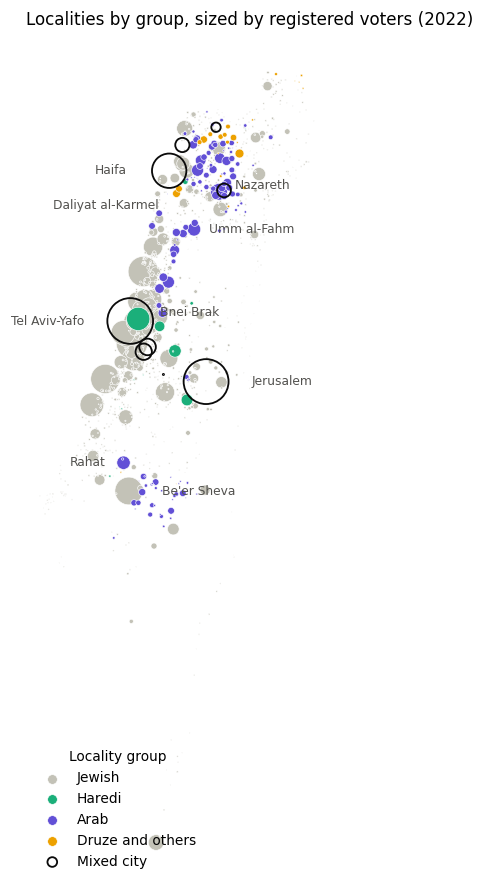

In [6]:
LABELS = {3000: ("Jerusalem", 30, 0), 5000: ("Tel Aviv-Yafo", -30, 0), 6100: ("Bnei Brak", 14, 4),
          4000: ("Haifa", -28, 0), 494: ("Daliyat al-Karmel", -12, -8), 7300: ("Nazareth", 10, 4),
          2710: ("Umm al-Fahm", 10, 0), 1161: ("Rahat", -12, 0), 9000: ("Be'er Sheva", 22, 0)}   # name, label offset (points)

on_map = localities.dropna(subset=["x_itm", "registered_2022"]).sort_values("registered_2022", ascending=False)
area = on_map["registered_2022"] / 500

fig, ax = plt.subplots(figsize=(6.5, 10))
for group, colour in GROUP_COLORS.items():
    g = on_map["group"] == group
    ax.scatter(on_map.loc[g, "x_itm"], on_map.loc[g, "y_itm"], s=area[g], color=colour,
               edgecolor="white", linewidth=0.4, label=group)
mixed = on_map["group"] == "Mixed city"
ax.scatter(on_map.loc[mixed, "x_itm"], on_map.loc[mixed, "y_itm"], s=area[mixed], facecolor="none",
           edgecolor="#0b0b0b", linewidth=1.2, label="Mixed city")
for locality, (label, dx, dy) in LABELS.items():
    x, y = on_map.loc[locality, ["x_itm", "y_itm"]]
    ax.annotate(label, (x, y), xytext=(dx, dy), textcoords="offset points", fontsize=8, color="#52514e",
                va="center", ha="left" if dx > 0 else "right")

ax.set_aspect("equal")
ax.axis("off")
legend = ax.legend(loc="lower left", frameon=False, fontsize=9, title="Locality group", title_fontsize=9)
for handle in legend.legend_handles:
    handle.set_sizes([40])
ax.set_title("Localities by group, sized by registered voters (2022)", fontsize=11, loc="left")
plt.show()

## 3. What the past tells us

Four questions about 2013–2022, each of which shapes a choice in the model:

1. How much does turnout move, and in which groups?
2. How do the party families' votes move?
3. How often does a list land near the threshold?
4. Does each family's geography stay put from one election to the next?

In [7]:
ELECTIONS["label"] = ["2013", "2015", "Apr 2019", "Sep 2019", "2020", "2021", "2022"]
ELECTIONS["short"] = ["'13", "'15", "'19a", "'19b", "'20", "'21", "'22"]
x = np.arange(len(ELECTIONS))

### 3.1 Turnout by group

Turnout here is ballots cast at the ballot boxes divided by registered voters. It leaves out the double envelopes
(5–10% of all ballots, mostly soldiers and other Jewish voters away from home), so the Jewish sector's true turnout
is a few points higher. Section 6 splits the envelopes between the sectors.

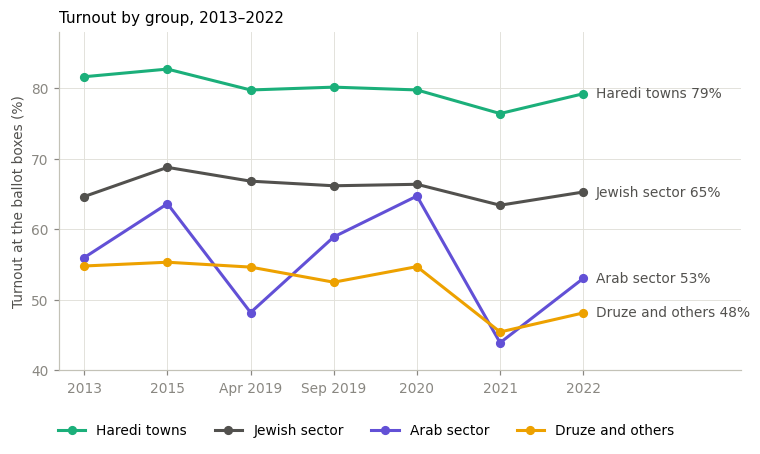

series,Haredi towns,Jewish sector,Arab sector,Druze and others
label,,,,
2013,81.6,64.6,56.0,54.8
2015,82.7,68.8,63.6,55.3
Apr 2019,79.7,66.8,48.2,54.6
Sep 2019,80.1,66.2,58.9,52.5
2020,79.7,66.4,64.7,54.7
2021,76.4,63.4,43.9,45.5
2022,79.2,65.3,53.0,48.2


In [8]:
TURNOUT_COLORS = {"Haredi towns": GROUP_COLORS["Haredi"], "Jewish sector": "#52514e",
                  "Arab sector": GROUP_COLORS["Arab"], "Druze and others": GROUP_COLORS["Druze and others"]}

series = pd.Series(np.select([boxes["group"].eq("Haredi"), boxes["group"].eq("Druze and others"), boxes["sector"].eq("Jewish")],
                             ["Haredi towns", "Druze and others", "Jewish sector"], default="Arab sector"),
                   index=boxes.index, name="series")
counts = boxes.groupby([boxes["election"], series])[["registered", "voted"]].sum()
turnout = (100 * counts["voted"] / counts["registered"]).unstack()[list(TURNOUT_COLORS)]

fig, ax = plt.subplots(figsize=(8, 4))
for name, colour in TURNOUT_COLORS.items():
    ax.plot(x, turnout[name], color=colour, marker="o", markersize=5, label=name)
    ax.annotate(f"{name} {turnout[name].iloc[-1]:.0f}%", (x[-1], turnout[name].iloc[-1]), xytext=(8, 0),
                textcoords="offset points", va="center", color="#52514e")
ax.set_xticks(x, ELECTIONS["label"])
ax.set_xlim(-0.3, len(x) + 0.9)
ax.set_ylim(40, 88)
ax.set_ylabel("Turnout at the ballot boxes (%)")
ax.set_title("Turnout by group, 2013–2022")
ax.legend(loc="upper center", bbox_to_anchor=(0.45, -0.12), ncol=4)
plt.show()

turnout.set_index(ELECTIONS["label"]).round(1)

- **Arab turnout is the volatile one.** It moves by 21 points, from 43.9% (2021) to 64.7% (2020). It was highest when
  the Arab parties ran together as the Joint List (2015, September 2019, 2020) and lowest when they split (April 2019,
  2021).
- **Jewish turnout is steady**, within five points (63.4–68.8%), and the Haredi towns vote at 76–83% every time.
- **The Druze and others vote at 45–55% whatever the Arab parties do**, so their gap to the Arab sector opens and
  closes with Arab turnout.

So Arab turnout gets its own model and wide uncertainty (section 6).

### 3.2 The party families over time

Each family's share of the national valid vote. The last panel is the share lost below the threshold.

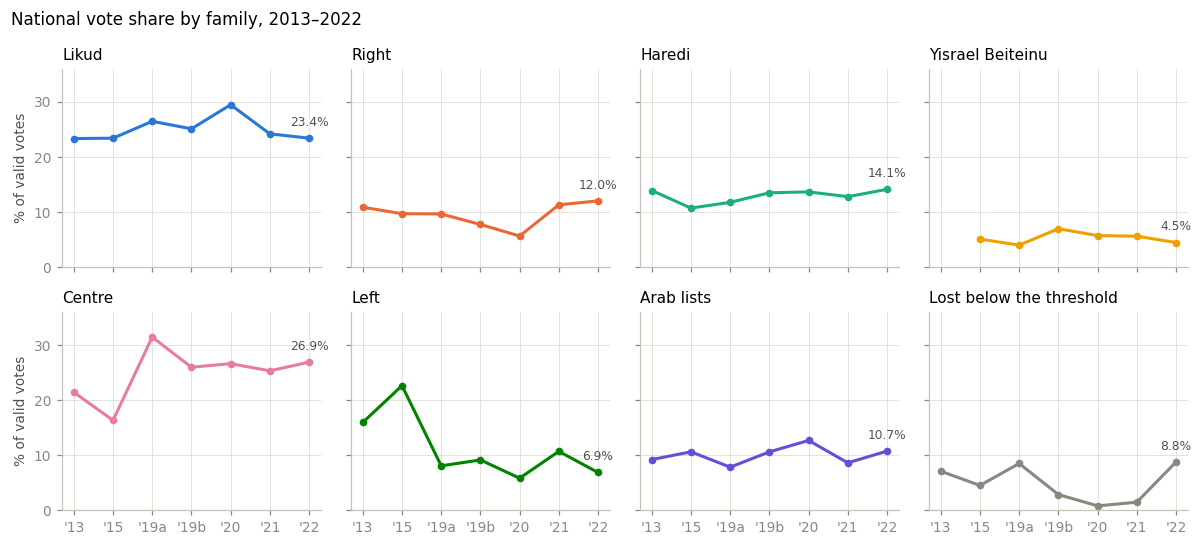

label,2013,2015,Apr 2019,Sep 2019,2020,2021,2022
family,,,,,,,
Likud,23.3% (31),23.4% (30),26.5% (35),25.1% (32),29.5% (36),24.2% (30),23.4% (32)
Right,10.9% (12),9.7% (8),9.7% (5),7.8% (7),5.7% (6),11.3% (13),12.0% (14)
Haredi,13.9% (18),10.7% (13),11.8% (16),13.5% (16),13.7% (16),12.8% (16),14.1% (18)
Yisrael Beiteinu,with Likud,5.1% (6),4.0% (5),7.0% (8),5.7% (7),5.6% (7),4.5% (6)
Centre,21.4% (27),16.3% (21),31.4% (39),25.9% (33),26.6% (33),25.3% (31),26.9% (36)
Left,15.9% (21),22.6% (29),8.1% (10),9.1% (11),5.8% (7),10.7% (13),6.9% (4)
Arab lists,9.2% (11),10.6% (13),7.8% (10),10.6% (13),12.7% (15),8.6% (10),10.7% (10)


In [9]:
shares = list_votes.pivot_table(index="election", columns="family", values="share_pct", aggfunc="sum")[FAMILIES]
seats = list_votes.pivot_table(index="election", columns="family", values="seats", aggfunc="sum")[FAMILIES]
shares.loc["K19", "Yisrael Beiteinu"] = np.nan   # in 2013 it ran on one list with Likud

fig, axes = plt.subplots(2, 4, figsize=(11, 5), sharex=True, sharey=True)
panels = [(f, shares[f], FAMILY_COLORS[f]) for f in FAMILIES[:-1]]
panels.append(("Lost below the threshold", national["below_threshold_pct"], FAMILY_COLORS["Other"]))
for ax, (title, values, colour) in zip(axes.flat, panels):
    ax.plot(x, values, color=colour, marker="o", markersize=4)
    ax.annotate(f"{values.iloc[-1]:.1f}%", (x[-1], values.iloc[-1]), xytext=(0, 8), textcoords="offset points",
                ha="center", color="#52514e", fontsize=8)
    ax.set_title(title)
    ax.set_xticks(x, ELECTIONS["short"])
    ax.set_ylim(0, 36)
for ax in axes[:, 0]:
    ax.set_ylabel("% of valid votes")
fig.suptitle("National vote share by family, 2013–2022", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
plt.show()

table = shares.round(1).astype(str) + "% (" + seats.fillna(0).astype(int).astype(str) + ")"
table.loc["K19", "Yisrael Beiteinu"] = "with Likud"
table.set_index(ELECTIONS["label"]).T.drop("Other")

The table gives each family's vote share and, in brackets, its seats.

- **The centre and the left trade places.** The left fell from 22.6% (2015) to 6.9% (2022); the centre peaked at 31.4%
  with Blue and White in April 2019. The families in the middle of the spectrum are where parties merge, split and
  rename.
- **Likud moves within 23–30%, and the Haredi parties are the steadiest**, between 10.7% and 14.1%.
- **The Arab lists follow Arab turnout**: 7.8% in April 2019, 12.7% in 2020.

### 3.3 The threshold

Every list with between 1% and 6% of the vote. Filled dots passed the threshold (the dashed line), open dots did not.

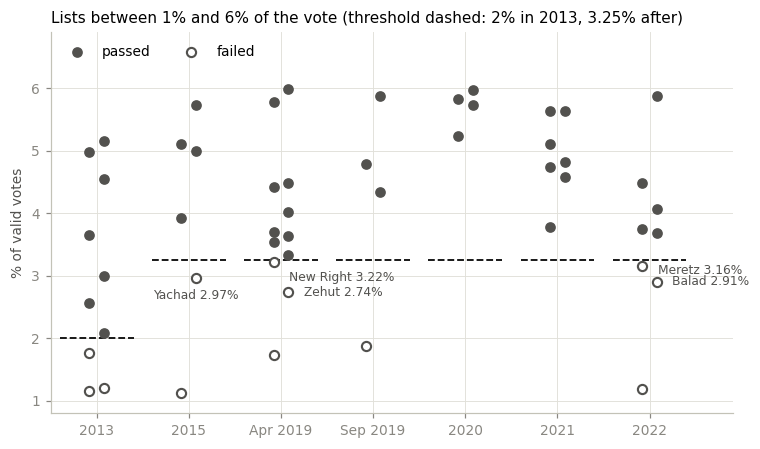

,election,list,share_pct,margin,passed
31,2013,Other: קנ,1.15,-0.85,False
27,2013,Other: ץ,1.20,-0.80,False
17,2013,Otzma LeYisrael,1.76,-0.24,False
12,2013,Kadima,2.08,0.08,True
2,2013,Balad,2.56,0.56,True
6,2013,Hadash,2.99,0.99,True
57,2015,Yachad,2.97,-0.28,False
48,2015,Meretz,3.93,0.68,True
64,Apr 2019,Zehut,2.74,-0.51,False
79,Apr 2019,New Right,3.22,-0.03,False


In [10]:
near = list_votes[list_votes["share_pct"].between(1, 6)].copy()
near["threshold"] = near["election"].map(ELECTIONS["threshold_pct"])
near["margin"] = near["share_pct"] - near["threshold"]
rank = near.groupby("election")["share_pct"].rank()
near["x"] = near["election"].map(dict(zip(ELECTIONS.index, x))) + np.where(rank % 2, -0.08, 0.08)   # dodge neighbours

LABELLED = {("K20", "Yachad"): (0, -12, "center"), ("K21", "Zehut"): (10, 0, "left"),
            ("K21", "New Right"): (10, -10, "left"), ("K25", "Meretz"): (10, -3, "left"),
            ("K25", "Balad"): (10, 0, "left")}   # label offset (points) and alignment

fig, ax = plt.subplots(figsize=(8, 4.5))
for i, e in enumerate(ELECTIONS.index):
    ax.hlines(ELECTIONS.loc[e, "threshold_pct"], i - 0.4, i + 0.4, color="#0b0b0b", linewidth=1.2, linestyle="--")
passed = near[near["passed"]]
failed = near[~near["passed"]]
ax.scatter(passed["x"], passed["share_pct"], s=36, color="#52514e", zorder=3, label="passed")
ax.scatter(failed["x"], failed["share_pct"], s=36, facecolor="white", edgecolor="#52514e", linewidth=1.4,
           zorder=3, label="failed")
for (e, name), (dx, dy, ha) in LABELLED.items():
    row = near[(near["election"] == e) & (near["list"] == name)].iloc[0]
    ax.annotate(f"{name} {row['share_pct']:.2f}%", (row["x"], row["share_pct"]), xytext=(dx, dy),
                textcoords="offset points", ha=ha, va="center", fontsize=8, color="#52514e")
ax.set_xticks(x, ELECTIONS["label"])
ax.set_xlim(-0.5, len(x) - 0.1)
ax.set_ylim(0.8, 6.9)
ax.set_ylabel("% of valid votes")
ax.set_title("Lists between 1% and 6% of the vote (threshold dashed: 2% in 2013, 3.25% after)")
ax.legend(loc="upper left", ncol=2)
plt.show()

close = near[near["margin"].abs() <= 1].sort_values(["election", "share_pct"])
close.assign(election=close["election"].map(ELECTIONS["label"]))[["election", "list", "share_pct", "margin", "passed"]].round(2)

The table lists every list within one point of the threshold, either side. Only September 2019 and 2020 had none:

- **8 lists missed by less than a point**, including Otzma LeYisrael (2013), Yachad (2015), New Right and Zehut
  (April 2019), and Balad and Meretz (2022). The two unnamed 2013 lists, shown by their ballot letters, are small
  lists that won no seats.
- **13 passed with less than a point to spare**, five of them in April 2019 alone.
- **The closest calls:** New Right missed by 0.03 points and Meretz by 0.09; Kadima (2013) and Ra'am-Balad (April
  2019) passed by 0.08.

A list that misses takes about four seats' worth of votes out of the count, and every other list gains. So the model
cannot fix a list's pass or fail in advance: it has to simulate it, election by election.

### 3.4 Does each family's geography stay put?

If the places where a family is strong change little between elections, a forecast can start from the past map and
only move the national levels. The test: the correlation of each family's share across the same places in two
consecutive elections, weighted by votes. The Jewish families are compared across Jewish-sector places, the Arab
lists across Arab-sector places. Places with fewer than 50 valid votes are left out.

Localities can be followed across all seven elections; polling places only from September 2019, when the CEC started
to publish a stable polling-place code.

In [11]:
MIN_VALID = 50


def weighted_corr(a, b, w):
    ma, mb = np.average(a, weights=w), np.average(b, weights=w)
    va, vb = np.average((a - ma) ** 2, weights=w), np.average((b - mb) ** 2, weights=w)
    if va == 0 or vb == 0:
        return np.nan
    return np.average((a - ma) * (b - mb), weights=w) / np.sqrt(va * vb)


def paired(units, keys, before, after):
    """The same units at two elections side by side, both with at least MIN_VALID valid votes."""
    a = units[units["election"] == before].set_index(keys)
    b = units[units["election"] == after].set_index(keys)
    pair = a.join(b, lsuffix="_before", rsuffix="_after", how="inner")
    return pair[(pair["valid_before"] >= MIN_VALID) & (pair["valid_after"] >= MIN_VALID)]


def in_sector(pair, family):
    return pair[pair.index.get_level_values("sector") == ("Arab" if family == "Arab lists" else "Jewish")]


def stability(units, keys, pairs):
    table = {}
    for before, after in pairs:
        pair = paired(units, keys, before, after)
        column = {}
        for f in FAMILIES[:-1]:
            p = in_sector(pair, f)
            column[f] = weighted_corr(p[f"{f}_before"] / p["valid_before"], p[f"{f}_after"] / p["valid_after"],
                                      p["valid_after"])
        table[f"{ELECTIONS.loc[before, 'short']} → {ELECTIONS.loc[after, 'short']}"] = column
    return pd.DataFrame(table)


locality_units = (towns[towns["group"].isin(["Jewish", "Haredi", "Arab", "Druze and others"])]
                  .assign(sector=lambda d: np.where(d["group"].isin(["Arab", "Druze and others"]), "Arab", "Jewish")))
place_units = (boxes[boxes["place"].notna()]
               .groupby(["election", "locality_code", "place", "sector"], as_index=False)[["valid"] + FAMILIES].sum())

consecutive = list(zip(ELECTIONS.index[:-1], ELECTIONS.index[1:]))
by_locality = stability(locality_units, ["locality_code", "sector"], consecutive)
by_place = stability(place_units, ["locality_code", "place", "sector"], consecutive[3:])

print("Between localities")
display(by_locality.round(2))
print("Between polling places")
display(by_place.round(2))

Between localities


,'13 → '15,'15 → '19a,'19a → '19b,'19b → '20,'20 → '21,'21 → '22
Likud,0.92,0.98,0.99,0.99,0.99,0.99
Right,0.97,0.98,0.99,0.99,0.98,0.98
Haredi,0.99,1.00,1.00,1.00,1.00,1.00
Yisrael Beiteinu,NaN,0.99,0.97,0.99,0.99,0.99
Centre,0.88,0.79,0.99,0.99,0.97,0.99
Left,0.97,0.93,0.99,0.99,0.98,0.99
Arab lists,0.94,0.93,0.94,0.97,0.98,0.98


Between polling places


,'19b → '20,'20 → '21,'21 → '22
Likud,0.99,0.98,0.98
Right,0.99,0.97,0.97
Haredi,1.00,0.99,1.00
Yisrael Beiteinu,0.99,0.97,0.97
Centre,0.99,0.97,0.98
Left,0.98,0.97,0.99
Arab lists,0.96,0.97,0.97


Between localities, every correlation but two is 0.92 or more; between polling places, all are 0.96 or more. Both
exceptions are the centre: 0.88 from 2013 to 2015, and 0.79 from 2015 to April 2019, when Blue and White was founded
and drew voters from new places. A family's map changes when its parties change, and otherwise barely moves.

High correlations partly reflect how different places are (the Haredi share runs from almost 0 to 97%). The
scatter plots show the other half: from 2021 to 2022, polling places sit close to a line, with any change a shift
of the whole cloud.

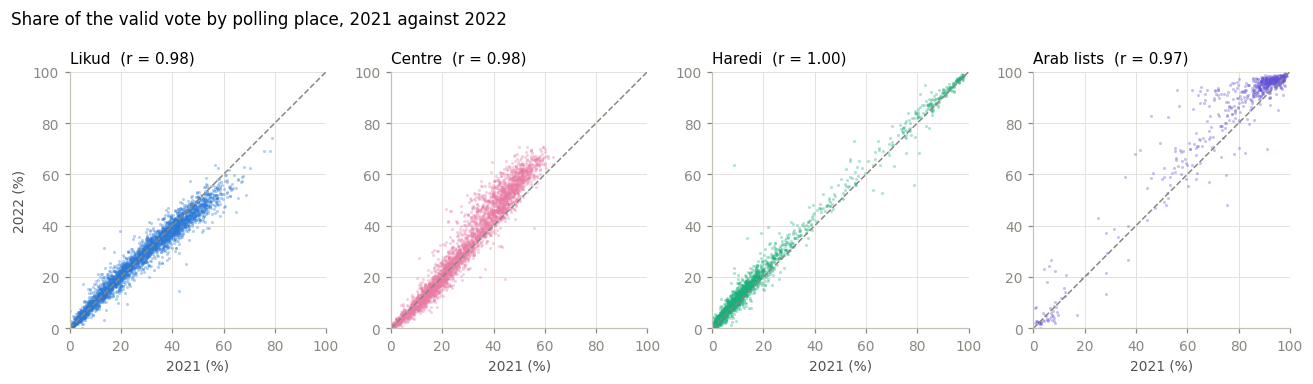

In [12]:
pair = paired(place_units, ["locality_code", "place", "sector"], "K24", "K25")
r = by_place["'21 → '22"]

fig, axes = plt.subplots(1, 4, figsize=(12, 3.4))
for ax, f in zip(axes, ["Likud", "Centre", "Haredi", "Arab lists"]):
    p = in_sector(pair, f)
    before = 100 * p[f"{f}_before"] / p["valid_before"]
    after = 100 * p[f"{f}_after"] / p["valid_after"]
    ax.scatter(before, after, s=4, alpha=0.35, color=FAMILY_COLORS[f], linewidth=0)
    ax.plot([0, 100], [0, 100], color="#898781", linewidth=1, linestyle="--")
    ax.set(xlim=(0, 100), ylim=(0, 100), aspect="equal", xlabel="2021 (%)")
    ax.set_title(f"{f}  (r = {r[f]:.2f})")
axes[0].set_ylabel("2022 (%)")
fig.suptitle("Share of the valid vote by polling place, 2021 against 2022", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
plt.show()

So a polling place's past vote is a good guide to its next one, which is what the flow model of section 6.6 uses.
What moves between elections is mostly the national level, which is what the polls measure.

### 3.5 What this means for the model

| Finding | Consequence |
|---|---|
| Arab turnout swings by 20 points, Jewish turnout by 5 | Arab turnout gets its own model and the widest uncertainty |
| A family's map barely changes; its national level does | A flow model carries each polling place's vote forward (6.6); the polls give today's level |
| Lists often land within a point of the threshold | Simulate each list's pass or fail in every draw |
| The centre-left trades voters through mergers and new parties | Expect larger poll errors there than for Likud, the Haredi parties or the Arab lists (tested in section 5) |

Next: the seat rule. Bader-Ofer with surplus agreements, tested against the official seats of every election.

## 4. The seat rule

Votes become seats in three steps (Knesset Elections Law, section 81):

1. **Threshold.** Lists under the threshold are removed.
2. **Seats between units.** The 120 seats are shared by the **D'Hondt** method (largest averages): each seat in turn
   goes to the unit with the highest votes ÷ (seats already won + 1). Each list is a unit, except that two lists with
   a **surplus agreement** count as one unit.
3. **Seats inside a pair.** A pair's seats are split between its two lists by the same method.

Israel calls this the Bader-Ofer method. An agreement only moves the last seat or two, but in a close race that can
decide the majority.

In [13]:
def dhondt(votes, seats):
    """Largest averages: each seat in turn goes to the highest votes / (seats already won + 1)."""
    won = np.zeros(len(votes), dtype=int)
    for _ in range(seats):
        won[np.argmax(votes / (won + 1))] += 1
    return won


def bader_ofer(votes, agreements=(), threshold_pct=3.25, seats=120):
    """Seats per list. votes: valid votes per list (a Series); agreements: pairs of list names."""
    passed = 100 * votes / votes.sum() >= threshold_pct
    counted = votes.where(passed, 0).astype(float)
    unit = pd.Series(votes.index, index=votes.index)    # each list is its own unit...
    for a, b in agreements:                             # ...except the two lists of a surplus agreement
        if a in unit and b in unit:
            unit[[a, b]] = f"{a} + {b}"
    unit_votes = counted.groupby(unit).sum()
    unit_seats = dict(zip(unit_votes.index, dhondt(unit_votes.to_numpy(), seats)))
    result = pd.Series(0, index=votes.index)
    for u, members in unit.groupby(unit).groups.items():
        result[members] = dhondt(counted[members].to_numpy(), unit_seats[u])
    return result

A list under the threshold counts as zero votes, so an agreement with a list that failed changes nothing: the
partner keeps its own seats.

### 4.1 The surplus agreements, 2013–2022

The agreements each election's lists signed, from the Hebrew Wikipedia page of each election (section
"הסכמי עודפים"). Agreements between two lists that both failed the threshold are left out, since they could not move
a seat. Where a partner failed and is not among the main lists (Am Shalem in 2013, the New Economic Party in 2021,
Noam in September 2019), it is listed anyway and has no effect.

In [14]:
AGREEMENTS = {
    "K19": [("Likud Yisrael Beiteinu", "Jewish Home"), ("Labor", "Yesh Atid"), ("Hatnua", "Meretz"),
            ("Shas", "United Torah Judaism"), ("Hadash", "Balad"), ("Kadima", "Am Shalem")],
    "K20": [("Likud", "Jewish Home"), ("Zionist Union", "Meretz"), ("Yisrael Beiteinu", "Kulanu"),
            ("Shas", "United Torah Judaism")],
    "K21": [("Likud", "Union of Right-Wing Parties"), ("Labor", "Meretz"), ("New Right", "Yisrael Beiteinu"),
            ("Hadash-Ta'al", "Ra'am-Balad"), ("Shas", "United Torah Judaism")],
    "K22": [("Likud", "Yamina"), ("Blue and White", "Yisrael Beiteinu"), ("Labor-Gesher", "Democratic Camp"),
            ("Shas", "United Torah Judaism"), ("Otzma Yehudit", "Noam")],
    "K23": [("Likud", "Yamina"), ("Blue and White", "Labor-Gesher-Meretz"), ("Shas", "United Torah Judaism")],
    "K24": [("Likud", "Religious Zionism"), ("Yesh Atid", "Yisrael Beiteinu"), ("Yamina", "New Hope"),
            ("Labor", "Meretz"), ("Blue and White", "New Economic Party"), ("Shas", "United Torah Judaism")],
    "K25": [("Likud", "Religious Zionism"), ("Yesh Atid", "National Unity"), ("Labor", "Meretz"),
            ("Shas", "United Torah Judaism")],
}

### 4.2 Test: does the rule give the official seats?

Each election is run twice, without and with the agreements, and compared with the CEC's official seats.

In [15]:
def seats_moved(computed, official):
    return int((computed - official).abs().sum() // 2)


rows, differences = [], {}
for e in ELECTIONS.index:
    lv = list_votes[list_votes["election"] == e].set_index("list")
    threshold = ELECTIONS.loc[e, "threshold_pct"]
    without = bader_ofer(lv["votes"], (), threshold)
    with_agreements = bader_ofer(lv["votes"], AGREEMENTS[e], threshold)
    rows.append({"seats moved without agreements": seats_moved(without, lv["seats"]),
                 "seats moved with agreements": seats_moved(with_agreements, lv["seats"])})
    gap = (without - lv["seats"])[lambda s: s != 0]
    differences[ELECTIONS.loc[e, "label"]] = ", ".join(f"{name} {d:+d}" for name, d in gap.items())

test = pd.DataFrame(rows, index=ELECTIONS["label"])
test["without agreements, against the official seats"] = pd.Series(differences)
assert (test["seats moved with agreements"] == 0).all()
test

,seats moved without agreements,seats moved with agreements,"without agreements, against the official seats"
label,,,
2013,0,0,
2015,1,0,"Joint List +1, Kulanu -1"
Apr 2019,1,0,"United Torah Judaism -1, Likud +1"
Sep 2019,0,0,
2020,0,0,
2021,1,0,"Likud +1, Meretz -1"
2022,1,0,"Labor +1, Likud -1"


With the agreements the rule reproduces every official seat in all seven elections. Without them, four elections
come out one seat wrong. In 2022 Labor would have had 5 seats and Likud 31; Likud's agreement with Religious Zionism
pooled their remainders and took the last seat, which moved it across the blocs.

### 4.3 What one list at the threshold can do

A list that passes wins at least four seats, so the lists near the threshold matter far beyond their
size. Two 2022 counterfactuals show it, each moving
votes inside a family so that the total stays the same:

- **Meretz passes**: 4,062 votes move from Labor to Meretz (0.09% of the vote), which lifts Meretz to 3.25%.
- **Balad passes**: 16,238 votes move from Hadash-Ta'al to Balad.

The Netanyahu bloc of 2022 is Likud, Religious Zionism, Shas and United Torah Judaism.

In [16]:
NETANYAHU_2022 = ["Likud", "Religious Zionism", "Shas", "United Torah Judaism"]
votes_2022 = list_votes[list_votes["election"] == "K25"].set_index("list")["votes"]


def lift_to_threshold(votes, lifted, donor):
    """Move just enough votes from donor to lifted for lifted to reach 3.25%."""
    moved = int(np.ceil(0.0325 * votes.sum())) - votes[lifted]
    return votes.add(pd.Series({lifted: moved, donor: -moved}), fill_value=0), moved


meretz_votes, meretz_moved = lift_to_threshold(votes_2022, "Meretz", "Labor")
balad_votes, balad_moved = lift_to_threshold(votes_2022, "Balad", "Hadash-Ta'al")
scenarios = pd.DataFrame({
    "actual": bader_ofer(votes_2022, AGREEMENTS["K25"]),
    f"Meretz passes (+{meretz_moved:,} votes)": bader_ofer(meretz_votes, AGREEMENTS["K25"]),
    f"Balad passes (+{balad_moved:,} votes)": bader_ofer(balad_votes, AGREEMENTS["K25"]),
})
scenarios = scenarios[(scenarios > 0).any(axis=1)].sort_values("actual", ascending=False)
scenarios.loc["Netanyahu bloc"] = scenarios.loc[NETANYAHU_2022].sum()
scenarios

,actual,"Meretz passes (+4,062 votes)","Balad passes (+16,238 votes)"
list,,,
Likud,32,30,31
Yesh Atid,24,23,23
Religious Zionism,14,14,14
National Unity,12,12,12
Shas,11,11,11
United Torah Judaism,7,7,7
Yisrael Beiteinu,6,5,5
Hadash-Ta'al,5,4,4
Ra'am,5,5,5


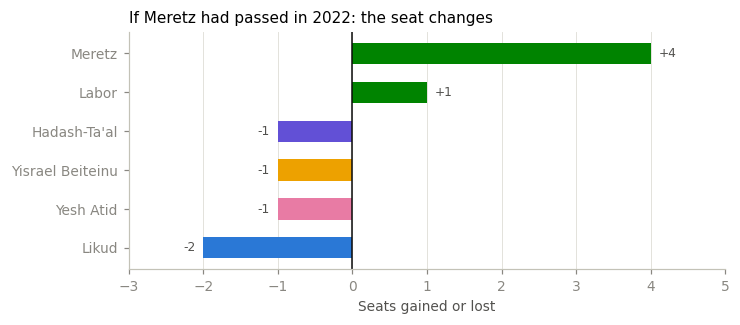

In [17]:
seat_change = (scenarios.iloc[:, 1] - scenarios["actual"]).drop("Netanyahu bloc")
seat_change = seat_change[seat_change != 0].sort_values()
family_2022 = list_votes[list_votes["election"] == "K25"].set_index("list")["family"]

fig, ax = plt.subplots(figsize=(7, 2.8))
ax.barh(seat_change.index, seat_change, height=0.55, color=[FAMILY_COLORS[family_2022[n]] for n in seat_change.index])
ax.axvline(0, color="#0b0b0b", linewidth=1)
for y, value in enumerate(seat_change):
    ax.annotate(f"{value:+d}", (value, y), xytext=(5 if value > 0 else -5, 0), textcoords="offset points",
                ha="left" if value > 0 else "right", va="center", fontsize=8, color="#52514e")
ax.set_xlim(-3, 5)
ax.grid(axis="y", visible=False)
ax.set(xlabel="Seats gained or lost", title="If Meretz had passed in 2022: the seat changes")
plt.show()

0.09% of the vote, moved inside the left, takes the Netanyahu bloc from 64 seats to 62. Meretz's four seats come
mostly from Likud (−2), Yesh Atid, Yisrael Beiteinu and Hadash-Ta'al (−1 each); Labor gains a seat because its
agreement with Meretz now counts. Balad passing costs the bloc one seat.

### 4.4 A fast version for the simulation

`bader_ofer` takes about 10 milliseconds per election, so 10,000 simulated elections would take minutes. The
simulation in section 7 uses a vectorised version that counts all draws at once. D'Hondt gives a unit as many seats
as it has quotients (votes ÷ 1, ÷ 2, ÷ 3 …) among the 120 largest, so the fast version computes every quotient,
finds the 120th largest per draw, and counts.

A list that fails the threshold has zero votes, so its agreement unit is simply its partner. That is why the units
can be fixed in advance, whatever passes in each draw.

In [18]:
def top_quotients(votes, seats):
    """D'Hondt for many rows at once. votes: (draws, parties); seats: (draws,) -> seats per party."""
    if seats.max() == 0:
        return np.zeros(votes.shape, dtype=int)
    quotients = votes[:, :, None] / np.arange(1, seats.max() + 1)
    ranked = -np.sort(-quotients.reshape(len(votes), -1), axis=1)
    cutoff = ranked[np.arange(len(votes)), np.maximum(seats - 1, 0)]
    won = (quotients >= cutoff[:, None, None]).sum(axis=2)
    return np.where(seats[:, None] > 0, won, 0)


def agreement_units(lists, agreements):
    """A unit number per list; the two lists of an agreement share one."""
    unit = {name: name for name in lists}
    for a, b in agreements:
        if a in unit and b in unit:
            unit[b] = unit[a]
    return pd.factorize(pd.Series([unit[name] for name in lists]))[0]


def bader_ofer_fast(votes, units, threshold_pct=3.25, seats=120, chunk=2_000):
    """Seats for many elections. votes: (draws, lists); units: from agreement_units."""
    votes = np.asarray(votes, dtype=float)
    counted = np.where(100 * votes / votes.sum(axis=1, keepdims=True) >= threshold_pct, votes, 0.0)
    membership = np.eye(units.max() + 1)[units]                  # (lists, units)
    result = np.zeros(counted.shape, dtype=int)
    for start in range(0, len(counted), chunk):
        part = counted[start:start + chunk]
        unit_seats = top_quotients(part @ membership, np.full(len(part), seats))
        for u in range(membership.shape[1]):
            cols = np.flatnonzero(units == u)
            if len(cols) == 1:
                result[start:start + chunk, cols[0]] = unit_seats[:, u]
            else:
                result[start:start + chunk, cols] = top_quotients(part[:, cols], unit_seats[:, u])
    return result

The test: the fast version must give exactly the reference seats, first for the seven elections, then for 500
random elections built by shaking the 2022 votes (each list's votes times a random factor of about ±30%), so that
lists cross the threshold in both directions.

In [19]:
for e in ELECTIONS.index:
    lv = list_votes[list_votes["election"] == e].set_index("list")
    fast = bader_ofer_fast(lv["votes"].to_numpy()[None, :], agreement_units(lv.index, AGREEMENTS[e]),
                           ELECTIONS.loc[e, "threshold_pct"])
    assert (fast[0] == lv["seats"].to_numpy()).all(), e

rng = np.random.default_rng(2026)
shaken = votes_2022.to_numpy() * rng.lognormal(0, 0.3, size=(500, len(votes_2022)))
units_2022 = agreement_units(votes_2022.index, AGREEMENTS["K25"])

start = pd.Timestamp.now()
reference = np.array([bader_ofer(pd.Series(row, index=votes_2022.index), AGREEMENTS["K25"]).to_numpy() for row in shaken])
reference_time = (pd.Timestamp.now() - start).total_seconds()
start = pd.Timestamp.now()
fast = bader_ofer_fast(shaken, units_2022)
fast_time = (pd.Timestamp.now() - start).total_seconds()

assert (fast == reference).all() and (fast.sum(axis=1) == 120).all()
crossings = ((100 * shaken / shaken.sum(axis=1, keepdims=True) >= 3.25) != (votes_2022 / votes_2022.sum() >= 0.0325).to_numpy()).any(axis=1)
print(f"500 random elections: identical seats in all of them; {crossings.mean():.0%} had a list cross the threshold")
print(f"reference {reference_time:.1f} s, fast {fast_time:.3f} s ({reference_time / fast_time:,.0f} times faster)")

500 random elections: identical seats in all of them; 91% had a list cross the threshold
reference 5.3 s, fast 0.020 s (261 times faster)


Next: the polls, and how the final polls of 2013–2022 compared with the results.

## 5. The polls and how they missed

The forecast starts from the polls, so the first question is how good the polls have been. This section uses the
published polls of the seven campaigns of 2013–2022 (seats per list, `data/polls/`) to measure:

- how far the final-week poll average missed, list by list and family by family;
- whether any family is missed in the same direction election after election, so that a correction is justified;
- which way of averaging the polls worked best;
- how large an error the simulation should draw.

One rule holds for all of it: **the polls are compared with the vote, not with the seats as they fell.** Seats depend
on which lists failed the threshold. In 2022 Meretz and Balad fell just under it, six points of the vote were lost,
and every other list won more seats than its vote alone would have given: the Netanyahu bloc's 64 seats were 3.4
above the polls, but its share of the vote was only 1.3 points above them. So each poll's seats are turned into
the vote shares they imply (seats + ½, scaled so that the lists compared add up to their actual total; 7.2
explains the half seat) and set against the official shares, in points of the valid vote. One seat is worth about
0.8 points.

It ends with the 2026 polls and their average, the starting point of the forecast.

In [20]:

PAST = list(ELECTIONS.index)       # the seven elections with results, 2013-2022
polls = {e: pd.read_csv(DATA / "polls" / f"polls_{e.lower()}.csv", encoding="utf-8-sig", parse_dates=["date"])
         for e in PAST + ["K26"]}
for d in polls.values():
    d["pollster"] = d["pollster_en"]

LISTS_2026 = pd.read_csv(DATA / "lists_2026.csv", keep_default_na=False).set_index("key")

# each poll column -> the list it stood for on election day. Only the columns of the final line-up are read, so a
# column that changes meaning during a campaign (Likud before it joined Yisrael Beiteinu in 2012) is left out
POLL_LISTS = {
    "K19": {"likud_beiteinu": "Likud Yisrael Beiteinu", "yesh_atid": "Yesh Atid", "labor": "Labor",
            "jewish_home_nu": "Jewish Home", "shas": "Shas", "utj": "United Torah Judaism", "hatnua": "Hatnua",
            "meretz": "Meretz", "ual_taal": "Ra'am-Ta'al", "hadash": "Hadash", "balad": "Balad", "kadima": "Kadima",
            "otzma": "Otzma LeYisrael", "am_shalem": "Other: ץ"},
    "K20": {"likud": "Likud", "zionist_union": "Zionist Union", "joint_list": "Joint List", "yesh_atid": "Yesh Atid",
            "kulanu": "Kulanu", "jewish_home": "Jewish Home", "shas": "Shas", "yisrael_beiteinu": "Yisrael Beiteinu",
            "utj": "United Torah Judaism", "meretz": "Meretz", "yachad": "Yachad"},
    "K21": {"likud": "Likud", "blue_white": "Blue and White", "shas": "Shas", "utj": "United Torah Judaism",
            "hadash_taal": "Hadash-Ta'al", "labor": "Labor", "yisrael_beiteinu": "Yisrael Beiteinu",
            "urwp": "Union of Right-Wing Parties", "meretz": "Meretz", "kulanu": "Kulanu", "raam_balad": "Ra'am-Balad",
            "new_right": "New Right", "zehut": "Zehut", "gesher": "Gesher"},
    "K22": {"likud": "Likud", "blue_white": "Blue and White", "joint_list": "Joint List", "shas": "Shas",
            "utj": "United Torah Judaism", "yisrael_beiteinu": "Yisrael Beiteinu", "yamina": "Yamina",
            "labor_gesher": "Labor-Gesher", "democratic_union": "Democratic Camp", "otzma_yehudit": "Otzma Yehudit"},
    "K23": {"likud": "Likud", "blue_white": "Blue and White", "joint_list": "Joint List",
            "labor_gesher_meretz": "Labor-Gesher-Meretz", "shas": "Shas", "yisrael_beiteinu": "Yisrael Beiteinu",
            "utj": "United Torah Judaism", "yamina": "Yamina", "otzma_yehudit": "Otzma Yehudit"},
    "K24": {"likud": "Likud", "yesh_atid": "Yesh Atid", "shas": "Shas", "blue_white": "Blue and White",
            "yamina": "Yamina", "labor": "Labor", "utj": "United Torah Judaism", "yisrael_beiteinu": "Yisrael Beiteinu",
            "religious_zionism": "Religious Zionism", "joint_list": "Joint List", "new_hope": "New Hope",
            "meretz": "Meretz", "raam": "Ra'am", "economic_party": "Other: יז"},
    "K25": {"likud": "Likud", "yesh_atid": "Yesh Atid", "religious_zionism": "Religious Zionism",
            "national_unity": "National Unity", "shas": "Shas", "utj": "United Torah Judaism",
            "yisrael_beiteinu": "Yisrael Beiteinu", "raam": "Ra'am", "joint_list": "Hadash-Ta'al", "labor": "Labor",
            "meretz": "Meretz", "zionist_spirit": "Jewish Home"},
    "K26": LISTS_2026["list"].to_dict(),
}
for e in PAST:    # every column named is a list of that election, and every list that won seats is named
    names = set(POLL_LISTS[e].values())
    lv = list_votes[list_votes["election"] == e]
    assert names <= set(lv["list"]) and set(lv.loc[lv["seats"] > 0, "list"]) <= names, e

pd.DataFrame({ELECTIONS.loc[e, "label"] if e in ELECTIONS.index else "2026":
              {"polls": len(d), "pollsters": d["pollster"].nunique(),
               "first": d["date"].min().date(), "last": d["date"].max().date()}
              for e, d in polls.items()})

,2013,2015,Apr 2019,Sep 2019,2020,2021,2022,2026
polls,97,158,63,41,43,125,127,120
pollsters,14,13,10,8,7,8,7,10
first,2011-12-29,2014-02-11,2019-02-21,2019-07-30,2020-01-16,2020-08-06,2022-01-06,2026-07-29
last,2013-01-18,2015-03-13,2019-04-05,2019-09-13,2020-02-28,2021-03-19,2022-10-28,2026-10-21


### 5.1 How the final polls missed

The poll average is each pollster's last poll in the final week of the campaign, with equal weights (5.4 compares
it with other averages). A list a pollster leaves out of its table, or shows under the threshold without seats,
counts as 0 seats in that poll; a list that neither polled seats nor won any is not compared. The Netanyahu bloc is
the lists the pollsters counted with Likud in each campaign: Likud, the Haredi parties and the parties to Likud's
right, plus Yisrael Beiteinu in 2015 and April 2019 and Kulanu in April 2019. The chart shows seats, as the polls
print them; the errors in its titles and in the tables are in share points of the vote.

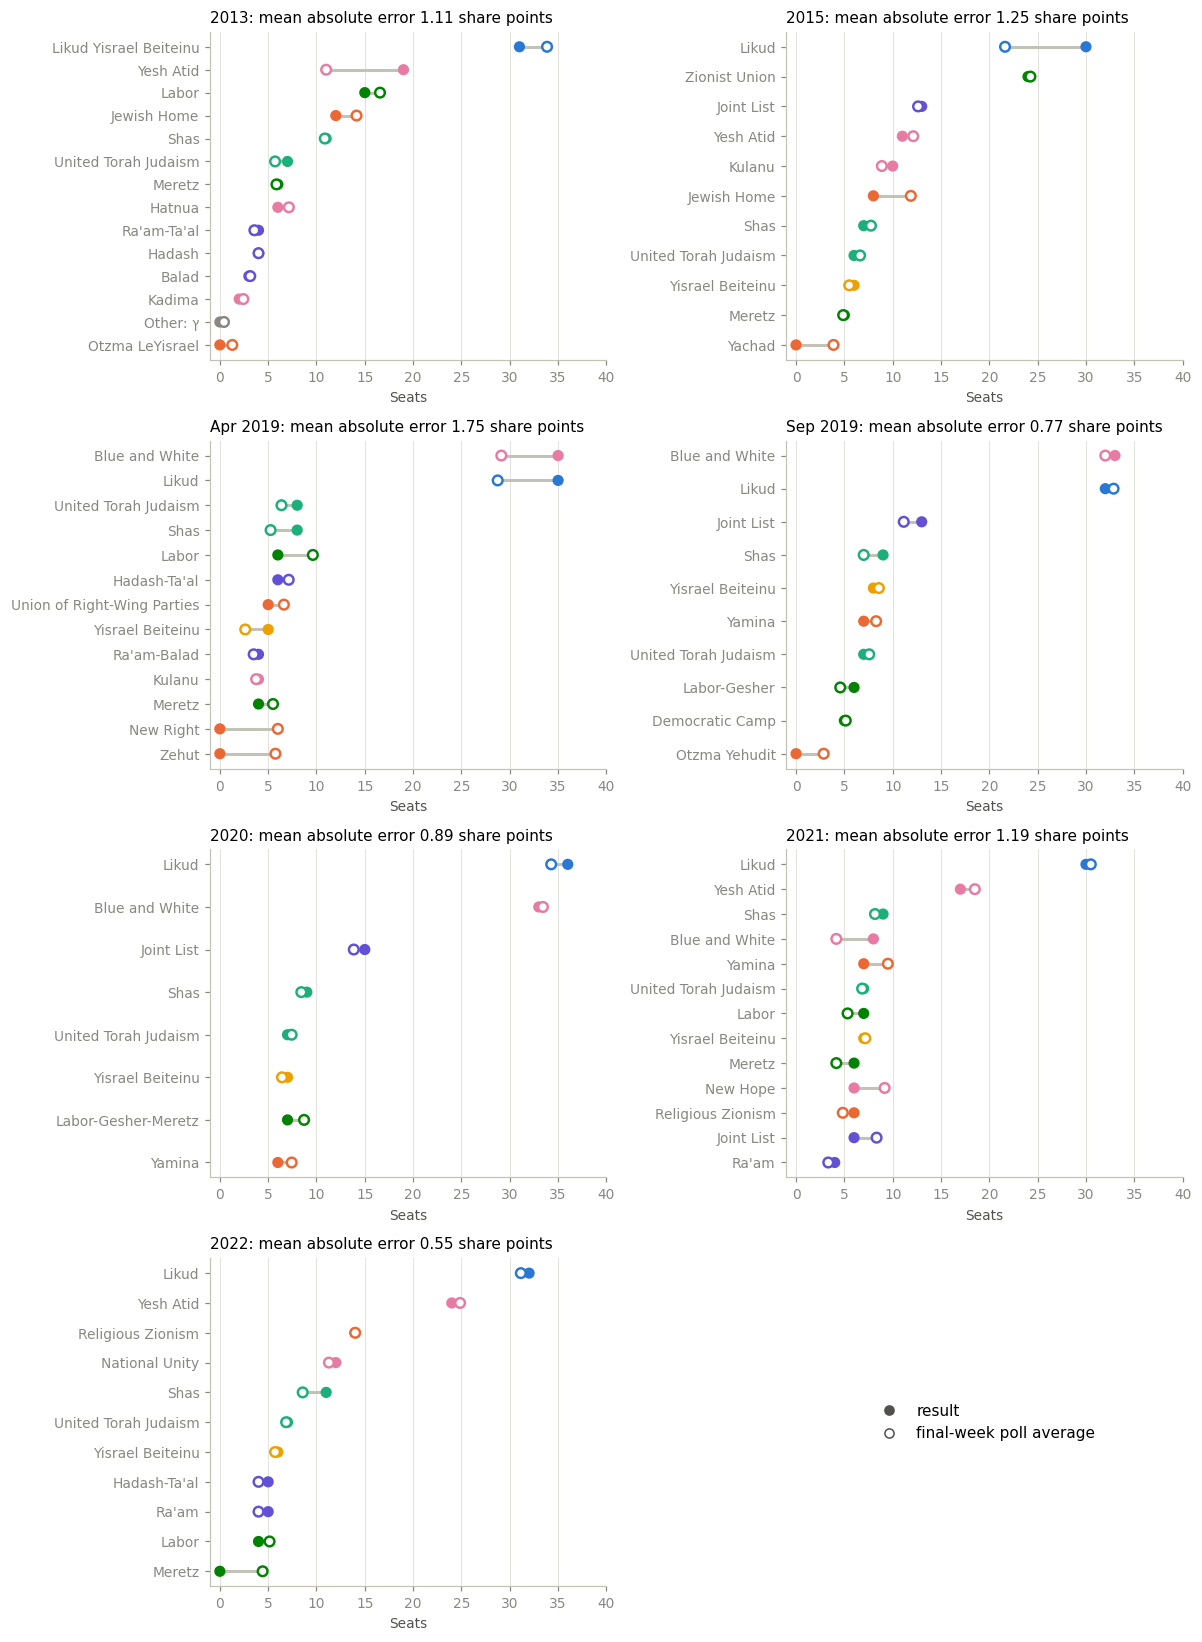

election,2013,2015,Apr 2019,Sep 2019,2020,2021,2022
"mean absolute error per list, share points",1.11,1.25,1.75,0.77,0.89,1.19,0.55
"mean absolute error per list, seats as they fell",1.43,1.91,3.02,1.26,1.00,1.56,1.17


In [21]:

# the lists counted as Netanyahu's bloc in each campaign: Likud, the Haredi parties and the parties to Likud's right,
# plus Yisrael Beiteinu and Kulanu in the campaigns when they were counted with it (2015, April 2019)
NETANYAHU = {
    "K19": ["Likud Yisrael Beiteinu", "Jewish Home", "Shas", "United Torah Judaism", "Otzma LeYisrael"],
    "K20": ["Likud", "Jewish Home", "Shas", "United Torah Judaism", "Yisrael Beiteinu", "Yachad"],
    "K21": ["Likud", "Union of Right-Wing Parties", "Shas", "United Torah Judaism", "Yisrael Beiteinu", "Kulanu",
            "New Right", "Zehut"],
    "K22": ["Likud", "Yamina", "Shas", "United Torah Judaism", "Otzma Yehudit"],
    "K23": ["Likud", "Yamina", "Shas", "United Torah Judaism", "Otzma Yehudit"],
    "K24": ["Likud", "Shas", "United Torah Judaism", "Religious Zionism"],
    "K25": ["Likud", "Religious Zionism", "Shas", "United Torah Judaism"],
}
SEAT_POINTS = 100 / 120                                                # one seat's worth of the vote, in share points


def outside_share(e):
    """Share lost below the threshold at the previous election, which was known at the time. For 2013, with no
    earlier election in the data, the mean of the later ones."""
    i = PAST.index(e)
    return national.loc[PAST[i - 1], "below_threshold_pct"] if i > 0 else national.loc[PAST[1:], "below_threshold_pct"].mean()


def seats_to_shares(seats, outside_pct):
    """Vote shares from average seats, (seats + 1/2) x divisor; "others" holds the share left outside."""
    shares = (seats + 0.5).where(seats > 0, 0)
    shares *= (100 - outside_pct) / shares.sum()
    return pd.concat([shares, pd.Series({"others": outside_pct})])


def final_week(e, days=7, last_per_pollster=True, by_sample=False):
    """Average seats per list over the `days` days up to the newest poll. A list a pollster leaves out of its
    table was under the threshold in that poll, and counts as 0 seats."""
    d = polls[e]
    window = d[d["date"] > d["date"].max() - pd.Timedelta(days=days)]
    if last_per_pollster:
        window = window.sort_values("date").groupby("pollster").tail(1)
    seats = window[list(POLL_LISTS[e])].rename(columns=POLL_LISTS[e]).fillna(0)
    weight = window["respondents"] if by_sample else pd.Series(1.0, index=window.index)
    return seats.mul(weight, axis=0).sum() / weight.sum()


def poll_errors(e, **method):
    """The poll average against the result, per list, in seats as published and in share points.

    Seats as they fell depend on which lists failed the threshold: in 2022 Meretz and Balad fell under it and their
    votes were shared out among the others, so every list won more seats than its vote alone would have given. The
    comparison that matters is therefore in vote shares. The poll's implied shares (seats + 1/2, section 7.2) are
    scaled so that the compared lists (those the polls gave seats to or that won seats) add up to their actual total,
    so the polls are judged on how they split the vote among those lists; an election's errors add up to zero."""
    poll = final_week(e, **method)
    result = list_votes[list_votes["election"] == e].set_index("list").loc[poll.index]
    compared = (poll > 0) | (result["seats"] > 0)
    poll, result = poll[compared], result[compared]
    poll_share = seats_to_shares(poll, 100 - result["share_pct"].sum()).drop("others")
    return pd.DataFrame({"election": e, "list": poll.index, "family": result["family"], "poll": poll,
                         "result": result["seats"], "error": poll - result["seats"],
                         "poll_share": poll_share, "result_share": result["share_pct"],
                         "error_points": poll_share - result["share_pct"]}).reset_index(drop=True)


errors = pd.concat([poll_errors(e) for e in PAST], ignore_index=True)
assert errors.groupby("election")["error_points"].sum().abs().max() < 1e-9
mae = errors.groupby("election")["error_points"].apply(lambda s: s.abs().mean())
mae_seats = errors.groupby("election")["error"].apply(lambda s: s.abs().mean())

fig, axes = plt.subplots(4, 2, figsize=(11, 15))
for ax, e in zip(axes.flat, PAST):
    d = errors[errors["election"] == e].sort_values("result")
    y = np.arange(len(d))
    colours = [FAMILY_COLORS[f] for f in d["family"]]
    ax.hlines(y, d["poll"], d["result"], color="#c3c2b7", linewidth=2)
    ax.scatter(d["result"], y, s=40, color=colours, zorder=3)
    ax.scatter(d["poll"], y, s=40, facecolor="white", edgecolor=colours, linewidth=1.6, zorder=3)
    ax.set_yticks(y, d["list"])
    ax.grid(axis="y", visible=False)
    ax.set(xlabel="Seats", xlim=(-1, 40), title=f"{ELECTIONS.loc[e, 'label']}: mean absolute error {mae[e]:.2f} share points")
handles = [plt.Line2D([], [], marker="o", linestyle="", color="#52514e", label="result"),
           plt.Line2D([], [], marker="o", linestyle="", markerfacecolor="white", markeredgecolor="#52514e",
                      label="final-week poll average")]
axes.flat[-1].axis("off")
axes.flat[-1].legend(handles=handles, loc="center", fontsize=10)
fig.tight_layout()
plt.show()

pd.DataFrame({"mean absolute error per list, share points": mae,
              "mean absolute error per list, seats as they fell": mae_seats}).rename(index=ELECTIONS["label"]).round(2).T

The polls miss by 0.5–1.8 share points per list on average, and the largest misses are the lists of the shifting
centre and right. In 2015 Likud polled 21.5 seats and won 30: six points of the vote the polls had given to Jewish
Home, Yachad and the centre. In April 2019 Likud and Blue and White each polled 29 and won 35, while New Right and
Zehut, polled at five or six seats each, fell under the threshold. In 2013 Yesh Atid polled 11 and won 19, mostly
from the joint Likud–Yisrael Beiteinu list. In 2021 Blue and White polled 4 and won 8 while New Hope fell from 9 to
6; in 2022 Meretz polled 4.4 seats and fell under the threshold. September 2019, 2020 and 2022 were polled within a
point per list.

### 5.2 Is any family missed the same way every time?

The errors added up by family, in share points of the vote. A positive error means the polls gave the family too
large a share. The last two rows, Likud together with the parties to its right and the Netanyahu bloc, are there
to read, not to correct.

In [22]:

LABELS = list(ELECTIONS["label"])


def family_errors(errs):
    """Poll error by family and election, in share points (blank where the family had no list of its own)."""
    return (errs.pivot_table(index="family", columns="election", values="error_points", aggfunc="sum")
                .reindex(columns=PAST).reindex(FAMILIES[:-1]))


def correction_rule(table):
    """Share points to add to each family's poll average: the families whose mean error is more than a seat's
    worth of votes and more than twice its standard error get their mean error with the sign reversed."""
    mean = table.mean(axis=1)
    standard_error = table.std(axis=1) / np.sqrt(table.notna().sum(axis=1))
    chosen = mean[(mean.abs() > SEAT_POINTS) & (mean.abs() > 2 * standard_error)]
    return (-chosen).round(2).to_dict()


def row_stats(s):
    """Mean, standard error, elections with the mean's sign, the mean in seats' worth (one seat = 100/120 points)."""
    return [s.mean(), s.std() / np.sqrt(s.notna().sum()), np.sign(s).eq(np.sign(s.mean())).sum(), s.mean() / SEAT_POINTS]


def bloc_errors(errs, column):
    """The Netanyahu bloc's poll error per election, the sum over its lists of `column`."""
    return pd.Series({e: errs[(errs["election"] == e) & errs["list"].isin(NETANYAHU[e])][column].sum() for e in PAST})


family_error = family_errors(errors)
summary = pd.DataFrame({name: family_error.apply(row_stats, axis=1).str[i]
                        for i, name in enumerate(["mean", "standard error", "elections with the mean's sign",
                                                  "mean, seats' worth"])})
summary["corrected"] = summary.index.isin(correction_rule(family_error))

# two rows for reading, not for correcting: Likud with the Right (their errors are mirror images), and the bloc
together = family_error.loc["Likud"] + family_error.loc["Right"]
bloc_points, bloc_seats = bloc_errors(errors, "error_points"), bloc_errors(errors, "error")
family_error_shown = pd.concat([family_error, together.to_frame("Likud + Right").T,
                                bloc_points.to_frame("Netanyahu bloc").T])
summary.loc["Likud + Right"] = row_stats(together) + [False]
summary.loc["Netanyahu bloc"] = row_stats(bloc_points) + [False]

print("Netanyahu bloc, poll average minus result, in seats as they fell:",
      bloc_seats.rename(ELECTIONS["label"]).round(1).to_dict())
print("The same in share points of the vote:", bloc_points.rename(ELECTIONS["label"]).round(2).to_dict())
pd.concat([family_error_shown.rename(columns=ELECTIONS["label"]), summary], axis=1).round(2)

Netanyahu bloc, poll average minus result, in seats as they fell: {'2013': 4.9, '2015': 0.2, 'Apr 2019': 0.1, 'Sep 2019': 3.6, '2020': -0.4, '2021': -1.7, '2022': -3.4}
The same in share points of the vote: {'2013': 3.47, '2015': -1.67, 'Apr 2019': -2.19, 'Sep 2019': 2.02, '2020': -0.72, '2021': -1.34, '2022': -1.31}


,2013,2015,Apr 2019,Sep 2019,2020,2021,2022,mean,standard error,elections with the mean's sign,"mean, seats' worth",corrected
Likud,2.60,-6.04,-3.93,1.33,-1.64,-0.05,0.39,-1.05,1.15,4,-1.26,False
Right,1.52,3.43,5.66,1.86,1.10,0.62,0.07,2.04,0.73,7,2.44,True
Haredi,-0.65,1.34,-2.05,-1.16,-0.18,-0.34,-1.77,-0.69,0.43,6,-0.82,False
Yisrael Beiteinu,NaN,-0.40,-1.61,0.20,-0.20,0.34,0.19,-0.25,0.29,3,-0.29,False
Centre,-4.74,0.95,-3.57,-0.20,0.55,0.67,1.08,-0.75,0.90,3,-0.90,False
Left,1.75,1.03,4.36,-0.65,1.54,-2.50,1.09,0.95,0.80,5,1.14,False
Arab lists,0.02,-0.31,1.13,-1.37,-1.18,1.26,-1.05,-0.22,0.41,4,-0.26,False
Likud + Right,4.12,-2.61,1.73,3.19,-0.54,0.57,0.46,0.99,0.86,5,1.19,False
Netanyahu bloc,3.47,-1.67,-2.19,2.02,-0.72,-1.34,-1.31,-0.25,0.81,5,-0.30,False


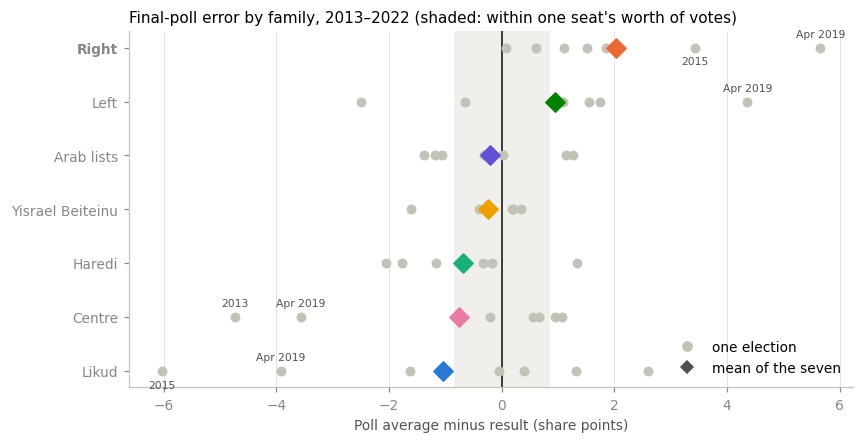

In [23]:

fe = family_error.rename(columns=ELECTIONS["label"])
order_ = summary["mean"].drop(["Likud + Right", "Netanyahu bloc"]).sort_values().index
y = np.arange(len(order_))

fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.axvspan(-SEAT_POINTS, SEAT_POINTS, color="#f0efec", zorder=0)
ax.axvline(0, color="#0b0b0b", linewidth=1)
for i, fam in enumerate(order_):
    ax.scatter(fe.loc[fam], np.full(len(LABELS), i), s=30, color="#c3c2b7", zorder=3)
    ax.scatter(summary.loc[fam, "mean"], i, s=80, marker="D", color=FAMILY_COLORS[fam], zorder=4)
    for k, (label, v) in enumerate(fe.loc[fam].dropna().items()):
        if abs(v) >= 3:
            ax.annotate(label, (v, i), xytext=(0, 7 if k % 2 == 0 else -11), textcoords="offset points", ha="center",
                        fontsize=7, color="#52514e")
ax.set_yticks(y, order_)
for tick, fam in zip(ax.get_yticklabels(), order_):
    if summary.loc[fam, "corrected"]:
        tick.set_fontweight("bold")
ax.grid(axis="y", visible=False)
handles = [plt.Line2D([], [], marker="o", linestyle="", color="#c3c2b7", label="one election"),
           plt.Line2D([], [], marker="D", linestyle="", color="#52514e", label="mean of the seven")]
ax.legend(handles=handles, loc="lower right")
ax.set(xlabel="Poll average minus result (share points)",
       title="Final-poll error by family, 2013–2022 (shaded: within one seat's worth of votes)")
plt.show()

One family is missed in the same direction in all seven elections: **the parties to Likud's right are over-polled**,
by 2.0 points of the vote on average (standard error 0.7), from 0.1 in 2022 to 5.7 in April 2019. Likud is the
mirror image in the big misses: in 2015 and April 2019 the votes the polls gave to Jewish Home, Yachad, New Right
and Zehut went to Likud on election day. Likud and the Right together are over-polled by 1.0 point on average, but
not reliably (standard error 0.9).

The Haredi parties are under-polled in six of the seven elections, by 0.7 points on average (standard error 0.4): a
real lean, but less than a seat's worth, so it stays uncorrected under the rule below. A common explanation is that
Haredi voters are hard to reach by phone and online panels. The other families change sign from election to
election.

The rule for a correction, fixed before looking at 2026: **correct a family only when its mean error over the seven
elections is larger than one seat's worth of the vote (0.83 points) and larger than twice its standard error.**
Only the Right qualifies, by −2.04 points. Because its surplus went to Likud in the big misses, the correction
moves those points to Likud rather than sharing them over every list; 7.5 shows the other choice.

The Netanyahu bloc as a whole is not missed one way. The polls had its vote too low in five of the seven elections
(by 0.7 to 2.2 points) and too high in 2013 and September 2019 (by 3.5 and 2.0): a mean of −0.25 points, well
inside its standard error. In seats as they fell the picture is different, and misleading: 2022 reads as 3.4 seats
too low because Meretz and Balad fell under the threshold, and April 2019 reads as spot on because the bloc's own
New Right and Zehut did.

In [24]:

POLL_CORRECTION = correction_rule(family_error)     # share points added to the poll average, by family
COUNTERPART = {"Right": "Likud"}                    # the Right's surplus goes back to Likud, where it came from
print("Correction (share points):", POLL_CORRECTION)


def shift(values, family, amounts, counterpart=COUNTERPART):
    """Add each family's amount (seats or share points), split over its lists by size. It is taken from the
    counterpart family where there is one, and otherwise balanced over the lists not involved, in proportion to
    their size, so that the total is unchanged."""
    out = values.astype(float).copy()
    moved = pd.Series(0.0, index=values.index)
    fam = family.reindex(values.index)
    for f, amount in amounts.items():
        members = values.index[fam == f]
        moved[members] += amount * values[members] / values[members].sum()
        if f in counterpart:
            partners = values.index[fam == counterpart[f]]
            moved[partners] -= amount * values[partners] / values[partners].sum()
    out += moved
    rest = values.index[moved == 0]
    out[rest] *= (values.sum() - out[moved != 0].sum()) / values[rest].sum()
    return out


rows = {}
for e in PAST:
    d = errors[errors["election"] == e].set_index("list")
    fixed_error = shift(d["poll_share"], d["family"], POLL_CORRECTION) - d["result_share"]
    rows[ELECTIONS.loc[e, "label"]] = {
        "error per list, as published": d["error_points"].abs().mean(),
        "error per list, corrected": fixed_error.abs().mean(),
        "Netanyahu bloc, as published": d["error_points"].reindex(NETANYAHU[e]).sum(),
        "Netanyahu bloc, corrected": fixed_error.reindex(NETANYAHU[e]).sum()}
corrected_scores = pd.DataFrame(rows).T
corrected_scores.loc["mean"] = corrected_scores.mean()
print("Share points:")
corrected_scores.round(2)

Correction (share points): {'Right': -2.04}
Share points:


,"error per list, as published","error per list, corrected","Netanyahu bloc, as published","Netanyahu bloc, corrected"
2013,1.11,1.14,3.47,3.47
2015,1.25,0.89,-1.67,-1.67
Apr 2019,1.75,1.44,-2.19,-2.19
Sep 2019,0.77,0.85,2.02,2.02
2020,0.89,0.72,-0.72,-0.72
2021,1.19,1.29,-1.34,-0.01
2022,0.55,0.91,-1.31,-1.31
mean,1.07,1.03,-0.25,-0.06


The correction cuts the list error in the three elections where the Right's surplus went to Likud (2015, April
2019, 2020) and raises it a little in the other four, where it went elsewhere: 1.07 points per list as published,
1.03 corrected, on average. It changes the bloc error only where a Right-family list sat outside the bloc (Yamina
and New Hope in 2021). It is fitted on these same seven elections, so this is a description; the back-test in
section 7 measures the correction on six elections and applies it to the seventh.

### 5.3 Pollster by pollster

Each pollster's last poll in the final week: the Netanyahu bloc's implied vote share against its result.

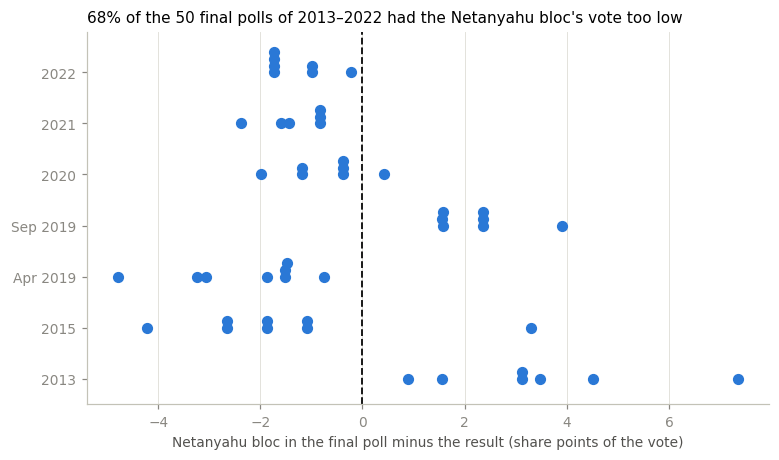

election,2013,2015,Apr 2019,Sep 2019,2020,2021,2022
count,7.0,8.0,8.0,7.0,7.0,6.0,7.0
min,0.9,-4.2,-4.8,1.6,-2.0,-2.4,-1.7
mean,3.4,-1.5,-2.3,2.2,-0.7,-1.3,-1.3
max,7.4,3.3,-0.7,3.9,0.4,-0.8,-0.2


In [25]:

rows = []
for e in PAST:
    d = polls[e]
    result = list_votes[list_votes["election"] == e].set_index("list")
    last = d[d["date"] > d["date"].max() - pd.Timedelta(days=7)].sort_values("date").groupby("pollster").tail(1)
    for _, poll in last.iterrows():
        seats = poll[list(POLL_LISTS[e])].rename(POLL_LISTS[e]).fillna(0).astype(float)
        compared = seats.index[(seats > 0) | (result.loc[seats.index, "seats"] > 0)]
        actual = result.loc[compared, "share_pct"]
        error = seats_to_shares(seats[compared], 100 - actual.sum()).drop("others") - actual
        rows.append({"election": ELECTIONS.loc[e, "label"], "pollster": poll["pollster"], "date": poll["date"].date(),
                     "mean abs. error": error.abs().mean(), "Netanyahu bloc error": error.reindex(NETANYAHU[e]).sum(),
                     "Haredi error": error.reindex(["Shas", "United Torah Judaism"]).sum()})
pollsters = pd.DataFrame(rows)
too_low = (pollsters["Netanyahu bloc error"] < 0).mean()

fig, ax = plt.subplots(figsize=(8, 4.4))
for i, (label, d) in enumerate(pollsters.groupby("election", sort=False)):
    stack = d.groupby(d["Netanyahu bloc error"].round(1)).cumcount()
    ax.scatter(d["Netanyahu bloc error"], i + 0.13 * stack, s=40, color=FAMILY_COLORS["Likud"], zorder=3)
ax.axvline(0, color="#0b0b0b", linewidth=1.2, linestyle="--")
ax.set_yticks(range(len(PAST)), pollsters["election"].unique())
ax.set(xlabel="Netanyahu bloc in the final poll minus the result (share points of the vote)",
       ylim=(-0.5, len(PAST) - 0.2),
       title=f"{too_low:.0%} of the {len(pollsters)} final polls of 2013–2022 had the Netanyahu bloc's vote too low")
ax.grid(axis="y", visible=False)
plt.show()

pollsters.groupby("election", sort=False)["Netanyahu bloc error"].agg(["count", "min", "mean", "max"]).round(1).T

The pollsters of one campaign lean the same way. All seven final polls of 2013 and of September 2019 had the
Netanyahu bloc's vote too high; all of those of April 2019, 2021 and 2022, seven of eight in 2015 and six of seven
in 2020 had it too low: 34 of the 50 in all. The error belongs to the campaign, not to the firm, and no pollster
was consistently better than the others. The firms of 2026 only partly match those of past campaigns, so the model
does not correct pollsters individually.

### 5.4 Which poll average?

Four ways to average the final polls, scored by their mean absolute error per list in share points. Sample sizes
are in the data for 2021 and 2022 only, so the sample-weighted average is scored on those two.

In [26]:

METHODS = {"each pollster's last poll, 7 days": dict(days=7, last_per_pollster=True),
           "all polls, 7 days": dict(days=7, last_per_pollster=False),
           "all polls, 14 days": dict(days=14, last_per_pollster=False),
           "all polls, 7 days, weighted by sample": dict(days=7, last_per_pollster=False, by_sample=True)}
with_samples = [e for e in PAST if polls[e]["respondents"].notna().any()]    # sample sizes: 2021 and 2022 only

scores = pd.DataFrame({name: {ELECTIONS.loc[e, "label"]: poll_errors(e, **m)["error_points"].abs().mean()
                              for e in (with_samples if m.get("by_sample") else PAST)}
                       for name, m in METHODS.items()}).T.reindex(columns=LABELS)
scores["mean 2013–2022"] = scores[LABELS].mean(axis=1).where(scores[LABELS].notna().all(axis=1))
scores["mean 2021–2022"] = scores[["2021", "2022"]].mean(axis=1)
scores.round(2)

,2013,2015,Apr 2019,Sep 2019,2020,2021,2022,mean 2013–2022,mean 2021–2022
"each pollster's last poll, 7 days",1.11,1.25,1.75,0.77,0.89,1.19,0.55,1.07,0.87
"all polls, 7 days",1.12,1.27,1.64,0.78,0.92,1.30,0.56,1.08,0.93
"all polls, 14 days",1.20,1.22,1.56,0.80,1.03,1.49,0.58,1.13,1.03
"all polls, 7 days, weighted by sample",NaN,NaN,NaN,NaN,NaN,1.31,0.57,NaN,0.94


The differences are small: 1.07 to 1.13 points per list over the seven elections. Each pollster's last poll scores
best on average and in five of the seven elections; the 14-day window is worst on average, though best in 2015 and
April 2019. Weighting by sample size, scored on the two elections that have sample sizes, is worse than the simplest
average in both. In 2026 it would give Next Data alone 37% of the weight (several polls of about 2,000 respondents
in the final week), and Next Data has by far the largest Likud. The notebook keeps **each pollster's last poll in
the final week, equal weights**: one vote per pollster, no tuning. Section 7 shows the sample-weighted average as a
sensitivity.

### 5.5 How large an error to simulate

The simulation needs the size of a list's poll error. It is measured on the lists that won seats, in share points
of the vote. A list that fell under the threshold is left out: its miss is a threshold flip, which the simulation
produces by itself.

In [27]:

def list_error(errs):
    """Root-mean-square poll error of the lists that won seats, in seats and in share points."""
    seated = errs[errs["result"] > 0]
    return float(np.sqrt((seated["error"] ** 2).mean())), float(np.sqrt((seated["error_points"] ** 2).mean()))


LIST_ERROR_SEATS, LIST_ERROR_POINTS = list_error(errors)
seated = errors[errors["result"] > 0]
print(f"{len(seated)} lists in seven elections: root-mean-square error {LIST_ERROR_POINTS:.2f} share points "
      f"({LIST_ERROR_SEATS:.2f} seats as they fell)")
pd.DataFrame({"share points": seated.groupby("election")["error_points"].apply(lambda s: np.sqrt((s ** 2).mean())),
              "seats as they fell": seated.groupby("election")["error"].apply(lambda s: np.sqrt((s ** 2).mean()))}
             ).rename(index=ELECTIONS["label"]).round(2).T

73 lists in seven elections: root-mean-square error 1.63 share points (2.23 seats as they fell)


election,2013,2015,Apr 2019,Sep 2019,2020,2021,2022
share points,1.96,2.20,2.11,0.94,1.03,1.50,0.70
seats as they fell,2.62,2.99,3.15,1.23,1.13,1.91,1.06


Should the simulation also draw a shared swing between the blocs, on top of the list errors? Independent list
errors already move the bloc totals, because a bloc is several lists and the shares must add up. A quick
simulation gives the bloc error, in share points, that independent errors of this size produce, to compare with
the bloc errors left in the seven elections after the correction.

In [28]:

rng = np.random.default_rng(6)
rows = {}
for e in PAST:
    d = errors[errors["election"] == e].set_index("list")
    draws = rng.normal(0, LIST_ERROR_POINTS, size=(20_000, len(d)))
    draws -= draws.mean(axis=1, keepdims=True)                          # the shares still add up to the same total
    fixed = shift(d["poll_share"], d["family"], POLL_CORRECTION)
    rows[ELECTIONS.loc[e, "label"]] = {
        "bloc error from independent list errors (one sd)": draws[:, d.index.isin(NETANYAHU[e])].sum(axis=1).std(),
        "bloc error left after the correction": (fixed - d["result_share"]).reindex(NETANYAHU[e]).sum()}
swing_check = pd.DataFrame(rows).T
observed = swing_check["bloc error left after the correction"]
print(f"Bloc error left after the correction: mean {observed.mean():+.1f} share points, "
      f"root-mean-square {np.sqrt((observed ** 2).mean()):.1f}; "
      f"independent list errors alone give {swing_check.iloc[:, 0].mean():.1f}")
swing_check.round(1).T

Bloc error left after the correction: mean -0.1 share points, root-mean-square 1.9; independent list errors alone give 2.7


,2013,2015,Apr 2019,Sep 2019,2020,2021,2022
bloc error from independent list errors (one sd),2.9,2.7,2.8,2.6,2.3,2.7,2.6
bloc error left after the correction,3.5,-1.7,-2.2,2.0,-0.7,-0.0,-1.3


Independent list errors alone give the bloc's vote an error of about ±2.7 points (one standard deviation; 2.3 to
2.9 by election). The bloc errors actually left after the correction are smaller: 1.9 points root-mean-square,
mean −0.1, with 2013 (+3.5) the only one beyond 2.3. There is no shared swing to add. If anything, independent
errors spread the bloc a little wider than the past warrants, which fits the back-test's 95% intervals catching
98% of the results (7.2). The model draws independent list errors only; section 7 adds a bloc swing as a
sensitivity test.

### 5.6 The 2026 campaign

Every national poll of the 2026 campaign, one panel per list. The line is a centred average of the nine nearest
polls.

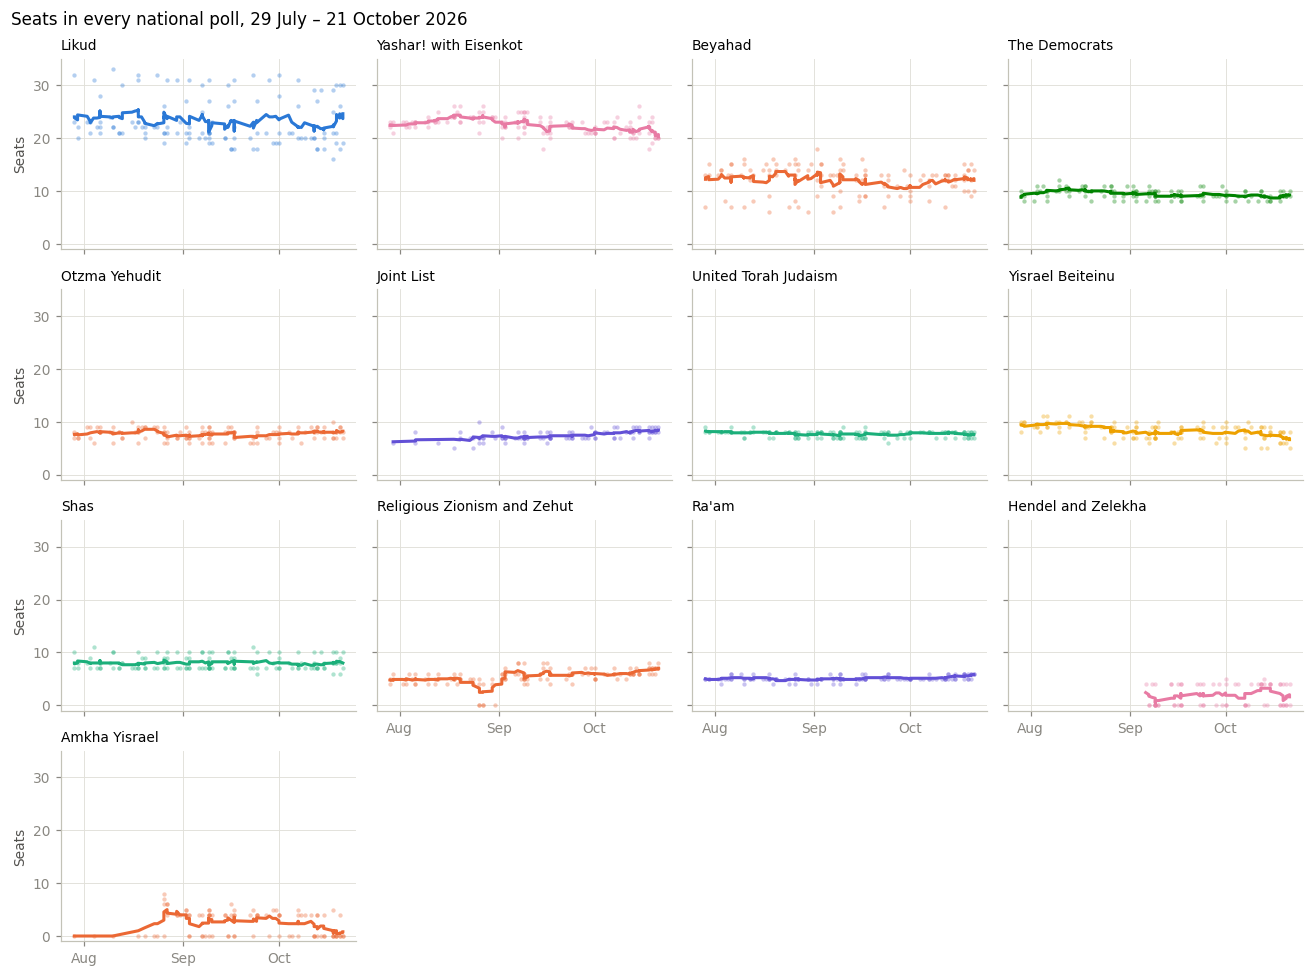

In [29]:
import matplotlib.dates as mdates

k26 = polls["K26"]
on_ballot = LISTS_2026.index[LISTS_2026["on_ballot"] == "yes"]

fig, axes = plt.subplots(4, 4, figsize=(12, 9), sharex=True, sharey=True)
for ax, key in zip(axes.flat, on_ballot):
    d = k26[["date", key]].dropna().sort_values("date")
    colour = FAMILY_COLORS[LISTS_2026.loc[key, "family"]]
    ax.scatter(d["date"], d[key], s=8, alpha=0.35, color=colour, linewidth=0)
    ax.plot(d["date"], d[key].rolling(9, center=True, min_periods=5).mean(), color=colour)
    ax.set_title(LISTS_2026.loc[key, "list"], fontsize=9)
    ax.set_ylim(-1, 35)
for ax in axes.flat[len(on_ballot):]:
    ax.axis("off")
for ax in axes.flat:
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
for ax in axes[-2, 1:]:
    ax.tick_params(labelbottom=True)                                 # the panels below them are empty
for ax in axes[:, 0]:
    ax.set_ylabel("Seats")
fig.suptitle("Seats in every national poll, 29 July – 21 October 2026", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
plt.show()

#### The 2026 poll average

The same average as for the past campaigns: each pollster's last poll in the week up to the newest poll (15–21 October).
Blue and White withdrew on 19 October; it had no seats in these polls.

In [30]:
window = k26[k26["date"] > k26["date"].max() - pd.Timedelta(days=7)].sort_values("date").groupby("pollster").tail(1)
assert window["blue_white"].fillna(0).eq(0).all()

final_2026 = window.set_index("pollster")[list(on_ballot)].rename(columns=LISTS_2026["list"])
final_2026.insert(0, "date", window.set_index("pollster")["date"].dt.strftime("%d %b"))
netanyahu_2026 = LISTS_2026.loc[on_ballot].query("bloc == 'Netanyahu'")["list"]
final_2026["Netanyahu bloc"] = final_2026[netanyahu_2026].sum(axis=1)
final_2026.loc["average"] = final_2026.drop(columns="date").mean()
final_2026.T.style.format(precision=1, na_rep="")

pollster,Tatika,Kantar Israel,Midgam (Mano Geva),Menachem Lazar,Maagar Mochot,Direct Polls,Next Data,Shmuel Rosner,average
date,15 Oct,18 Oct,19 Oct,19 Oct,20 Oct,20 Oct,21 Oct,21 Oct,
Likud,20.0,21.0,21.0,19.0,18.0,26.0,30.0,19.0,21.8
Yashar! with Eisenkot,26.0,23.0,24.0,23.0,21.0,20.0,20.0,20.0,22.1
Beyahad,11.0,12.0,14.0,14.0,15.0,12.0,10.0,14.0,12.8
The Democrats,8.0,9.0,9.0,9.0,9.0,9.0,9.0,10.0,9.0
Otzma Yehudit,7.0,8.0,8.0,8.0,9.0,9.0,8.0,7.0,8.0
Joint List,8.0,8.0,9.0,8.0,9.0,8.0,8.0,9.0,8.4
United Torah Judaism,8.0,7.0,7.0,7.0,7.0,8.0,7.0,8.0,7.4
Yisrael Beiteinu,9.0,8.0,8.0,8.0,7.0,7.0,5.0,8.0,7.5
Shas,8.0,8.0,8.0,8.0,6.0,8.0,10.0,7.0,7.9


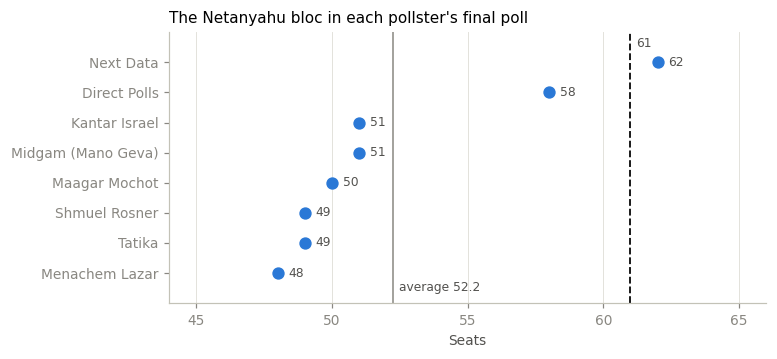

In [31]:
bloc_by_pollster = final_2026["Netanyahu bloc"].drop("average").astype(float).sort_values()
average_bloc = final_2026.loc["average", "Netanyahu bloc"]
y = np.arange(len(bloc_by_pollster))

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.axvline(61, color="#0b0b0b", linewidth=1.2, linestyle="--")
ax.axvline(average_bloc, color="#898781", linewidth=1)
ax.scatter(bloc_by_pollster, y, s=50, color=FAMILY_COLORS["Likud"], zorder=3)
for yy, value in zip(y, bloc_by_pollster):
    ax.annotate(f"{value:.0f}", (value, yy), xytext=(7, 0), textcoords="offset points", va="center", fontsize=8,
                color="#52514e")
ax.annotate("61", (61, len(y) - 0.5), xytext=(4, 0), textcoords="offset points", fontsize=8, color="#52514e")
ax.annotate(f"average {average_bloc:.1f}", (average_bloc, -0.6), xytext=(4, 0), textcoords="offset points",
            fontsize=8, color="#52514e")
ax.set_yticks(y, bloc_by_pollster.index)
ax.set(xlim=(44, 66), ylim=(-1, len(y)), xlabel="Seats", title="The Netanyahu bloc in each pollster's final poll")
ax.set_xticks(range(45, 66, 5))
ax.grid(axis="y", visible=False)
plt.show()

The pollsters disagree most about Likud (18 to 30 seats) and so about the bloc: Next Data, the pollster with the
largest Likud, is the only one to give the Netanyahu bloc 61 or more.

The model works in vote shares, not seats: a list just under the threshold polls at 0 seats but may be at 3.1%, and
that difference matters. Most pollsters print each list's share beside its seats. Each poll's shares are divided by
the sum of all the list shares it prints (the undecided left out), so that they add up to 100 with the small lists
outside the table as "others". Rosner prints seats only and is left out of the share average. Blue and White's share,
where printed, goes to the other opposition lists of that poll in proportion.

In [32]:
share_columns = [c for c in k26.columns if c.endswith("_pct") and c not in ("undecided_pct", "not_voting_pct", "moe_pct")]
with_shares = window[window[share_columns].notna().any(axis=1)].set_index("pollster")
raw = with_shares[share_columns].fillna(0)
raw.columns = [c.removesuffix("_pct") for c in raw.columns]
shares_2026 = raw.div(raw.sum(axis=1), axis=0) * 100

opposition = LISTS_2026.index[(LISTS_2026["bloc"] == "Opposition") & (LISTS_2026["on_ballot"] == "yes")]
withdrawn = shares_2026.pop("blue_white")
shares_2026[opposition] += shares_2026[opposition].mul(withdrawn / shares_2026[opposition].sum(axis=1), axis=0)
shares_2026["others"] = shares_2026.drop(columns=on_ballot).sum(axis=1)
shares_2026 = shares_2026[list(on_ballot) + ["others"]]
assert np.allclose(shares_2026.sum(axis=1), 100)

baseline_2026 = LISTS_2026.loc[on_ballot, ["list", "family", "bloc", "pair"]].copy()
baseline_2026["seats (8 pollsters)"] = final_2026.loc["average", baseline_2026["list"]].to_numpy()
baseline_2026["seats, lowest–highest"] = [f"{final_2026[n].iloc[:-1].min():.0f}–{final_2026[n].iloc[:-1].max():.0f}"
                                           for n in baseline_2026["list"]]
baseline_2026["share % (7 pollsters)"] = shares_2026[on_ballot].mean()
baseline_2026["share %, lowest–highest"] = [f"{shares_2026[k].min():.1f}–{shares_2026[k].max():.1f}" for k in on_ballot]
OTHERS_2026 = shares_2026["others"].mean()
print(f"Others (lists outside the table): {OTHERS_2026:.2f}% on average")
baseline_2026.drop(columns="pair").round(2)

Others (lists outside the table): 0.87% on average


,list,family,bloc,seats (8 pollsters),"seats, lowest–highest",share % (7 pollsters),"share %, lowest–highest"
key,,,,,,,
likud,Likud,Likud,Netanyahu,21.75,18–30,17.31,14.3–23.8
yashar,Yashar! with Eisenkot,Centre,Opposition,22.12,20–26,17.24,15.0–19.9
beyahad,Beyahad,Right,Opposition,12.75,10–15,10.05,7.9–12.1
democrats,The Democrats,Left,Opposition,9.00,8–10,7.30,6.6–7.9
otzma_yehudit,Otzma Yehudit,Right,Netanyahu,8.00,7–9,6.47,5.6–7.7
joint_list,Joint List,Arab lists,Arab lists,8.38,8–9,6.61,6.1–7.7
utj,United Torah Judaism,Haredi,Netanyahu,7.38,7–8,5.71,5.4–6.2
yisrael_beiteinu,Yisrael Beiteinu,Yisrael Beiteinu,Opposition,7.50,5–9,6.11,4.0–7.6
shas,Shas,Haredi,Netanyahu,7.88,6–10,6.32,4.4–7.9


Three lists sit close to the threshold. Hendel and Zelekha average 3.1% (2.2–4.1% across pollsters) and Amkha
Yisrael 2.8% (1.7–3.3%), both under 3.25% on average; Ra'am averages 4.6%, and its lowest poll is 4.0%. Whether
these lists pass is one of the largest uncertainties of the election.

Next: turnout, and what it means for the Arab lists.

## 6. Population, turnout and the flow model

The polls measure opinion today. This section builds what the past elections and population growth say on their own:

- **the 2026 electorate**, locality by locality and sector by sector, forecast from 2013–2022 (6.1, 6.2);
- **turnout by sector**, and a model linking Arab turnout to the Arab lists' share (6.3–6.5);
- **a flow model**: every polling place votes as it has in its recent elections, with its 2026 population (6.6).
  Section 7 combines it with the polls.

Everything is fitted on 2013–2022; the 2026 roll the CEC published is only a check.

### 6.1 Forecasting the 2026 roll

Each locality's roll is projected forward at an annual growth rate. Three candidates:

- **group rate**: every locality grows at the rate of its group (Jewish, Haredi, Arab, Druze and others, mixed);
- **own trend**: every locality grows at its own log-linear trend over the elections it was present in all of;
- **half and half**: the average of the two rates.

A locality without a full history takes its group's rate. The candidates are scored before 2026 is looked at, on
every rolling fold the data allow: fit on the elections up to one date, forecast each later election, and measure
the weighted absolute percentage error over localities (WAPE).

In [33]:
REG = towns.pivot_table(index="locality_code", columns="election", values="registered", aggfunc="sum")
YEARS = (ELECTIONS["date"] - ELECTIONS["date"].iloc[0]).dt.days / 365.25
ELECTION_DAY_2026 = pd.Timestamp("2026-10-27")
GROWTH_MODELS = {"group rate": 0.0, "half and half": 0.5, "own trend": 1.0}   # weight on the locality's own trend


def growth_rates(train):
    """Annual log growth per locality: its own trend (if present in every training election) and its group's."""
    t = YEARS[train].to_numpy() - YEARS[train].mean()
    complete = REG[train].gt(0).all(axis=1)
    logs = np.log(REG.loc[complete, train])
    own = logs.sub(logs.mean(axis=1), axis=0).mul(t).sum(axis=1) / (t ** 2).sum()
    group_logs = np.log(REG.loc[complete, train].groupby(localities["group"]).sum())
    group_rate = group_logs.sub(group_logs.mean(axis=1), axis=0).mul(t).sum(axis=1) / (t ** 2).sum()
    return own.reindex(REG.index), localities["group"].reindex(REG.index).map(group_rate)


def roll_forecast(train, target_date, weight):
    own, group = growth_rates(train)
    rate = (weight * own + (1 - weight) * group).fillna(group)
    horizon = (target_date - ELECTIONS.loc[train[-1], "date"]).days / 365.25
    return REG[train[-1]] * np.exp(rate * horizon)


def wape(forecast, actual):
    both = forecast.dropna().index.intersection(actual.dropna().index)
    return 100 * (forecast[both] - actual[both]).abs().sum() / actual[both].sum()


order = list(ELECTIONS.index)
folds = [(end, test) for end in order[2:-1] for test in order[order.index(end) + 1:]]   # at least 3 elections to fit
fold_scores = pd.DataFrame(
    {name: [wape(roll_forecast(order[:order.index(end) + 1], ELECTIONS.loc[test, "date"], w), REG[test]) for end, test in folds]
     for name, w in GROWTH_MODELS.items()},
    index=pd.MultiIndex.from_tuples(
        [(ELECTIONS.loc[end, "label"], ELECTIONS.loc[test, "label"],
          round((ELECTIONS.loc[test, "date"] - ELECTIONS.loc[end, "date"]).days / 365.25, 1)) for end, test in folds],
        names=["fitted up to", "forecast", "years ahead"]))
fold_scores.loc[("mean", "", "")] = fold_scores.mean()
CHOSEN_GROWTH = fold_scores.loc[("mean", "", "")].idxmin()
print("Chosen:", CHOSEN_GROWTH)
fold_scores.round(2)

Chosen: own trend


group rate  half and half  own trend
fitted up to forecast years ahead                                      
Apr 2019     Sep 2019 0.4                0.52           0.41       0.39
             2020     0.9                0.94           0.73       0.69
             2021     2.0                1.99           1.51       1.29
             2022     3.6                3.53           2.69       2.41
Sep 2019     2020     0.5                0.57           0.47       0.44
             2021     1.5                1.65           1.26       1.07
             2022     3.1                3.16           2.42       2.19
2020         2021     1.1                1.18           0.91       0.76
             2022     2.7                2.69           2.07       1.91
2021         2022     1.6                1.69           1.32       1.37
mean                                     1.79           1.38       1.25

The locality's own trend scores best on average and in nine of the ten folds, so it is the model. Now the 2026 check:
fitted on all seven elections, forecast for 27 October 2026, compared with the roll the CEC published.

The sector totals need one more step. A locality's voters are split between the sectors by its 2022 ballot boxes
(section 2), so a mixed city counts in both. A locality with no boxes in 2022 is all in the sector of its CBS group.

In [34]:
roll_2026_published = (pd.read_csv(DATA / "cec_2026" / "registered_voters_2026_by_locality.csv", encoding="utf-8-sig")
                         .set_index("locality_code")["registered_voters"])

k25_boxes = boxes[boxes["election"] == "K25"]
arab_part = (k25_boxes["registered"].where(k25_boxes["sector"] == "Arab", 0).groupby(k25_boxes["locality_code"]).sum()
             / k25_boxes.groupby("locality_code")["registered"].sum())


def by_sector(roll):
    share = arab_part.reindex(roll.index)
    share = share.fillna(localities["cbs_group"].reindex(roll.index).isin(["Arab", "Bedouin tribe"]).astype(float))
    return pd.Series({"Arab": (roll * share).sum(), "Jewish": (roll * (1 - share)).sum()})


forecasts_2026 = {name: roll_forecast(order, ELECTION_DAY_2026, w) for name, w in GROWTH_MODELS.items()}
roll_2026 = forecasts_2026[CHOSEN_GROWTH]
new_localities = roll_2026_published.drop(REG.index, errors="ignore")

check = pd.DataFrame({name: {"town WAPE (%)": wape(f, roll_2026_published),
                             **{f"{s} sector": v for s, v in by_sector(f.dropna()).items()},
                             "national": f.sum()}
                      for name, f in forecasts_2026.items()})
check["published roll"] = {"town WAPE (%)": np.nan, **{f"{s} sector": v for s, v in by_sector(roll_2026_published).items()},
                           "national": roll_2026_published.sum()}
print(f"{len(new_localities)} new localities in 2026 ({new_localities.sum():,} voters) cannot be forecast and are left out")
check.style.format("{:,.0f}", na_rep="").format("{:.2f}", subset=pd.IndexSlice["town WAPE (%)", :], na_rep="")

9 new localities in 2026 (4,829 voters) cannot be forecast and are left out


,group rate,half and half,own trend,published roll
town WAPE (%),3.63,3.06,3.87,
Arab sector,"1,151,134","1,153,517","1,157,329","1,126,536"
Jewish sector,"6,161,128","6,190,301","6,246,030","6,205,445"
national,"7,312,262","7,343,818","7,403,358","7,331,981"


The chosen model is off by 3.9% per locality in 2026, worse than the 2.4% it scored at a similar horizon before.
The roll grew more slowly than its 2013–2022 trend: the forecast is 1% too high nationally and 2.7% too high in the
Arab sector. The half-and-half model would have done better here, which is a reminder that a choice made on folds
that share one target year (2022) is fragile. The choice stands: changing it after seeing 2026 would turn the
check into fitting.

The forecast below is the electorate the model uses.

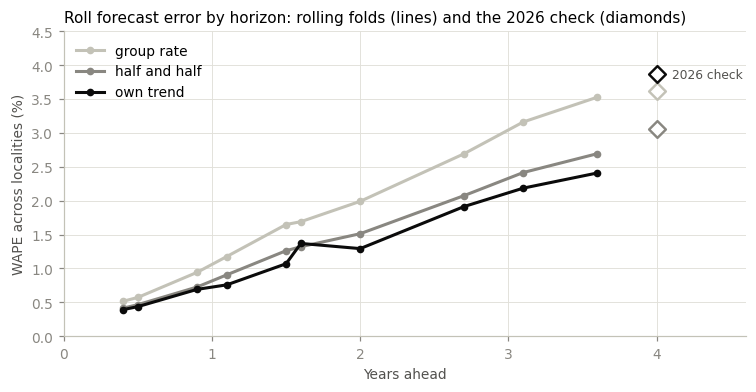

Arab      1157329.0
Jewish    6246030.0
dtype: float64

In [35]:
fig, ax = plt.subplots(figsize=(8, 3.6))
for (name, w), colour in zip(GROWTH_MODELS.items(), ["#c3c2b7", "#898781", "#0b0b0b"]):          # the chosen model darkest
    s = fold_scores.drop(("mean", "", ""))[name].reset_index()
    by_horizon = s.groupby("years ahead")[name].mean()
    ax.plot(by_horizon.index, by_horizon, color=colour, marker="o", markersize=4, label=name)
    ax.scatter([4.0], [check.loc["town WAPE (%)", name]], s=60, marker="D", facecolor="white", edgecolor=colour,
               linewidth=1.6, zorder=3)
ax.annotate("2026 check", (4.0, check.loc["town WAPE (%)", "own trend"]), xytext=(10, 0), textcoords="offset points",
            va="center", color="#52514e", fontsize=8)
ax.set(xlabel="Years ahead", ylabel="WAPE across localities (%)", xlim=(0, 4.6), ylim=(0, 4.5),
       title="Roll forecast error by horizon: rolling folds (lines) and the 2026 check (diamonds)")
ax.legend(loc="upper left")
plt.show()

ELECTORATE_2026 = by_sector(roll_2026.dropna())
ELECTORATE_2026.round(0)

### 6.2 Growth by sector

How fast is each part of the electorate growing? The ballot boxes of every election are grouped by how they voted:

- **Arab sector**: the sector rule of section 2;
- **Haredi**: Jewish-sector boxes where the Haredi lists won 60% or more of the valid votes, wherever they are. Unlike
  the locality groups of section 2, this counts the Haredi neighbourhoods of Jerusalem, Beit Shemesh or Ashdod;
- **other Jewish**: the rest.

A box changes group only if its vote changes, and these groups vote very stably (section 3.4).

In [36]:
haredi_vote_share = boxes["Haredi"] / boxes["valid"].where(boxes["valid"] > 0)
boxes["growth_group"] = np.select([boxes["sector"].eq("Arab"), haredi_vote_share >= HAREDI_MIN],
                                  ["Arab sector", "Haredi"], default="Other Jewish")
GROWTH_GROUPS = ["Haredi", "Arab sector", "Other Jewish"]
group_roll = boxes.pivot_table(index="election", columns="growth_group", values="registered", aggfunc="sum")[GROWTH_GROUPS]

tc = YEARS.to_numpy() - YEARS.mean()
log_roll = np.log(group_roll)
annual_growth = np.exp(log_roll.sub(log_roll.mean()).mul(tc, axis=0).sum() / (tc ** 2).sum()) - 1
group_roll.set_index(ELECTIONS["label"]).style.format("{:,}")

growth_group,Haredi,Arab sector,Other Jewish
label,,,
2013,"326,974","755,315","4,574,416"
2015,"328,375","819,173","4,734,148"
Apr 2019,"409,346","903,164","5,027,219"
Sep 2019,"421,597","937,276","5,032,345"
2020,"440,792","957,785","5,054,678"
2021,"448,448","970,005","5,159,631"
2022,"486,548","1,025,978","5,276,278"


For a 2026 forecast of each group, the roll is forecast for every polling place (the CEC's place code is stable from
September 2019). Each place grows at its own 2019–2022 trend, capped at −10% and +15% a year, and the places of a
locality are scaled to add up to the locality forecast of 6.1. A place's voters are then split between the groups as
its 2022 boxes were.

In [37]:
PLACE_ELECTIONS = ["K22", "K23", "K24", "K25"]
PLACE_KEYS = ["locality_code", "place"]
place_boxes = boxes[boxes["place"].notna()]
place_roll = place_boxes.pivot_table(index=PLACE_KEYS, columns="election", values="registered",
                                     aggfunc="sum")[PLACE_ELECTIONS]

tc = YEARS[PLACE_ELECTIONS].to_numpy() - YEARS[PLACE_ELECTIONS].mean()
complete = place_roll.gt(0).all(axis=1)
log_place = np.log(place_roll[complete])
place_rate = log_place.sub(log_place.mean(axis=1), axis=0).mul(tc).sum(axis=1) / (tc ** 2).sum()
own_rate, group_rate = growth_rates(order)
locality_rate = own_rate.fillna(group_rate)
fallback = pd.Series(locality_rate.reindex(place_roll.index.get_level_values("locality_code")).to_numpy(),
                     index=place_roll.index)
place_rate = place_rate.reindex(place_roll.index).fillna(fallback).clip(-0.10, 0.15)

horizon = (ELECTION_DAY_2026 - ELECTIONS.loc["K25", "date"]).days / 365.25
raw = place_roll["K25"].dropna() * np.exp(place_rate.reindex(place_roll["K25"].dropna().index) * horizon)
locality = raw.index.get_level_values("locality_code")
scale = roll_2026.reindex(locality).to_numpy() / raw.groupby(locality).transform("sum").to_numpy()
place_2026 = raw * np.where(np.isfinite(scale), scale, 1)

composition = (boxes[boxes["election"] == "K25"]
               .pivot_table(index=PLACE_KEYS, columns="growth_group", values="registered", aggfunc="sum").fillna(0))
composition = composition.div(composition.sum(axis=1), axis=0)
group_2026 = composition.reindex(place_2026.index).mul(place_2026, axis=0).sum()[GROWTH_GROUPS]

growth_table = pd.DataFrame({
    "roll 2013": group_roll.loc["K19"], "roll 2022": group_roll.loc["K25"], "forecast 2026": group_2026,
    "growth per year 2013–2022 %": 100 * annual_growth,
    "growth 2022–2026 %": 100 * (group_2026 / group_roll.loc["K25"] - 1),
    "share 2013 %": 100 * group_roll.loc["K19"] / group_roll.loc["K19"].sum(),
    "share 2022 %": 100 * group_roll.loc["K25"] / group_roll.loc["K25"].sum(),
    "share 2026 %": 100 * group_2026 / group_2026.sum(),
})
print(f"{len(place_2026):,} polling places")
growth_table.style.format("{:,.0f}", subset=["roll 2013", "roll 2022", "forecast 2026"]).format(
    "{:.1f}", subset=[c for c in growth_table.columns if c.endswith("%")])

4,206 polling places


,roll 2013,roll 2022,forecast 2026,growth per year 2013–2022 %,growth 2022–2026 %,share 2013 %,share 2022 %,share 2026 %
growth_group,,,,,,,,
Haredi,"326,974","486,548","553,260",4.5,13.7,5.8,7.2,7.5
Arab sector,"755,315","1,025,978","1,159,033",3.1,13.0,13.4,15.1,15.7
Other Jewish,"4,574,416","5,276,278","5,691,065",1.5,7.9,80.9,77.7,76.9


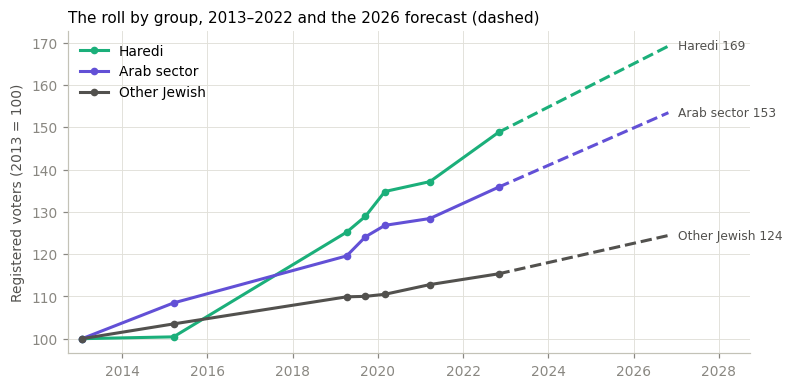

In [38]:
GROWTH_COLORS = {"Haredi": GROUP_COLORS["Haredi"], "Arab sector": GROUP_COLORS["Arab"], "Other Jewish": "#52514e"}

fig, ax = plt.subplots(figsize=(8, 3.8))
for g in GROWTH_GROUPS:
    index = 100 * group_roll[g] / group_roll.loc["K19", g]
    end = 100 * group_2026[g] / group_roll.loc["K19", g]
    ax.plot(ELECTIONS["date"], index, color=GROWTH_COLORS[g], marker="o", markersize=4, label=g)
    ax.plot([ELECTIONS.loc["K25", "date"], ELECTION_DAY_2026], [index.iloc[-1], end], color=GROWTH_COLORS[g],
            linestyle="--")
    ax.annotate(f"{g} {end:.0f}", (ELECTION_DAY_2026, end), xytext=(6, 0), textcoords="offset points", va="center",
                fontsize=8, color="#52514e")
ax.set_xlim(ELECTIONS.loc["K19", "date"] - pd.Timedelta(days=120), ELECTION_DAY_2026 + pd.Timedelta(days=700))
ax.set(ylabel="Registered voters (2013 = 100)", title="The roll by group, 2013–2022 and the 2026 forecast (dashed)")
ax.legend(loc="upper left")
plt.show()

- **The Haredi electorate grows fastest**: 4.5% a year, three times the rest of the Jewish sector (1.5%). Counting
  only the Haredi towns, as in section 2, would miss more than half of these voters: the Haredi boxes held 486,548
  voters in 2022, the Haredi towns 217,901.
- **The Arab sector grows 3.1% a year.** Its share of the roll rises from 13.4% in 2013 to 15.1% in 2022, and to
  15.7% in the 2026 forecast.
- **By 2026 the Haredi boxes hold 7.5% of the roll** (5.8% in 2013) and the other Jewish boxes 76.9% (80.9%).

So even if every place voted exactly as before, the national result would move toward the Haredi parties and the
Arab lists. The flow model (6.6) carries that through to the seats.

### 6.3 Turnout by sector, with the double envelopes

Section 3 measured turnout at the ballot boxes. The double envelopes (soldiers, diplomats, hospital patients and
others voting away from home) are counted nationally, so they have to be split between the sectors by how they
voted. With *a* the Arab lists' share of the valid vote in each place:

$$\text{Arab share of the envelopes} = \frac{a_\text{envelopes} - a_\text{Jewish boxes}}{a_\text{Arab boxes} - a_\text{Jewish boxes}}$$

This assumes each sector's envelope voters vote like the voters in its boxes. The other quantities the model needs:

- **loyalty**: the Arab lists' share of the Arab sector's valid votes;
- **the Arab lists' share of the Jewish sector**: their few votes among Jewish voters;
- **invalid rates** per sector, and the **envelope factor**: Arab ballots including envelopes ÷ Arab ballots at the
  boxes.

In [39]:
def sector_history(e):
    b = boxes[boxes["election"] == e]
    g = b.groupby("sector")[["registered", "voted", "invalid", "valid", "Arab lists"]].sum()
    envelopes = town[e][town[e]["external"]]
    env_ballots, env_valid = envelopes["voted"].sum(), envelopes["valid"].sum()
    a_env = family_votes(envelopes, e)["Arab lists"].sum() / env_valid
    loyalty = g.loc["Arab", "Arab lists"] / g.loc["Arab", "valid"]
    a_jewish = g.loc["Jewish", "Arab lists"] / g.loc["Jewish", "valid"]
    arab_envelopes = (a_env - a_jewish) / (loyalty - a_jewish) * env_ballots

    total = national.loc[e]
    ballots_arab = g.loc["Arab", "voted"] + arab_envelopes
    invalid_arab = g.loc["Arab", "invalid"] / g.loc["Arab", "voted"]
    valid_arab = ballots_arab * (1 - invalid_arab)
    ballots_jewish = total["voted"] - ballots_arab
    valid_jewish = total["valid"] - valid_arab
    arab_lists = list_votes[(list_votes["election"] == e) & (list_votes["family"] == "Arab lists")]["votes"].sum()
    return {
        "roll_arab": g.loc["Arab", "registered"], "roll_jewish": g.loc["Jewish", "registered"],
        "turnout_arab": g.loc["Arab", "voted"] / g.loc["Arab", "registered"],        # at the boxes
        "turnout_jewish": ballots_jewish / g.loc["Jewish", "registered"],              # with its envelopes
        "envelope_factor": ballots_arab / g.loc["Arab", "voted"],
        "invalid_arab": invalid_arab, "invalid_jewish": 1 - valid_jewish / ballots_jewish,
        "loyalty": loyalty, "arab_lists_jewish": (arab_lists - valid_arab * loyalty) / valid_jewish,
    }


history = pd.DataFrame([sector_history(e) for e in ELECTIONS.index], index=ELECTIONS.index)
shown = history.copy()
for c in ["turnout_arab", "turnout_jewish", "invalid_arab", "invalid_jewish", "loyalty", "arab_lists_jewish"]:
    shown[c] *= 100
shown.set_index(ELECTIONS["label"]).style.format(
    {"roll_arab": "{:,.0f}", "roll_jewish": "{:,.0f}", "envelope_factor": "{:.4f}", "arab_lists_jewish": "{:.2f}"}
    | {c: "{:.1f}" for c in ["turnout_arab", "turnout_jewish", "invalid_arab", "invalid_jewish", "loyalty"]})

,roll_arab,roll_jewish,turnout_arab,turnout_jewish,envelope_factor,invalid_arab,invalid_jewish,loyalty,arab_lists_jewish
label,,,,,,,,,
2013,"755,315","4,901,390",55.9,69.5,1.0129,1.5,1.0,76.9,0.74
2015,"819,173","5,062,523",62.8,73.7,1.0140,0.9,1.0,81.8,0.65
Apr 2019,"903,164","5,436,565",48.9,71.6,1.0181,1.1,0.7,70.6,0.61
Sep 2019,"937,276","5,453,942",58.3,71.6,1.0232,1.1,0.6,79.9,0.72
2020,"957,785","5,495,470",63.7,72.6,1.0286,0.6,0.5,87.0,0.98
2021,"970,005","5,608,079",44.1,71.1,1.0445,1.1,0.5,79.7,0.69
2022,"1,025,978","5,762,826",52.6,73.4,1.0423,1.0,0.6,85.1,0.90


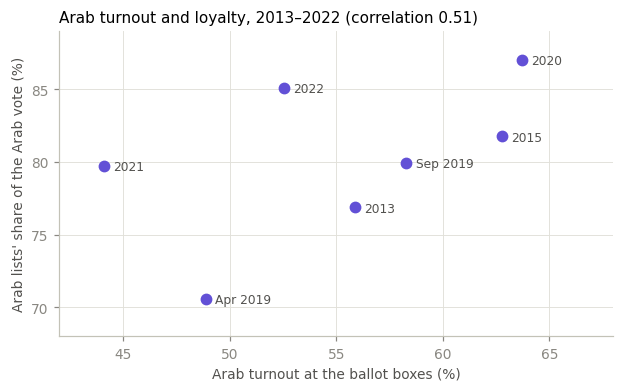

In [40]:
r = np.corrcoef(history["turnout_arab"], history["loyalty"])[0, 1]
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.scatter(100 * history["turnout_arab"], 100 * history["loyalty"], s=45, color=FAMILY_COLORS["Arab lists"], zorder=3)
for e in ELECTIONS.index:
    ax.annotate(ELECTIONS.loc[e, "label"], (100 * history.loc[e, "turnout_arab"], 100 * history.loc[e, "loyalty"]),
                xytext=(6, -3), textcoords="offset points", fontsize=8, color="#52514e")
ax.set(xlim=(42, 68), ylim=(68, 89), xlabel="Arab turnout at the ballot boxes (%)",
       ylabel="Arab lists' share of the Arab vote (%)", title=f"Arab turnout and loyalty, 2013–2022 (correlation {r:.2f})")
ax.set_yticks(range(70, 90, 5))
plt.show()

Percentages except the rolls and the envelope factor. Jewish turnout including the envelopes is 69.5–73.7%, Arab
turnout at the boxes 44.1–63.7%. Loyalty moves with Arab turnout: it was highest (87%) when Arab turnout was highest
(2020). The envelopes now add over 4% to the Arab sector's ballots, up from about 1% in 2013.

### 6.4 The two-sector model

Given each sector's roll and turnout, the model gives the valid votes and the Arab lists' votes:

- Arab sector valid votes: $V_A = R_A \cdot t_A \cdot f_\text{env} \cdot (1 - i_A)$
- Jewish sector valid votes: $V_J = R_J \cdot t_J \cdot (1 - i_J)$
- Arab lists' votes: $V_A \cdot \text{loyalty} + V_J \cdot a_J$, and their share is that divided by $V_A + V_J$.

With each election's own parameters it must give back that election's ballots, valid votes and Arab-list votes.

In [41]:
def sector_model(p):
    """Two-sector turnout model. p: a mapping with the keys of `history`."""
    ballots_arab = p["roll_arab"] * p["turnout_arab"] * p["envelope_factor"]
    ballots_jewish = p["roll_jewish"] * p["turnout_jewish"]
    valid_arab = ballots_arab * (1 - p["invalid_arab"])
    valid_jewish = ballots_jewish * (1 - p["invalid_jewish"])
    arab_lists = valid_arab * p["loyalty"] + valid_jewish * p["arab_lists_jewish"]
    valid = valid_arab + valid_jewish
    return {"ballots": ballots_arab + ballots_jewish, "valid": valid, "arab_lists": arab_lists,
            "arab_lists_share": 100 * arab_lists / valid}


replay = pd.DataFrame([sector_model(history.loc[e]) for e in ELECTIONS.index], index=ELECTIONS.index)
actual_arab_lists = list_votes[list_votes["family"] == "Arab lists"].groupby("election")["votes"].sum()
assert np.allclose(replay["ballots"], national["voted"]) and np.allclose(replay["valid"], national["valid"])
assert np.allclose(replay["arab_lists"], actual_arab_lists)
print("The model gives back every election's ballots, valid votes and Arab-list votes.")

The model gives back every election's ballots, valid votes and Arab-list votes.


### 6.5 What the 2026 polls imply about Arab turnout

For 2026 every parameter takes its 2022 value, except the electorate (6.1) and Arab turnout, which is unknown. The
polls put the Joint List and Ra'am together at 11.2% of the vote. Solving the model for the Arab turnout that gives
that share shows what the polls assume.

Polls: Arab lists 11.21% of the vote -> Arab turnout 53.3% at the boxes, at 2022's loyalty (85.1%) and Jewish turnout (73.4%)


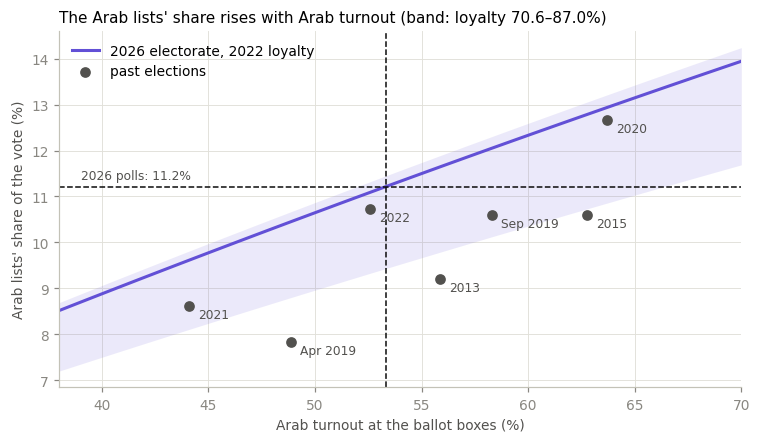

In [42]:
PARAMS_2026 = history.loc["K25"].copy()
PARAMS_2026["roll_arab"], PARAMS_2026["roll_jewish"] = ELECTORATE_2026["Arab"], ELECTORATE_2026["Jewish"]
ARAB_POLL_SHARE = baseline_2026.loc[["joint_list", "raam"], "share % (7 pollsters)"].sum()


def implied_arab_turnout(share_pct, p):
    """The Arab turnout (at the boxes) at which the model gives the Arab lists share_pct of the vote."""
    s = share_pct / 100
    valid_jewish = p["roll_jewish"] * p["turnout_jewish"] * (1 - p["invalid_jewish"])
    valid_arab = valid_jewish * (s - p["arab_lists_jewish"]) / (p["loyalty"] - s)
    return valid_arab / (p["roll_arab"] * p["envelope_factor"] * (1 - p["invalid_arab"]))


PARAMS_2026["turnout_arab"] = implied_arab_turnout(ARAB_POLL_SHARE, PARAMS_2026)
print(f"Polls: Arab lists {ARAB_POLL_SHARE:.2f}% of the vote -> Arab turnout {100 * PARAMS_2026['turnout_arab']:.1f}% "
      f"at the boxes, at 2022's loyalty ({100 * PARAMS_2026['loyalty']:.1f}%) and Jewish turnout ({100 * PARAMS_2026['turnout_jewish']:.1f}%)")

turnouts = np.linspace(0.38, 0.70, 65)
curve = [sector_model({**PARAMS_2026, "turnout_arab": t})["arab_lists_share"] for t in turnouts]
low = [sector_model({**PARAMS_2026, "turnout_arab": t, "loyalty": history["loyalty"].min()})["arab_lists_share"] for t in turnouts]
high = [sector_model({**PARAMS_2026, "turnout_arab": t, "loyalty": history["loyalty"].max()})["arab_lists_share"] for t in turnouts]

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.fill_between(100 * turnouts, low, high, color=FAMILY_COLORS["Arab lists"], alpha=0.12, linewidth=0)
ax.plot(100 * turnouts, curve, color=FAMILY_COLORS["Arab lists"], label="2026 electorate, 2022 loyalty")
ax.scatter(100 * history["turnout_arab"], replay["arab_lists_share"], s=36, color="#52514e", zorder=3, label="past elections")
for e in ELECTIONS.index:
    ax.annotate(ELECTIONS.loc[e, "label"], (100 * history.loc[e, "turnout_arab"], replay.loc[e, "arab_lists_share"]),
                xytext=(6, -8), textcoords="offset points", fontsize=8, color="#52514e")
ax.axhline(ARAB_POLL_SHARE, color="#0b0b0b", linewidth=1, linestyle="--")
ax.axvline(100 * PARAMS_2026["turnout_arab"], color="#0b0b0b", linewidth=1, linestyle="--")
ax.annotate(f"2026 polls: {ARAB_POLL_SHARE:.1f}%", (39, ARAB_POLL_SHARE), xytext=(0, 5), textcoords="offset points",
            fontsize=8, color="#52514e")
ax.set(xlabel="Arab turnout at the ballot boxes (%)", ylabel="Arab lists' share of the vote (%)", xlim=(38, 70),
       title="The Arab lists' share rises with Arab turnout (band: loyalty 70.6–87.0%)")
ax.legend(loc="upper left")
plt.show()

The polls imply an Arab turnout of 53%, close to 2022's and below the elections when the Arab parties ran as one
list (58–64%). Each point of Arab turnout is worth about 0.17 points of the Arab lists' share, so the range of the past
(44–64%) spans about 3.4 points of vote share, or four seats. Past elections sit below the 2026 line because the
Arab sector was a smaller part of the electorate then, and loyalty was often lower.

The polls model therefore takes the Arab lists' share from the polls, like every other list's; the flow model (6.6)
gets its own from each polling place's recent turnout; and section 7 uses this curve for scenarios: what the seats look like if Arab turnout is like 2021, or like 2020.

#### The 2026 parameters

In [43]:
SOURCES = {"roll_arab": "forecast, 6.1", "roll_jewish": "forecast, 6.1", "turnout_arab": "implied by the polls, 6.5",
           "turnout_jewish": "2022", "envelope_factor": "2022", "invalid_arab": "2022", "invalid_jewish": "2022",
           "loyalty": "2022", "arab_lists_jewish": "2022"}
def show_parameter(name, value):
    if name.startswith("roll"):
        return f"{value:,.0f}"
    return f"{value:.4f}" if name == "envelope_factor" else f"{100 * value:.2f}%"


params_table = pd.DataFrame({column: [show_parameter(k, v) for k, v in values.items()]
                             for column, values in {"2026 value": PARAMS_2026, "lowest 2013–2022": history.min(),
                                                    "highest 2013–2022": history.max()}.items()}, index=PARAMS_2026.index)
params_table["source"] = pd.Series(SOURCES)
params_table

,2026 value,lowest 2013–2022,highest 2013–2022,source
roll_arab,"1,157,329","755,315","1,025,978","forecast, 6.1"
roll_jewish,"6,246,030","4,901,390","5,762,826","forecast, 6.1"
turnout_arab,53.31%,44.08%,63.71%,"implied by the polls, 6.5"
turnout_jewish,73.45%,69.49%,73.75%,2022
envelope_factor,1.0423,1.0129,1.0445,2022
invalid_arab,1.00%,0.62%,1.45%,2022
invalid_jewish,0.57%,0.53%,1.05%,2022
loyalty,85.11%,70.56%,87.03%,2022
arab_lists_jewish,0.90%,0.61%,0.98%,2022


### 6.6 The flow model

A second forecast that does not take its levels from the polls: every polling place votes as it has been voting,
with its 2026 population. For each polling place of 2022:

1. **Electorate**: its 2026 forecast (6.2).
2. **Turnout and valid-vote rate**: its own average over its recent elections.
3. **Vote.** Where a party family has kept its shape, the place's share is averaged over its recent elections: the
   Haredi parties, the Arab lists, Labor and Meretz (The Democrats in 2026) and Yisrael Beiteinu. Where the parties
   realigned, only 2022 maps onto today's camps: Likud, Religious Zionism (which ran with Otzma Yehudit), Jewish Home
   and the centre (Yesh Atid and National Unity). Earlier lists straddle today's camps: Yamina in 2019–2021 held both
   Smotrich's voters, now in the Netanyahu bloc, and Bennett's, now in the opposition.
4. **Add up** the places, and correct for the double envelopes, which vote a little differently from the boxes
   (each party's 2022 ratio of national share to ballot-box share).

How many recent elections to average is chosen by back-test: predict 2021 and 2022 from each place's earlier
elections, with its actual roll (the roll forecast was scored in 6.1), and compare turnout and the stable families'
shares. Errors are in percentage points.

In [44]:
place_stats = place_boxes.groupby(["election"] + PLACE_KEYS)[["registered", "voted", "valid"] + FAMILIES].sum()
STABLE = ["Haredi", "Arab lists", "Left", "Yisrael Beiteinu"]


def window_stats(elections):
    """Turnout, valid-vote rate and the stable families' shares per place, pooled over the given elections."""
    s = place_stats[place_stats.index.get_level_values("election").isin(elections)].groupby(level=PLACE_KEYS).sum()
    return s["voted"] / s["registered"], s["valid"] / s["voted"], s[STABLE].div(s["valid"], axis=0)


def window_error(target, window):
    turnout, valid_rate, stable = window_stats(window)
    actual = place_stats.loc[target]
    places = actual.index.intersection(turnout.index)
    roll = actual.loc[places, "registered"]
    valid = roll * turnout[places] * valid_rate[places]
    errors = 100 * (stable.loc[places].mul(valid, axis=0).sum() / valid.sum()
                    - actual.loc[places, STABLE].sum() / actual.loc[places, "valid"].sum())
    errors["turnout"] = 100 * ((roll * turnout[places]).sum() - actual.loc[places, "voted"].sum()) / roll.sum()
    return errors


rows = {}
for target, earlier in [("K24", ["K22", "K23"]), ("K25", ["K22", "K23", "K24"])]:
    for w in range(1, len(earlier) + 1):
        e = window_error(target, earlier[-w:])
        rows[(ELECTIONS.loc[target, "label"], f"last {w}")] = {**e.to_dict(), "RMS": float(np.sqrt((e ** 2).mean()))}
window_scores = pd.DataFrame(rows).T
FLOW_WINDOW = int(window_scores.loc["2022", "RMS"].idxmin().split()[-1])     # 2022: every window can be scored
print(f"Average over each place's last {FLOW_WINDOW} elections")
window_scores.round(2)

Average over each place's last 2 elections


Haredi  Arab lists  Left  Yisrael Beiteinu  turnout   RMS
2021 last 1    0.77        4.35 -4.65              0.25     5.59  3.81
     last 2    0.71        3.27 -3.02              0.85     5.13  3.08
2022 last 1   -1.21       -2.19  3.69              1.12    -2.70  2.39
     last 2   -0.83       -0.03  1.34              1.26    -0.07  0.90
     last 3   -0.74       -0.09  1.72              1.69     0.48  1.15

Averaging each place's last two elections beats the last election alone in both years, and beats the last three in
2022 (error 0.90 points, against 2.39 and 1.15). A single election carries its one-off swings, of which the
collapse of Arab turnout in 2021 is the clearest. Turnout itself was hard to predict for 2021: it fell by five
points that year, which no average of the past could see.

In [45]:
FLOW_ELECTIONS = PLACE_ELECTIONS[-FLOW_WINDOW:]
LETTERS_2022 = LISTS[LISTS["election"] == "K25"].set_index("list")["letters"]
REALIGNED = {"Likud": ["Likud"], "Religious Zionism": ["Religious Zionism"], "Jewish Home": ["Jewish Home"],
             "Centre": ["Yesh Atid", "National Unity"]}
FLOW_GROUP_OF = {**{m: g for g, members in REALIGNED.items() for m in members},
                 "Shas": "Haredi", "United Torah Judaism": "Haredi", "Ra'am": "Arab lists", "Hadash-Ta'al": "Arab lists",
                 "Balad": "Arab lists", "Labor": "Left", "Meretz": "Left", "Yisrael Beiteinu": "Yisrael Beiteinu"}

# 2022 votes per place for the realigned lists; the rest of the realigned share is "Other"
b22 = box["K25"][~box["K25"]["external"]]
place_2022 = b22.groupby(PLACE_KEYS)[["valid"] + list(LETTERS_2022)].sum()
realigned = pd.DataFrame({g: place_2022[LETTERS_2022[m]].sum(axis=1) for g, m in REALIGNED.items()})
realigned["Other"] = place_2022["valid"] - realigned.sum(axis=1) - place_stats.loc["K25", STABLE].sum(axis=1)

turnout, valid_rate, stable = window_stats(FLOW_ELECTIONS)
places = place_2026.index
stable = stable.reindex(places).fillna(0)
realigned_split = realigned.div(realigned.sum(axis=1), axis=0).reindex(places).fillna(0)
place_shares = pd.concat([stable, realigned_split.mul(1 - stable.sum(axis=1), axis=0)], axis=1)
valid_2026 = place_2026 * turnout.reindex(places) * valid_rate.reindex(places)
box_votes = place_shares.mul(valid_2026, axis=0).sum()

lv_2022 = list_votes[list_votes["election"] == "K25"].set_index("list")["votes"]
national_2022 = lv_2022.groupby(lambda name: FLOW_GROUP_OF.get(name, "Other")).sum()
boxes_2022 = pd.concat([place_stats.loc["K25", STABLE].sum(), realigned.sum()])
envelope_ratio = (national_2022 / national_2022.sum()) / (boxes_2022 / boxes_2022.sum())
flow_groups = box_votes / box_votes.sum() * envelope_ratio[box_votes.index]
flow_groups = 100 * flow_groups / flow_groups.sum()
print(f"Valid votes, flow model: {valid_2026.sum():,.0f} at the ballot boxes")
flow_groups.round(2)

Valid votes, flow model: 4,622,617 at the ballot boxes

Haredi               13.88
Arab lists           10.09
Left                  8.40
Yisrael Beiteinu      4.86
Likud                22.89
Religious Zionism    11.02
Jewish Home           1.21
Centre               26.16
Other                 1.49
dtype: float64

The flow model's groups become 2026 lists. A group that is one list today stays one list. The Haredi vote splits
between Shas and United Torah Judaism, and the Arab vote between the Joint List and Ra'am, as in 2022. Where one 2022
group has several heirs in 2026, the split comes from the polls: Likud into Likud and Amkha Yisrael, Religious
Zionism into Religious Zionism and Otzma Yehudit, the centre into Yashar!, Beyahad and Hendel and Zelekha. Jewish
Home's voters, whose list does not run, go to "others".

In [46]:
poll_split = baseline_2026["share % (7 pollsters)"]
AGREEMENTS_2026 = [tuple(g.index) for _, g in LISTS_2026[LISTS_2026["pair"] != ""].groupby("pair")]


def split(total, keys, weights):
    return total * weights[keys] / weights[keys].sum()


shas_part = lv_2022["Shas"] / lv_2022[["Shas", "United Torah Judaism"]].sum()
joint_part = lv_2022[["Hadash-Ta'al", "Balad"]].sum() / lv_2022[["Ra'am", "Hadash-Ta'al", "Balad"]].sum()
flow_2026 = pd.concat([
    split(flow_groups["Likud"], ["likud", "amkha_yisrael"], poll_split),
    split(flow_groups["Religious Zionism"], ["religious_zionism", "otzma_yehudit"], poll_split),
    split(flow_groups["Centre"], ["yashar", "beyahad", "hendel_zelekha"], poll_split),
    pd.Series({"shas": flow_groups["Haredi"] * shas_part, "utj": flow_groups["Haredi"] * (1 - shas_part),
               "joint_list": flow_groups["Arab lists"] * joint_part, "raam": flow_groups["Arab lists"] * (1 - joint_part),
               "democrats": flow_groups["Left"], "yisrael_beiteinu": flow_groups["Yisrael Beiteinu"],
               "others": flow_groups["Jewish Home"] + flow_groups["Other"]}),
]).reindex(list(on_ballot) + ["others"])
assert np.isclose(flow_2026.sum(), 100)

polls_with_others = pd.concat([poll_split, pd.Series({"others": OTHERS_2026})])
flow_table = pd.DataFrame({"list": LISTS_2026["list"], "bloc": LISTS_2026["bloc"],
                           "flow share %": flow_2026, "poll share %": polls_with_others,
                           "flow seats": bader_ofer(flow_2026, AGREEMENTS_2026),
                           "poll seats": bader_ofer(polls_with_others, AGREEMENTS_2026)}, index=flow_2026.index)
flow_table.loc["others", ["list", "bloc"]] = ["others", ""]
display(flow_table.round(2))
flow_table.drop(index="others").groupby("bloc")[["flow share %", "poll share %", "flow seats", "poll seats"]].sum().round(1)

,list,bloc,flow share %,poll share %,flow seats,poll seats
likud,Likud,Netanyahu,19.67,17.31,27,23
yashar,Yashar! with Eisenkot,Opposition,14.82,17.24,20,23
beyahad,Beyahad,Opposition,8.64,10.05,12,13
democrats,The Democrats,Opposition,8.40,7.30,11,9
otzma_yehudit,Otzma Yehudit,Netanyahu,5.98,6.47,7,8
joint_list,Joint List,Arab lists,6.26,6.61,8,8
utj,United Torah Judaism,Netanyahu,5.78,5.71,7,7
yisrael_beiteinu,Yisrael Beiteinu,Opposition,4.86,6.11,6,8
shas,Shas,Netanyahu,8.10,6.32,11,8
religious_zionism,Religious Zionism and Zehut,Netanyahu,5.04,5.45,6,7


,flow share %,poll share %,flow seats,poll seats
bloc,,,,
Arab lists,10.1,11.2,13,14
Netanyahu,47.8,44.1,58,53
Opposition,39.4,43.8,49,53


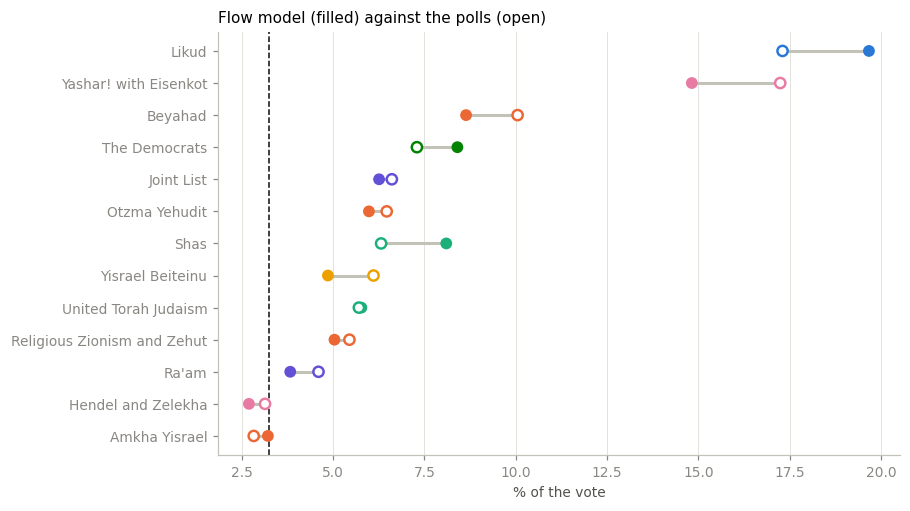

In [47]:
shown = flow_table.drop(index="others").sort_values("poll share %")
y = np.arange(len(shown))
colours = [FAMILY_COLORS[LISTS_2026.loc[k, "family"]] for k in shown.index]
fig, ax = plt.subplots(figsize=(8, 5))
ax.hlines(y, shown["poll share %"], shown["flow share %"], color="#c3c2b7", linewidth=2)
ax.scatter(shown["flow share %"], y, s=45, color=colours, zorder=3)
ax.scatter(shown["poll share %"], y, s=45, facecolor="white", edgecolor=colours, linewidth=1.6, zorder=3)
ax.axvline(3.25, color="#0b0b0b", linewidth=1, linestyle="--")
ax.set_yticks(y, shown["list"])
ax.grid(axis="y", visible=False)
ax.set(xlabel="% of the vote", title="Flow model (filled) against the polls (open)")
plt.show()

- **The flow model gives the Netanyahu bloc 58 seats** (47.8% of the vote) and the opposition 49, against 53 and 53
  in the polls as published; the Arab lists 13 against 14.
- **The gaps show where opinion has moved since 2022**, as far as the polls can tell: the flow model has more for
  Likud (19.7% against 17.3%), Shas (8.1% against 6.3%) and The Democrats, and less for Yashar!, Beyahad and Yisrael
  Beiteinu.
- Part of the Haredi gap is demography (their boxes grow 4.5% a year) and part is the polls' known miss (5.2).

The flow model is what the polls would show if nobody had changed their vote since their last elections.

Next: the polls model, its back-test, and its combination with the flow model.

## 7. The model, the back-test and the forecast

### 7.1 The polls model

The pieces of sections 4–6 put together:

1. **Start from the poll average** in vote shares (section 5), with the lists outside the table as "others".
2. **Correct the parties to Likud's right** by the 2.0 points the polls gave them too many on average in 2013–2022
   (section 5.2): taken from the Right-family lists in proportion to their size and given to Likud.
3. **Draw the poll error.** Each list gets an independent normal error with the size measured in section 5.5
   (1.6 share points); shares below zero are set to zero and every draw is rescaled to 100%. An optional swing between
   the Netanyahu bloc and the opposition is off by default (section 5.5) and used in 7.5 as a sensitivity.
4. **Count the seats** of every draw with the fast Bader-Ofer function (section 4), threshold 3.25% and the surplus
   agreements of 2026.

A list near the threshold passes in some draws and fails in others, so its seats, and every other list's, come out
as a distribution. The model is built and tested here and back-tested on the seven elections of 2013–2022 (7.2);
7.3 combines it with the flow model, and 7.4 runs the combination on 2026.

In [48]:

def seat_price(shares, threshold=3.25):
    """Share points per seat: the share above the threshold divided by 120."""
    lists = shares.drop("others", errors="ignore")
    return lists[lists >= threshold].sum() / 120


def apply_correction(shares, family, correction_points, counterpart=COUNTERPART):
    """The poll correction of section 5.2 applied to vote shares: shift() with the counterpart rule."""
    return shift(shares, family, correction_points, counterpart)


def simulate(shares, agreements, n=20_000, list_error=None, bloc_swing=0.0, bloc=None, seed=2026, threshold=3.25):
    """Simulated elections. shares: vote share (%) per list plus "others". Returns (shares, seats) per draw."""
    list_error = LIST_ERROR_POINTS if list_error is None else list_error
    rng = np.random.default_rng(seed)
    base = shares.to_numpy(float)
    is_list = (shares.index != "others").astype(float)
    drawn = base + rng.normal(0, 1, size=(n, len(base))) * list_error * is_list    # "others" carries no error
    swing = rng.normal(0, 1, size=(n, 1)) * bloc_swing                              # drawn always: same draws either way
    if bloc_swing:
        side = bloc.reindex(shares.index)
        netanyahu, opposition = (side == "Netanyahu").to_numpy(), (side == "Opposition").to_numpy()
        drawn += swing * (netanyahu * base / base[netanyahu].sum() - opposition * base / base[opposition].sum())
    drawn = np.clip(drawn, 0, None)
    drawn = 100 * drawn / drawn.sum(axis=1, keepdims=True)
    seats = bader_ofer_fast(drawn, agreement_units(shares.index, agreements), threshold)
    return pd.DataFrame(drawn, columns=shares.index), pd.DataFrame(seats, columns=shares.index)


INTERVAL = 95                                                     # the interval reported everywhere, in %
LOW, HIGH = (100 - INTERVAL) / 200, 1 - (100 - INTERVAL) / 200   # its quantiles


def summarize(seats, bloc):
    """Per list: median seats, the interval, P(pass). Per bloc: median, the interval, P(61+)."""
    lists = seats.drop(columns="others", errors="ignore")
    per_list = pd.DataFrame({"median": lists.median(), "low": lists.quantile(LOW), "high": lists.quantile(HIGH),
                             "mean": lists.mean(), "P(pass)": (lists > 0).mean()})
    totals = lists.T.groupby(bloc.reindex(lists.columns)).sum().T
    per_bloc = pd.DataFrame({"median": totals.median(), "low": totals.quantile(LOW),
                             "high": totals.quantile(HIGH), "P(61+)": (totals >= 61).mean()})
    return per_list, per_bloc, totals

#### The 2026 inputs

The poll average of section 5 (vote shares, seven pollsters), the blocs as the pollsters count them, and the five
surplus agreements of 2026 (from the Hebrew Wikipedia page of the election): Likud with Religious Zionism, Yashar! with
The Democrats, Beyahad with Yisrael Beiteinu, Shas with United Torah Judaism, and the Joint List with Ra'am. They are
defined in `data/lists_2026.csv` and read in 6.6.

In [49]:

average_2026 = pd.concat([baseline_2026["share % (7 pollsters)"], pd.Series({"others": OTHERS_2026})])
average_2026 = 100 * average_2026 / average_2026.sum()
FAMILY_2026 = LISTS_2026["family"]
BLOC_2026 = LISTS_2026["bloc"]
corrected_2026 = apply_correction(average_2026, FAMILY_2026, POLL_CORRECTION)
print("Agreements:", AGREEMENTS_2026)
print(f"Seat price at the poll average: {seat_price(average_2026):.3f} share points per seat")
moved = (corrected_2026 - average_2026).drop("others")
involved = FAMILY_2026.index[FAMILY_2026.isin(list(POLL_CORRECTION) + list(COUNTERPART.values()))]
print("The correction moves, in share points:",
      ", ".join(f"{LISTS_2026.loc[k, 'list']} {moved[k]:+.2f}" for k in moved[involved].sort_values().index),
      f"; the other lists share {moved.drop(involved).sum():+.2f} in proportion to their size")

Agreements: [('likud', 'religious_zionism'), ('yashar', 'democrats'), ('utj', 'shas'), ('beyahad', 'yisrael_beiteinu'), ('joint_list', 'raam')]
Seat price at the poll average: 0.776 share points per seat
The correction moves, in share points: Beyahad -0.83, Otzma Yehudit -0.53, Religious Zionism and Zehut -0.45, Amkha Yisrael -0.23, Likud +2.04 ; the other lists share -0.00 in proportion to their size


#### Tests of the model

1. With no error, every draw must give exactly the reference seat count of `bader_ofer` for the input shares.
2. The same seed must give the same draws.
3. Every draw must share out exactly 120 seats.
4. The drawn errors must have the intended size.

In [50]:
_, exact = simulate(corrected_2026, AGREEMENTS_2026, n=50, list_error=0)
reference = bader_ofer(corrected_2026, AGREEMENTS_2026)
assert (exact == reference).all().all()

drawn_a, seats_a = simulate(corrected_2026, AGREEMENTS_2026, n=5_000)
drawn_b, seats_b = simulate(corrected_2026, AGREEMENTS_2026, n=5_000)
assert drawn_a.equals(drawn_b) and seats_a.equals(seats_b)
assert (seats_a.sum(axis=1) == 120).all()

spread = (drawn_a - corrected_2026).drop(columns="others").std()
print(f"Drawn error, standard deviation by list: {spread.min():.2f}–{spread.max():.2f} share points "
      f"(intended {LIST_ERROR_POINTS:.2f}; rescaling to 100% shrinks it a little)")

Drawn error, standard deviation by list: 1.49–1.72 share points (intended 1.63; rescaling to 100% shrinks it a little)


#### The central scenario: no error

Before any uncertainty, the poll average itself through the seat rule, with and without the correction of 5.2.

In [51]:
central = pd.DataFrame({
    "list": LISTS_2026["list"],
    "bloc": BLOC_2026,
    "poll share %": average_2026,
    "corrected share %": corrected_2026,
    "seats, polls as published": bader_ofer(average_2026, AGREEMENTS_2026),
    "seats, corrected": bader_ofer(corrected_2026, AGREEMENTS_2026),
}, index=average_2026.index.drop("others"))
blocs = central.groupby("bloc")[["seats, polls as published", "seats, corrected"]].sum()
display(central.round(2))
blocs

,list,bloc,poll share %,corrected share %,"seats, polls as published","seats, corrected"
likud,Likud,Netanyahu,17.31,19.35,23,26
yashar,Yashar! with Eisenkot,Opposition,17.24,17.24,23,23
beyahad,Beyahad,Opposition,10.05,9.23,13,12
democrats,The Democrats,Opposition,7.30,7.30,9,9
otzma_yehudit,Otzma Yehudit,Netanyahu,6.47,5.94,8,7
joint_list,Joint List,Arab lists,6.61,6.61,8,8
utj,United Torah Judaism,Netanyahu,5.71,5.71,7,7
yisrael_beiteinu,Yisrael Beiteinu,Opposition,6.11,6.11,8,8
shas,Shas,Netanyahu,6.32,6.32,8,8
religious_zionism,Religious Zionism and Zehut,Netanyahu,5.45,5.00,7,6


,"seats, polls as published","seats, corrected"
bloc,,
Arab lists,14,14
Netanyahu,53,54
Opposition,53,52


Hendel and Zelekha (3.1%) and Amkha Yisrael (2.8%) are under the threshold in the poll average, so they win nothing
here and their votes are lost. As published, the polls give the Netanyahu bloc 53 seats, the opposition 53 and the
Arab lists 14. The correction moves 2.0 points of the vote from the four Right-family lists to Likud: Likud rises
from 23 seats to 26, Beyahad, Otzma Yehudit and Religious Zionism lose one each, and the bloc goes to 54, since
Beyahad sits in the opposition. But a list 0.1 points under the threshold is close to a coin flip, which this
central run cannot show. The simulation can.

#### How a list near the threshold is simulated

The drawn shares of the two lists closest to the threshold, over 5,000 simulated elections. Each draw where a list
lands to the right of the line, it passes and wins at least four seats.

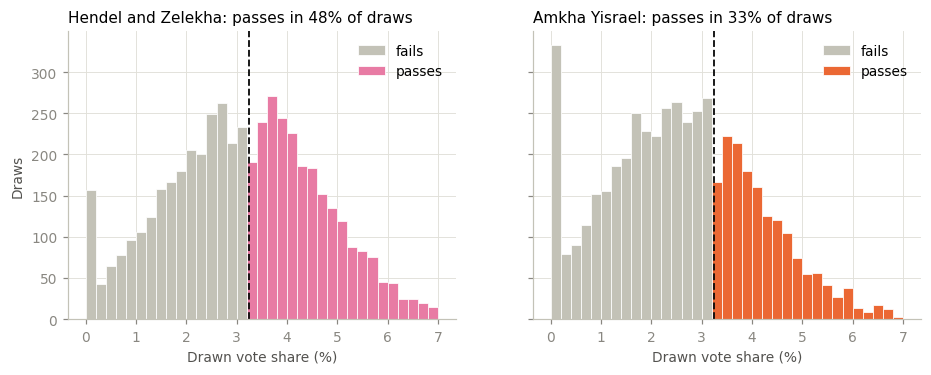

In [52]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
bins = np.arange(0, 7.01, 0.2)
for ax, key in zip(axes, ["hendel_zelekha", "amkha_yisrael"]):
    values = drawn_a[key]
    colour = FAMILY_COLORS[FAMILY_2026[key]]
    ax.hist(values[values < 3.25], bins=bins, color="#c3c2b7", edgecolor="white", linewidth=0.5, label="fails")
    ax.hist(values[values >= 3.25], bins=bins, color=colour, edgecolor="white", linewidth=0.5, label="passes")
    ax.axvline(3.25, color="#0b0b0b", linewidth=1.2, linestyle="--")
    ax.set(xlabel="Drawn vote share (%)",
           title=f"{LISTS_2026.loc[key, 'list']}: passes in {(values >= 3.25).mean():.0%} of draws")
    ax.legend(loc="upper right")
axes[0].set_ylabel("Draws")
plt.show()

The errors are drawn with the size measured in 2013–2022 (1.6 points), so a list polling at 3.1% passes in close
to half the draws, and one at 2.8% in about a third. Whether these lists pass moves seats between every other list,
which is why the forecast is a distribution and not a single number.

### 7.2 Back-test on the seven elections of 2013–2022

The model, run as it would have been run in the final week of each campaign from 2013 to 2022, and compared with
what happened. For each election the correction rule and the error size are measured on the other six elections
only, so the test never sees the election it scores. Three things are scored:

- **seats per list**: whether the result fell inside the 95% interval (if the intervals are honest, about 19 lists
  in 20 should);
- **the threshold**: a Brier score for each list's chance of passing (0 is perfect, 0.25 is a coin flip);
- **the blocs**: whether the Netanyahu bloc's result fell inside its interval, and the chance of 61 seats the model
  gave it.

Each election is run with its own threshold (2% in 2013, 3.25% since 2015) and its own surplus agreements. Two
caveats. The past polls give seats only, so their vote shares have to be rebuilt from the seats (below); the 2026
run uses the printed shares. And the seven elections together chose the form of the rule (families, a one-seat
bar), even though each fold measures it afresh; 2026 itself is the test on unseen data (section 8).

#### Vote shares from seats

D'Hondt hands out seats like rounding down at a common divisor, so a list with *s* seats has on average *s* + ½
divisors' worth of votes. Each list's share is therefore (seats + ½) times a divisor chosen so that the lists add up
to 100 minus the share left outside the table. In the back-test that outside share is what was known at the time:
the previous election's share lost below the threshold (for 2013, the mean of the later elections). Section 5
scales the compared lists to their actual total instead, the right normalisation for measuring errors but not one
a forecaster had.

The half seat matters. Without it, a list the polls give 4 seats lands right at 3.25%, fails in half the draws and
hands its votes to the large lists, which then come out 2–3 seats above the polls.

In [53]:

def backtest(e, correction):
    """The polls model as it could have been run in the final week of election e. The correction and the error
    size are measured on the other six elections, so each back-test is out of sample."""
    others = errors[errors["election"] != e]
    rule = correction_rule(family_errors(others)) if correction else {}
    _, error_points = list_error(others)
    threshold = ELECTIONS.loc[e, "threshold_pct"]
    poll = final_week(e)
    shares = seats_to_shares(poll, outside_share(e))
    family = list_votes[list_votes["election"] == e].set_index("list")["family"]
    if correction:
        shares = apply_correction(shares, family, rule)
    result = list_votes[list_votes["election"] == e].set_index("list")["seats"].reindex(poll.index)
    scored = poll.index[(poll > 0) | (result > 0)]          # a list polled at 0 that won 0 is not scored
    bloc = pd.Series({name: "Netanyahu" if name in NETANYAHU[e] else "Arab lists" if family[name] == "Arab lists" else "Other"
                      for name in scored})
    _, seats = simulate(shares, AGREEMENTS[e], list_error=error_points, threshold=threshold)
    central = bader_ofer(shares, AGREEMENTS[e], threshold)
    return {"poll": poll[scored], "shares": shares, "seats": seats[scored], "central": central[scored],
            "bloc": bloc, "result": result[scored], "correction": rule, "error_points": error_points}


backtests = {(e, correction): backtest(e, correction) for e in PAST for correction in (False, True)}
pd.DataFrame({ELECTIONS.loc[e, "label"]: {"correction from the other six (share points)": backtests[(e, True)]["correction"],
                                          "list error from the other six (share points)": round(backtests[(e, True)]["error_points"], 2)}
              for e in PAST}).T

,correction from the other six (share points),list error from the other six (share points)
2013,{'Right': -2.12},1.56
2015,"{'Right': -1.8, 'Haredi': 1.02}",1.52
Apr 2019,{'Right': -1.43},1.53
Sep 2019,{'Right': -2.06},1.71
2020,{'Right': -2.19},1.69
2021,"{'Right': -2.27, 'Left': -1.52}",1.66
2022,{'Right': -2.36},1.73


#### Scores

In [54]:

def score(run):
    seats, result = run["seats"], run["result"]
    low, high, passes = seats.quantile(LOW), seats.quantile(HIGH), (seats > 0).mean()
    totals = seats.T.groupby(run["bloc"]).sum().T
    bloc_actual = result.groupby(run["bloc"]).sum()
    return {
        f"lists inside the {INTERVAL}% interval": f"{((result >= low) & (result <= high)).sum()} of {len(result)}",
        "Brier score, pass or fail": ((passes - (result > 0)) ** 2).mean(),
        "Netanyahu bloc: result": bloc_actual["Netanyahu"],
        "Netanyahu bloc: median": totals["Netanyahu"].median(),
        f"Netanyahu bloc: {INTERVAL}% interval": f"{totals['Netanyahu'].quantile(LOW):.0f}–{totals['Netanyahu'].quantile(HIGH):.0f}",
        "P(Netanyahu bloc 61+)": (totals["Netanyahu"] >= 61).mean(),
    }


def coverage(correction):
    """Lists inside their intervals over the seven back-tests, and the mean Brier score."""
    inside = total = 0
    brier = []
    for e in PAST:
        run = backtests[(e, correction)]
        seats, result = run["seats"], run["result"]
        inside += int(((result >= seats.quantile(LOW)) & (result <= seats.quantile(HIGH))).sum())
        total += len(result)
        brier.append(score(run)["Brier score, pass or fail"])
    return inside, total, float(np.mean(brier))


for c in (False, True):
    inside, total, brier = coverage(c)
    print(f"{'With' if c else 'Without'} the correction: {inside} of {total} lists inside their {INTERVAL}% intervals, "
          f"mean Brier score {brier:.3f}")

scores_table = pd.DataFrame({(ELECTIONS.loc[e, "label"], "with" if c else "without"): score(run)
                             for (e, c), run in backtests.items()}).T
scores_table.index.names = ["election", "correction"]
scores_table.style.format({"Brier score, pass or fail": "{:.3f}", "Netanyahu bloc: median": "{:.0f}", "P(Netanyahu bloc 61+)": "{:.1%}"})

Without the correction: 76 of 80 lists inside their 95% intervals, mean Brier score 0.066
With the correction: 78 of 80 lists inside their 95% intervals, mean Brier score 0.067


- **The intervals hold, and are a little wide.** 78 of the 80 lists fell inside their 95% intervals, against the
  76 that honest intervals would catch (give or take 2): the list error of 5.5 is slightly generous.
- **The threshold calls are good in six elections**, Brier scores of 0.01–0.09, and poor in April 2019 (0.19): New
  Right and Zehut, polled at five or six seats each, were given better-than-even chances of passing and both failed.
- **The Netanyahu bloc's result fell inside its interval in all seven elections.** The chance given to 61 or more
  was 77% in 2013 (it won 61), 54% in April 2019 (65) and 66% in 2022 (64), and 4–18% in the four elections it fell
  short.
- **The correction changes little in the back-test**: 78 lists inside with it, 76 without, Brier 0.067 against
  0.066. Moving the Right's surplus to Likud brings two more lists inside in April 2019 and improves the threshold
  calls in 2015, and worsens them in 2021, where the surplus went to the centre instead. The 2015 fold also corrects the Haredi parties and the 2021 fold the
  Left: the rule's choice of families is not stable from fold to fold, which is why the seven-election rule keeps
  only the Right.

The point accuracy is the polls' own (section 5): the simulation does not make the centre better, it puts honest
error bars around it. A median is also a poor point estimate for a list near the threshold, which either wins
nothing or wins four seats: Ra'am 2021 passed in fewer than half the draws, so its median was 0.

The chart shows every list with the correction.

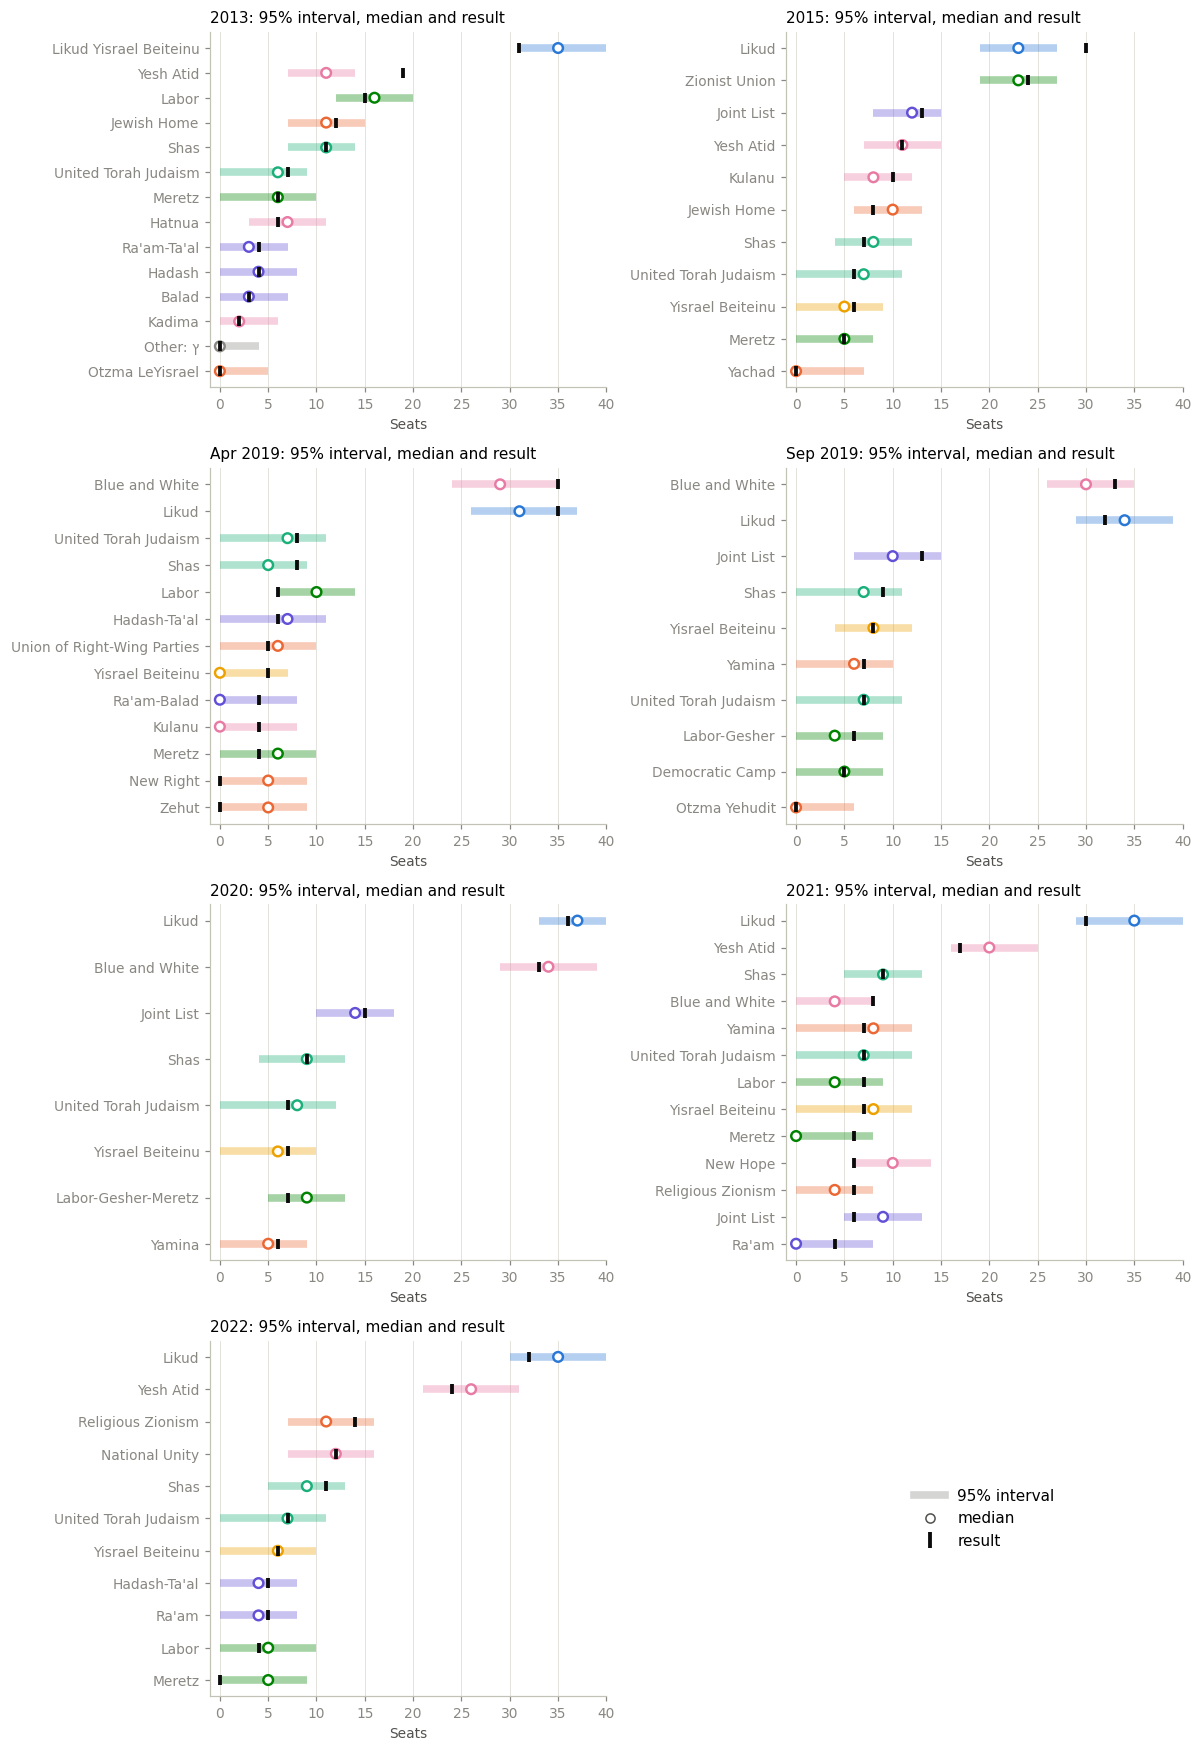

In [55]:

fig, axes = plt.subplots(4, 2, figsize=(11, 16))
for ax, e in zip(axes.flat, PAST):
    run = backtests[(e, True)]
    seats = run["seats"]
    order_ = run["result"].sort_values().index
    y = np.arange(len(order_))
    family = list_votes[list_votes["election"] == e].set_index("list")["family"]
    colours = [FAMILY_COLORS[family[name]] for name in order_]
    ax.hlines(y, seats.quantile(LOW)[order_], seats.quantile(HIGH)[order_], color=colours, linewidth=5, alpha=0.35)
    ax.scatter(seats.median()[order_], y, s=40, facecolor="white", edgecolor=colours, linewidth=1.6, zorder=3)
    ax.scatter(run["result"][order_], y, s=40, color="#0b0b0b", marker="|", linewidth=2.5, zorder=4)
    ax.set_yticks(y, order_)
    ax.grid(axis="y", visible=False)
    ax.set(xlabel="Seats", xlim=(-1, 40), title=f"{ELECTIONS.loc[e, 'label']}: {INTERVAL}% interval, median and result")
handles = [plt.Line2D([], [], color="#898781", linewidth=5, alpha=0.35, label=f"{INTERVAL}% interval"),
           plt.Line2D([], [], marker="o", linestyle="", markerfacecolor="white", markeredgecolor="#52514e", label="median"),
           plt.Line2D([], [], marker="|", linestyle="", color="#0b0b0b", markersize=10, markeredgewidth=2.5, label="result")]
axes.flat[-1].axis("off")
axes.flat[-1].legend(handles=handles, loc="center", fontsize=10)
fig.tight_layout()
plt.show()

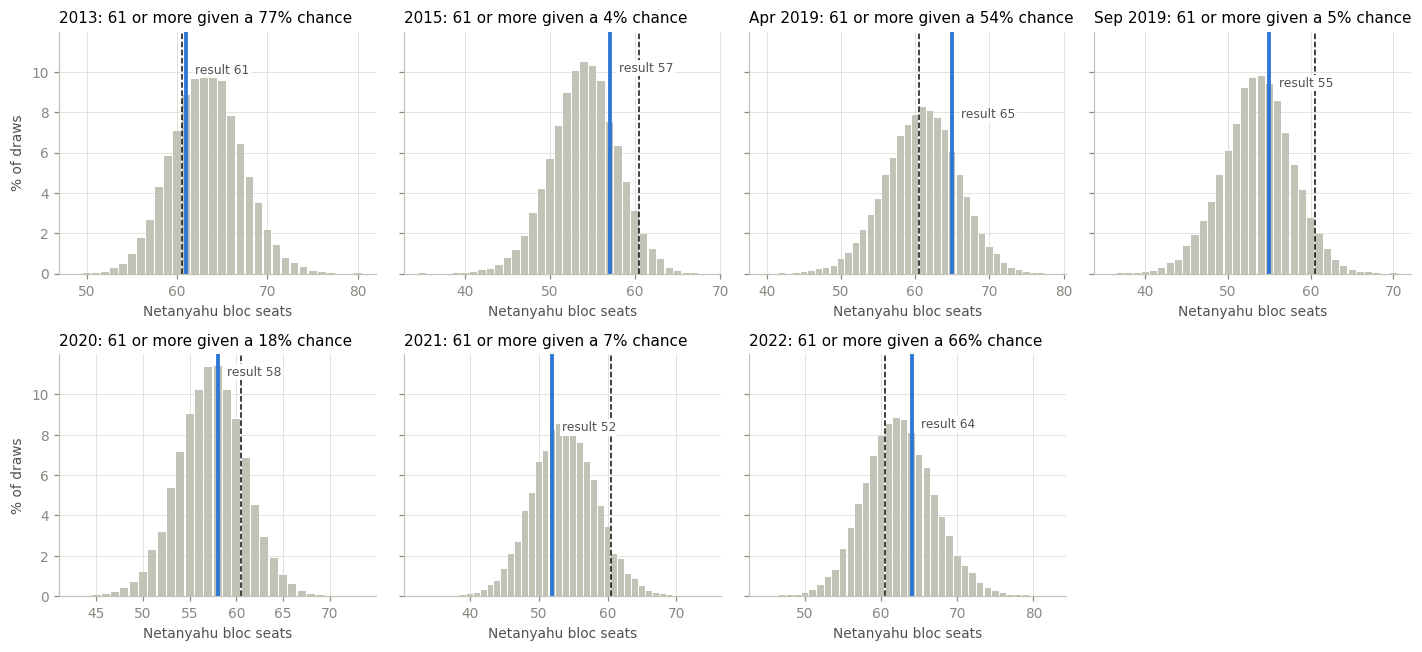

In [56]:

fig, axes = plt.subplots(2, 4, figsize=(13, 6), sharey=True)
for ax, e in zip(axes.flat, PAST):
    run = backtests[(e, True)]
    totals = run["seats"].T.groupby(run["bloc"]).sum().T["Netanyahu"]
    actual = run["result"].groupby(run["bloc"]).sum()["Netanyahu"]
    counts = 100 * totals.value_counts().sort_index() / len(totals)
    ax.bar(counts.index, counts, width=0.85, color="#c3c2b7")
    ax.axvline(60.5, color="#0b0b0b", linewidth=1, linestyle="--")
    ax.axvline(actual, color=FAMILY_COLORS["Likud"], linewidth=2.5)
    ax.annotate(f"result {actual}", (actual, counts.max()), xytext=(6, 0), textcoords="offset points",
                fontsize=8, color="#52514e", va="top", bbox=dict(facecolor="white", edgecolor="none", pad=1))
    ax.set(xlabel="Netanyahu bloc seats",
           title=f"{ELECTIONS.loc[e, 'label']}: 61 or more given a {(totals >= 61).mean():.0%} chance")
axes.flat[-1].axis("off")
for ax in axes[:, 0]:
    ax.set_ylabel("% of draws")
fig.tight_layout()
plt.show()

The eight misses outside the intervals are the big late moves the final polls did not see: Yesh Atid in 2013
(polled 11, won 19) and the Likud–Yisrael Beiteinu list that lost those votes; Likud in 2015 (median 23, won 30);
Likud and Blue and White in April 2019, both 35 against medians of 31 and 29; and in 2021 Blue and White (polled 4,
won 8), New Hope (10, won 6) and Likud, a miss the correction created by giving Likud a surplus that went to the
centre that year. A model built on the final polls cannot see a late swing the polls did not see.

### 7.3 Combining the polls and the flow model

Two forecasts of the same election: the polls (opinion today, with known errors) and the flow model (each place's
recent vote with 2026's population, which misses whatever has changed since). Weighting each by the inverse of its
error variance gives the combination with the smallest expected error, if the two errors are independent.

- **The polls' error**: the back-test shares of 7.2 (with the correction) against the results of the seven
  elections, by camp: the right-religious families, the centre-left with Yisrael Beiteinu, and the Arab lists.
- **The flow model's error**: each camp's share carried forward one election, for every pair from 2015 to 2022
  (2013 is left out: Yisrael Beiteinu ran inside Likud's list then). This error grows with the time between
  elections, so it is measured per year (variance divided by the years between the two elections) and scaled to the
  four years from 2022 to 2026.

In [57]:
CAMPS = {"Right-religious": ["Likud", "Right", "Haredi"], "Centre-left": ["Centre", "Left", "Yisrael Beiteinu"],
         "Arab lists": ["Arab lists"]}
family_share = list_votes.pivot_table(index="election", columns="family", values="share_pct", aggfunc="sum").fillna(0)
camp_share = pd.DataFrame({c: family_share[f].sum(axis=1) for c, f in CAMPS.items()})

carried = pd.DataFrame([{"from": ELECTIONS.loc[a, "label"], "to": ELECTIONS.loc[b, "label"],
                         "years": (ELECTIONS.loc[b, "date"] - ELECTIONS.loc[a, "date"]).days / 365.25,
                         **(camp_share.loc[a] - camp_share.loc[b]).to_dict()}
                        for a, b in zip(order[1:-1], order[2:])])
HORIZON_2026 = (ELECTION_DAY_2026 - ELECTIONS.loc["K25", "date"]).days / 365.25
flow_variance = (carried[list(CAMPS)] ** 2).sum() / carried["years"].sum() * HORIZON_2026

poll_camp_errors = {}
for e in PAST:
    family = list_votes[list_votes["election"] == e].set_index("list")["family"]
    poll = backtests[(e, True)]["shares"].drop("others")
    poll_camp = pd.Series({c: poll[family.reindex(poll.index).isin(f).to_numpy()].sum() for c, f in CAMPS.items()})
    poll_camp_errors[ELECTIONS.loc[e, "label"]] = poll_camp - camp_share.loc[e]
poll_variance = (pd.DataFrame(poll_camp_errors).T ** 2).mean()

POLL_WEIGHT = float(flow_variance.mean() / (poll_variance.mean() + flow_variance.mean()))
display(carried.round(2))
print(f"Weight on the polls: {POLL_WEIGHT:.2f}; on the flow model: {1 - POLL_WEIGHT:.2f}")
pd.DataFrame({"polls: error sd": np.sqrt(poll_variance),
              "flow model: error sd at 4 years": np.sqrt(flow_variance)}).round(2)

,from,to,years,Right-religious,Centre-left,Arab lists
0,2015,Apr 2019,4.06,-4.05,0.54,2.78
1,Apr 2019,Sep 2019,0.44,1.53,1.41,-2.78
2,Sep 2019,2020,0.46,-2.44,3.92,-2.07
3,2020,2021,1.06,0.48,-3.45,4.06
4,2021,2022,1.61,-1.25,3.40,-2.12


Weight on the polls: 0.78; on the flow model: 0.22


,polls: error sd,flow model: error sd at 4 years
Right-religious,1.99,3.72
Centre-left,2.93,4.64
Arab lists,1.86,4.61


Carried forward over four years, a camp's share misses by 3.7–4.6 points (one standard deviation); the polls
model, back-tested on seven elections, missed by 1.9–2.9 points. The weights come out at **78% for the polls and
22% for the flow model**, and the combination gives the Netanyahu bloc 55 seats before any uncertainty is added:
between the corrected polls' 54 and the flow model's 58.

Two caveats. The flow model's error rests mostly on elections less than two years apart, scaled up by an assumption
(error variance growing in proportion to the time between elections), and the polls' camp errors are measured on
shares rebuilt from seats. The single-model and equal-weight forecasts are in 7.5.

In [58]:
def combine(polls):
    return POLL_WEIGHT * polls + (1 - POLL_WEIGHT) * flow_2026.reindex(polls.index)


blended_2026 = combine(corrected_2026)
combination = pd.DataFrame({"list": LISTS_2026["list"], "bloc": BLOC_2026,
                            "polls (corrected) %": corrected_2026, "flow %": flow_2026, "combined %": blended_2026,
                            "polls seats": bader_ofer(corrected_2026, AGREEMENTS_2026),
                            "flow seats": bader_ofer(flow_2026, AGREEMENTS_2026),
                            "combined seats": bader_ofer(blended_2026, AGREEMENTS_2026)},
                           index=corrected_2026.index).drop(index="others")
display(combination.round(2))
combination.groupby("bloc")[["polls seats", "flow seats", "combined seats"]].sum()

,list,bloc,polls (corrected) %,flow %,combined %,polls seats,flow seats,combined seats
likud,Likud,Netanyahu,19.35,19.67,19.42,26,27,26
yashar,Yashar! with Eisenkot,Opposition,17.24,14.82,16.71,23,20,22
beyahad,Beyahad,Opposition,9.23,8.64,9.10,12,12,12
democrats,The Democrats,Opposition,7.30,8.40,7.54,9,11,10
otzma_yehudit,Otzma Yehudit,Netanyahu,5.94,5.98,5.95,7,7,7
joint_list,Joint List,Arab lists,6.61,6.26,6.53,8,8,8
utj,United Torah Judaism,Netanyahu,5.71,5.78,5.72,7,7,7
yisrael_beiteinu,Yisrael Beiteinu,Opposition,6.11,4.86,5.83,8,6,7
shas,Shas,Netanyahu,6.32,8.10,6.71,8,11,9
religious_zionism,Religious Zionism and Zehut,Netanyahu,5.00,5.04,5.01,6,6,6


,polls seats,flow seats,combined seats
bloc,,,
Arab lists,14,13,14
Netanyahu,54,58,55
Opposition,52,49,51


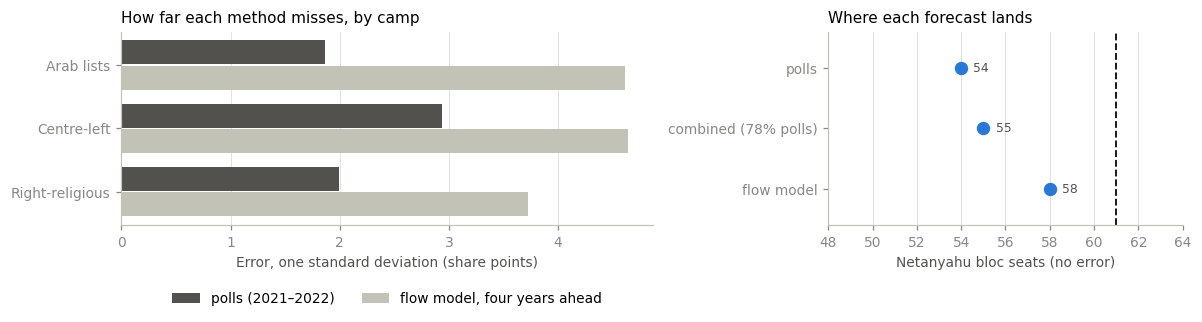

In [59]:
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.2), gridspec_kw={"width_ratios": [3, 2]})
camps = list(CAMPS)
y = np.arange(len(camps))
left.barh(y + 0.2, np.sqrt(poll_variance[camps]), height=0.38, color="#52514e", label="polls (2021–2022)")
left.barh(y - 0.2, np.sqrt(flow_variance[camps]), height=0.38, color="#c3c2b7", label="flow model, four years ahead")
left.set_yticks(y, camps)
left.grid(axis="y", visible=False)
left.set(xlabel="Error, one standard deviation (share points)", title="How far each method misses, by camp")
left.legend(loc="upper center", bbox_to_anchor=(0.5, -0.28), ncol=2)

bloc_seats = combination.groupby("bloc")[["polls seats", "combined seats", "flow seats"]].sum().loc["Netanyahu"]
labels = ["polls", f"combined ({POLL_WEIGHT:.0%} polls)", "flow model"]
yy = np.arange(len(labels))[::-1]
right.axvline(61, color="#0b0b0b", linewidth=1.2, linestyle="--")
right.scatter(bloc_seats.to_numpy(), yy, s=60, color=FAMILY_COLORS["Likud"], zorder=3)
for value, level in zip(bloc_seats, yy):
    right.annotate(f"{value:.0f}", (value, level), xytext=(8, 0), textcoords="offset points", va="center", fontsize=8,
                   color="#52514e")
right.set_yticks(yy, labels)
right.grid(axis="y", visible=False)
right.set(xlim=(48, 64), ylim=(-0.6, 2.6), xlabel="Netanyahu bloc seats (no error)", title="Where each forecast lands")
fig.tight_layout()
plt.show()

### 7.4 The 2026 forecast

The combined forecast of 7.3, with the errors of the polls model, 20,000 simulated elections.

In [60]:
FORECAST_DRAWS = 20_000
drawn_2026, seats_2026 = simulate(blended_2026, AGREEMENTS_2026, n=FORECAST_DRAWS)
per_list_2026, per_bloc_2026, totals_2026 = summarize(seats_2026, BLOC_2026)
totals_2026["Opposition + Arab lists"] = totals_2026["Opposition"] + totals_2026["Arab lists"]
BLOC_ORDER = ["Netanyahu", "Opposition", "Arab lists"]

forecast_table = pd.DataFrame({
    "list": LISTS_2026["list"], "bloc": BLOC_2026, "poll share %": average_2026, "corrected share %": corrected_2026,
    "flow share %": flow_2026, "combined share %": blended_2026,
    "median seats": per_list_2026["median"],
    f"{INTERVAL}% interval": [f"{lo:.0f}–{hi:.0f}" for lo, hi in zip(per_list_2026["low"], per_list_2026["high"])],
    "P(pass)": per_list_2026["P(pass)"],
}, index=per_list_2026.index)
forecast_table["bloc"] = pd.Categorical(forecast_table["bloc"], BLOC_ORDER)
forecast_table = forecast_table.sort_values(["bloc", "median seats", "combined share %"], ascending=[True, False, False])
forecast_table.style.format({"poll share %": "{:.2f}", "corrected share %": "{:.2f}", "flow share %": "{:.2f}",
                             "combined share %": "{:.2f}", "median seats": "{:.0f}",
                             "P(pass)": "{:.0%}"}).hide(axis="index")

list,bloc,poll share %,corrected share %,flow share %,combined share %,median seats,95% interval,P(pass)
Likud,Netanyahu,17.31,19.35,19.67,19.42,25,21–30,100%
Shas,Netanyahu,6.32,6.32,8.10,6.71,8,4–13,99%
Otzma Yehudit,Netanyahu,6.47,5.94,5.98,5.95,7,0–11,96%
United Torah Judaism,Netanyahu,5.71,5.71,5.78,5.72,7,0–11,94%
Religious Zionism and Zehut,Netanyahu,5.45,5.00,5.04,5.01,6,0–10,87%
Amkha Yisrael,Netanyahu,2.83,2.60,3.22,2.73,0,0–7,37%
Yashar! with Eisenkot,Opposition,17.24,17.24,14.82,16.71,21,17–26,100%
Beyahad,Opposition,10.05,9.23,8.64,9.10,12,7–16,100%
The Democrats,Opposition,7.30,7.30,8.40,7.54,9,5–14,100%
Yisrael Beiteinu,Opposition,6.11,6.11,4.86,5.83,7,0–11,95%


In [61]:
def bloc_summary(totals):
    return pd.DataFrame({b: {"median": totals[b].median(),
                             f"{INTERVAL}% interval": f"{totals[b].quantile(LOW):.0f}–{totals[b].quantile(HIGH):.0f}",
                             "P(61+)": (totals[b] >= 61).mean()}
                         for b in BLOC_ORDER + ["Opposition + Arab lists"]}).T


bloc_table = bloc_summary(totals_2026)
bloc_table.style.format({"median": "{:.0f}", "P(61+)": "{:.1%}"})

,median,95% interval,P(61+)
Netanyahu,55,46–64,11.3%
Opposition,52,44–61,3.0%
Arab lists,13,5–19,0.0%
Opposition + Arab lists,65,56–74,83.8%


- **No bloc reaches 61 in most simulated elections.** The Netanyahu bloc's median is 55 seats (95% interval 46–64),
  and it reaches 61 in 11% of the draws, about one in nine.
- **The opposition alone reaches 61 in 3% of the draws.** With the Arab lists it does in 84%: a majority without the
  Netanyahu bloc depends on the Arab lists in almost every draw.
- **Likud is the largest list**, 25 seats (21–30), ahead of Yashar! with 21 (17–26). The correction of 5.2 is worth
  about two of Likud's seats.
- **Ra'am passes in 77% of the draws**, Hendel and Zelekha in 45%, Amkha Yisrael in 37%.

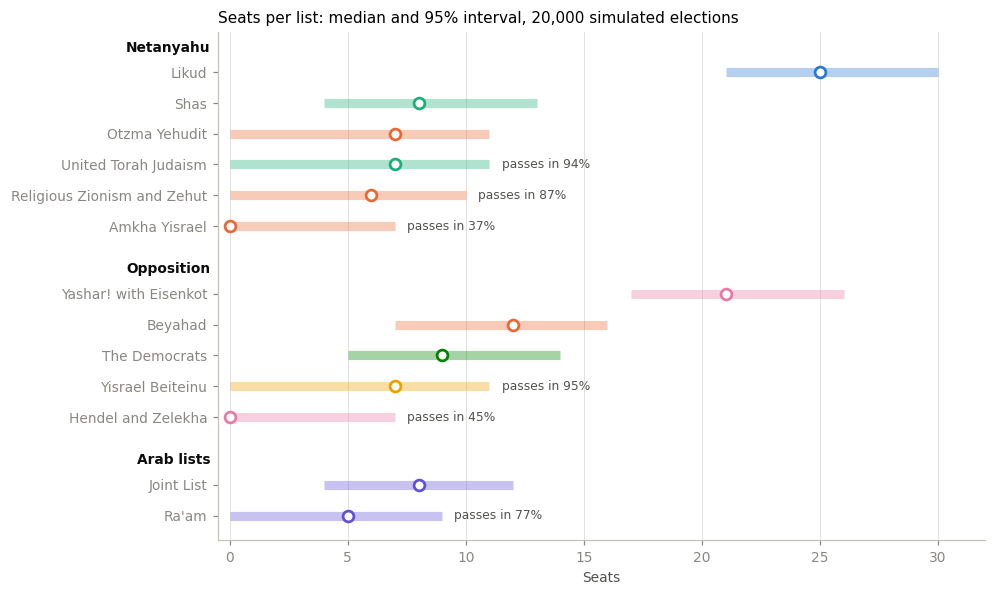

In [62]:
fig, ax = plt.subplots(figsize=(9, 6))
y, ticks, labels = 0, [], []
for bloc in reversed(BLOC_ORDER):
    rows = forecast_table[forecast_table["bloc"] == bloc].iloc[::-1]
    for key, row in rows.iterrows():
        colour = FAMILY_COLORS[FAMILY_2026[key]]
        low, high = per_list_2026.loc[key, ["low", "high"]]
        ax.hlines(y, low, high, color=colour, linewidth=6, alpha=0.35)
        ax.scatter(row["median seats"], y, s=50, facecolor="white", edgecolor=colour, linewidth=1.8, zorder=3)
        if row["P(pass)"] < 0.95:
            ax.annotate(f"passes in {row['P(pass)']:.0%}", (high, y), xytext=(8, 0), textcoords="offset points",
                        va="center", fontsize=8, color="#52514e")
        ticks.append(y)
        labels.append(row["list"])
        y += 1
    ax.text(-0.01, y - 0.2, bloc, transform=ax.get_yaxis_transform(), ha="right", va="center", fontsize=9,
            fontweight="bold", color="#0b0b0b")
    y += 1.2
ax.set_ylim(-0.8, y - 0.9)
ax.set_yticks(ticks, labels)
ax.grid(axis="y", visible=False)
ax.set(xlim=(-0.5, 32), xlabel="Seats", title=f"Seats per list: median and {INTERVAL}% interval, 20,000 simulated elections")
plt.show()

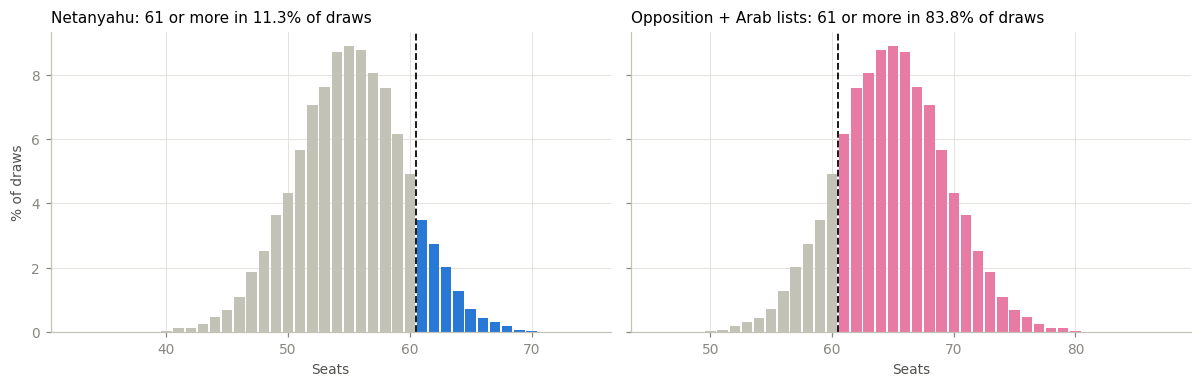

In [63]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, (name, colour) in zip(axes, [("Netanyahu", FAMILY_COLORS["Likud"]),
                                     ("Opposition + Arab lists", FAMILY_COLORS["Centre"])]):
    counts = totals_2026[name].value_counts().sort_index()
    ax.bar(counts.index, counts / FORECAST_DRAWS * 100, width=0.85,
           color=[colour if s >= 61 else "#c3c2b7" for s in counts.index])
    ax.axvline(60.5, color="#0b0b0b", linewidth=1.2, linestyle="--")
    ax.set(xlabel="Seats", title=f"{name}: 61 or more in {(totals_2026[name] >= 61).mean():.1%} of draws")
axes[0].set_ylabel("% of draws")
fig.tight_layout()
plt.show()

#### What the threshold lists decide

Two lists sit just under the threshold, one in each camp: Amkha Yisrael counts in the Netanyahu bloc, Hendel and
Zelekha in the opposition. The draws split four ways by which of them passes.

In [64]:
amkha_passes = seats_2026["amkha_yisrael"] > 0
hendel_passes = seats_2026["hendel_zelekha"] > 0
rows = {}
for amkha in (True, False):
    for hendel in (True, False):
        mask = (amkha_passes == amkha) & (hendel_passes == hendel)
        t = totals_2026[mask]
        rows[(f"Amkha Yisrael {'passes' if amkha else 'fails'}", f"Hendel and Zelekha {'passes' if hendel else 'fails'}")] = {
            "% of draws": 100 * mask.mean(), "Netanyahu median": t["Netanyahu"].median(),
            "P(Netanyahu 61+)": (t["Netanyahu"] >= 61).mean(), "Opposition median": t["Opposition"].median(),
            "P(Opposition + Arab 61+)": (t["Opposition + Arab lists"] >= 61).mean()}
conditional = pd.DataFrame(rows).T
conditional.style.format({"% of draws": "{:.0f}", "Netanyahu median": "{:.0f}", "Opposition median": "{:.0f}",
                          "P(Netanyahu 61+)": "{:.1%}", "P(Opposition + Arab 61+)": "{:.1%}"})

When Amkha Yisrael passes and Hendel and Zelekha fails (about one draw in five), the Netanyahu bloc's median is 58
and its chance of 61 is 26%. In the opposite case (about three draws in ten) it is 53 and 3%. The two small lists
move the bloc by five seats between its best and worst case.

In [65]:
OUTPUTS = Path("outputs")
OUTPUTS.mkdir(exist_ok=True)
forecast_table.round({"poll share %": 2, "corrected share %": 2, "flow share %": 2, "combined share %": 2, "P(pass)": 3}).to_csv(
    OUTPUTS / "forecast_2026_lists.csv", index_label="key")
bloc_table.assign(**{"P(61+)": bloc_table["P(61+)"].astype(float).round(3)}).to_csv(
    OUTPUTS / "forecast_2026_blocs.csv", index_label="bloc")
print("Saved to outputs/: forecast_2026_lists.csv, forecast_2026_blocs.csv")

Saved to outputs/: forecast_2026_lists.csv, forecast_2026_blocs.csv


### 7.5 Sensitivity

The forecast rests on choices made in sections 5–7. Each row below changes one of them and reruns the 20,000
draws with the same random numbers, so the differences are the effect of that choice alone.

- **Polls only, flow only, equal weights**: the two models alone, and an even split instead of the weight of 7.3.
- **No poll correction**: the polls as published, combined with the flow model.
- **Right surplus shared by all lists**: the Right's 2.0 points taken away as in 5.2, but spread over every other
  list by size instead of given to Likud.
- **Bloc swing**: a shared error moving votes between the Netanyahu bloc and the opposition, with a standard deviation
  of one list error (1.6 points). Its size is hand-set; 5.5 found no shared swing to measure.
- **Polls weighted by sample size**: every poll of the final week, weighted by its respondents (section 5.4).
- **Arab turnout as in 2021 or 2020**: the Arab lists' total share from the turnout model of section 6 at that
  election's Arab turnout, split between the Joint List and Ra'am as in the polls, and the other lists rescaled.

In [66]:
def poll_shares(rows):
    """Each poll's list shares summing to 100 with "others", Blue and White folded into the opposition."""
    raw = rows[share_columns].fillna(0)
    raw.columns = [c.removesuffix("_pct") for c in raw.columns]
    out = raw.div(raw.sum(axis=1), axis=0) * 100
    withdrawn = out.pop("blue_white")
    out[opposition] += out[opposition].mul(withdrawn / out[opposition].sum(axis=1), axis=0)
    out["others"] = out.drop(columns=on_ballot).sum(axis=1)
    return out[list(on_ballot) + ["others"]]


assert np.allclose(poll_shares(with_shares.reset_index()).mean(), average_2026[list(on_ballot) + ["others"]])

week = k26[(k26["date"] > k26["date"].max() - pd.Timedelta(days=7)) & k26[share_columns].notna().any(axis=1)]
weighted_2026 = poll_shares(week).mul(week["respondents"].to_numpy(), axis=0).sum() / week["respondents"].sum()


def with_arab_turnout(shares, turnout):
    """The Arab lists' total share from the turnout model, split as in the polls; the other lists rescaled."""
    target = sector_model({**PARAMS_2026, "turnout_arab": turnout})["arab_lists_share"]
    arab = ["joint_list", "raam"]
    out = shares.copy()
    out[arab] *= target / shares[arab].sum()
    rest = shares.index.difference(arab)
    out[rest] *= (100 - target) / shares[rest].sum()
    return out


def run_scenario(shares, **options):
    _, seats = simulate(shares, AGREEMENTS_2026, n=FORECAST_DRAWS, **options)
    totals = seats.drop(columns="others").T.groupby(BLOC_2026).sum().T
    return {"Netanyahu": totals["Netanyahu"].median(),
            f"Netanyahu {INTERVAL}%": f"{totals['Netanyahu'].quantile(LOW):.0f}–{totals['Netanyahu'].quantile(HIGH):.0f}",
            "Opposition": totals["Opposition"].median(), "Arab lists": totals["Arab lists"].median(),
            "P(Netanyahu 61+)": (totals["Netanyahu"] >= 61).mean(),
            "P(Opposition + Arab 61+)": ((totals["Opposition"] + totals["Arab lists"]) >= 61).mean()}


sensitivity = pd.DataFrame({
    "Main forecast (polls and flow combined)": run_scenario(blended_2026),
    "Polls only": run_scenario(corrected_2026),
    "Flow only": run_scenario(flow_2026),
    "Equal weights": run_scenario(0.5 * corrected_2026 + 0.5 * flow_2026),
    "No poll correction": run_scenario(combine(average_2026)),
    "Right surplus shared by all lists, not moved to Likud":
        run_scenario(combine(apply_correction(average_2026, FAMILY_2026, POLL_CORRECTION, counterpart={}))),
    f"Bloc swing of {LIST_ERROR_POINTS:.1f} points (hand-set)": run_scenario(blended_2026, bloc_swing=LIST_ERROR_POINTS, bloc=BLOC_2026),
    "Polls weighted by sample size": run_scenario(combine(apply_correction(weighted_2026, FAMILY_2026, POLL_CORRECTION))),
    f"Arab turnout as in 2021 ({100 * history.loc['K24', 'turnout_arab']:.0f}%)":
        run_scenario(with_arab_turnout(blended_2026, history.loc["K24", "turnout_arab"])),
    f"Arab turnout as in 2020 ({100 * history.loc['K23', 'turnout_arab']:.0f}%)":
        run_scenario(with_arab_turnout(blended_2026, history.loc["K23", "turnout_arab"])),
}).T
sensitivity.style.format({"Netanyahu": "{:.0f}", "Opposition": "{:.0f}", "Arab lists": "{:.0f}",
                          "P(Netanyahu 61+)": "{:.1%}", "P(Opposition + Arab 61+)": "{:.1%}"})

,Netanyahu,Netanyahu 95%,Opposition,Arab lists,P(Netanyahu 61+),P(Opposition + Arab 61+)
Main forecast (polls and flow combined),55,46–64,52,13,11.3%,83.8%
Polls only,54,45–63,53,14,6.8%,89.5%
Flow only,59,50–69,49,12,40.6%,51.0%
Equal weights,57,48–66,51,13,19.3%,73.8%
No poll correction,54,46–63,53,13,8.6%,87.6%
"Right surplus shared by all lists, not moved to Likud",54,45–63,53,14,6.6%,89.9%
Bloc swing of 1.6 points (hand-set),55,45–65,52,13,13.9%,81.0%
Polls weighted by sample size,57,48–66,50,13,23.1%,69.1%
Arab turnout as in 2021 (44%),56,47–65,53,11,17.4%,76.3%
Arab turnout as in 2020 (64%),54,45–62,51,16,5.8%,91.0%


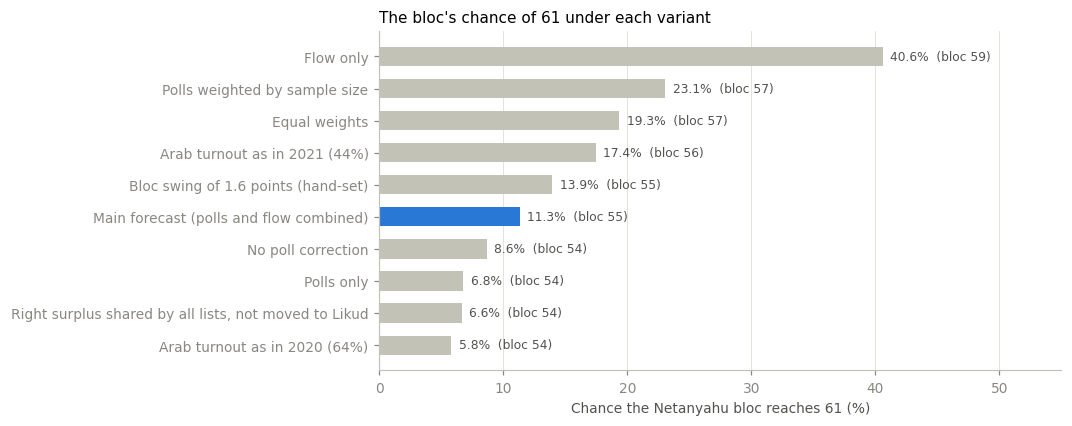

In [67]:
chance = sensitivity["P(Netanyahu 61+)"].astype(float).sort_values()
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(chance.index, 100 * chance, height=0.6,
        color=[FAMILY_COLORS["Likud"] if name.startswith("Main") else "#c3c2b7" for name in chance.index])
for y, name in enumerate(chance.index):
    ax.annotate(f"{100 * chance[name]:.1f}%  (bloc {sensitivity.loc[name, 'Netanyahu']:.0f})", (100 * chance[name], y),
                xytext=(5, 0), textcoords="offset points", va="center", fontsize=8, color="#52514e")
ax.set_xlim(0, 55)
ax.grid(axis="y", visible=False)
ax.set(xlabel="Chance the Netanyahu bloc reaches 61 (%)", title="The bloc's chance of 61 under each variant")
plt.show()

- **The weight on the flow model matters most.** Polls alone give the Netanyahu bloc 54 seats and a 7% chance of
  61; equal weights 57 and 19%; the flow model alone 59 and 41%.
- **Every variant but the flow model alone leaves the bloc short of 61 in most draws**; its chance of 61 runs from
  6% to 23%.
- **How the polls are averaged matters next.** Weighting them by sample size gives Next Data, the pollster with by
  far the largest Likud, 44% of the weight among the polls that print shares: the bloc's median rises to 57 and its
  chance of 61 to 23%.
- **Arab turnout moves the Arab lists two to three seats each way**: 11 at 2021's turnout (the bloc 56, a 17% chance
  of 61), 16 at 2020's (the bloc 54, 6%).
- **The poll correction is worth a seat and a few points of probability**: 54 seats and a 9% chance without it, 7%
  with the Right's surplus shared over all lists instead of moved to Likud. The bloc swing adds spread, not seats
  (14%).

### 7.6 The forecast in one paragraph

On the polls of 15–21 October, corrected for the final polls' habit since 2013 of overstating the parties to
Likud's right at Likud's expense, and combined with a flow model of every polling place (78% polls, 22% flow), the
Netanyahu bloc wins about 55 seats (95% interval 46–64) and reaches 61 in about one simulated election in nine. The
opposition and the Arab lists together win about 65. The largest uncertainties are how much weight the flow model
deserves, the two lists just under the threshold, and how the polls are averaged.

## 8. Limitations and scoring after the election

### 8.1 Limitations

- **Seats-only polls.** The 2013–2022 polls publish seats, not vote shares, so the shares behind them are rebuilt
  from the seats (7.2), and a list a pollster shows under the threshold counts as nothing. The 2026 run uses the
  printed shares, so the back-test checks a slightly different input.
- **The correction is one pattern, aimed at Likud.** The Right's surplus is moved to Likud because that is where it
  went in 2015 and April 2019; in 2021 it went to the centre, and the back-test's 2021 fold is worse with the
  correction than without. In 2026 the Right family includes Beyahad, an opposition list, so the correction also
  moves 0.8 points across the blocs. The rule's choice of families moves between folds (the Haredi parties in the
  2015 fold, the Left in the 2021 fold).
- **The Haredi lean is left in.** The Haredi parties are under-polled in six of the seven elections, by 0.7 points
  on average, under the rule's one-seat bar; a correction would be worth about a seat to the bloc.
- **The polls carry most of the weight.** The model corrects one known bias and adds a flow model at 22%, but it
  cannot see a late shift the polls miss, as with Likud in 2015 or Blue and White in 2021.
- **The flow model's camps.** It carries 2022's Likud, Religious Zionism and centre votes into today's lists and
  splits them between the new lists by the polls, so who Beyahad or Yashar! take their voters from is an assumption.
- **The weight between the two models** rests on seven elections of polls and five pairs of elections for the flow
  model, most of them less than two years apart, scaled to four years by assumption.
- **Independent list errors.** Lists of one camp may be missed together. The seven elections show no shared bloc
  swing beyond what independent errors produce (5.5), and the bloc-swing sensitivity covers it only roughly, at a
  hand-set size.
- **One error size for every list.** A list at 3% gets the same 1.6-point error as one at 17%, which piles draws at
  zero for the small lists and makes the intervals of the large ones slightly wide: the back-test's 95% intervals
  caught 98% of the results.
- **No pollster house effects.** The pollsters disagree widely in 2026 (Likud 18–30 seats), and the average gives
  each one vote; section 7.5 shows how much the weighting matters.
- **Turnout.** The roll forecast overshot the published 2026 roll by 1% (2.7% in the Arab sector), voters living
  abroad enter only as a lever of the scenario (9), and Arab turnout enters through the polls, the flow model's place averages and the scenarios.
- **The polls end on 21 October**, six days before the election.

### 8.2 Scoring after the election

Once the CEC publishes the results, this section scores the forecast against them, with the poll average as
published as the baseline:

- **per list**: how many results fall inside their 95% intervals, the seat error, and the Brier score of each
  list's chance of passing the threshold;
- **the bloc**: the Netanyahu bloc's result against its forecast interval, and the probability the forecast gave to
  what happened (61 or more, or not).

To run it:

1. Save the CEC's results by locality as `data/cec_results/k26_2026/results_by_town.csv`, converted to UTF-8 like
   the other years.
2. Fill in `LETTERS_2026` with each list's ballot letters from the CEC's list of the 2026 lists.
3. Run the notebook.

The 2026 seats are counted with `bader_ofer` and the five 2026 surplus agreements of `data/lists_2026.csv`.

In [68]:
def score_forecast(seats, actual, bloc, baseline):
    """Scores simulated seats (draws x lists) against the actual seats, next to a baseline seat count."""
    lists = actual.index
    draws = seats[lists]
    low, high, median, passes = draws.quantile(LOW), draws.quantile(HIGH), draws.median(), (draws > 0).mean()
    side = bloc.reindex(lists)
    bloc_draws = draws.T.groupby(side).sum().T["Netanyahu"]
    bloc_actual = actual.groupby(side).sum()["Netanyahu"]
    p61 = (bloc_draws >= 61).mean()
    return pd.DataFrame({
        "forecast": {
            f"results inside the {INTERVAL}% interval": f"{((actual >= low) & (actual <= high)).sum()} of {len(lists)}",
            "seat error per list (median)": f"{(median - actual).abs().mean():.2f}",
            "Brier score, pass or fail": f"{((passes - (actual > 0)) ** 2).mean():.3f}",
            "Netanyahu bloc, forecast against result":
                f"{bloc_draws.median():.0f} ({bloc_draws.quantile(LOW):.0f}–{bloc_draws.quantile(HIGH):.0f}) vs {bloc_actual}",
            "probability given to what happened": f"{(p61 if bloc_actual >= 61 else 1 - p61):.0%}"},
        "polls as published": {
            f"results inside the {INTERVAL}% interval": "–",
            "seat error per list (median)": f"{(baseline[lists] - actual).abs().mean():.2f}",
            "Brier score, pass or fail": f"{(((baseline[lists] > 0).astype(float) - (actual > 0)) ** 2).mean():.3f}",
            "Netanyahu bloc, forecast against result": f"{baseline[lists].groupby(side).sum()['Netanyahu']:.0f} vs {bloc_actual}",
            "probability given to what happened": "–"},
    })

The scoring, run on the 2022 back-test to show what it reports:

In [69]:
run_2022 = backtests[("K25", True)]
score_forecast(run_2022["seats"], run_2022["result"], run_2022["bloc"], backtests[("K25", False)]["central"])

,forecast,polls as published
results inside the 95% interval,11 of 11,–
seat error per list (median),1.64,1.27
"Brier score, pass or fail",0.081,0.091
"Netanyahu bloc, forecast against result",62 (54–72) vs 64,60 vs 64
probability given to what happened,66%,–


#### 2026

In [70]:
RESULTS_2026 = DATA / "cec_results" / "k26_2026" / "results_by_town.csv"
LETTERS_2026 = {}   # ballot letters -> list key in lists_2026.csv, from the CEC's list of the 2026 lists

if RESULTS_2026.exists() and LETTERS_2026:
    results_2026, letters_2026 = clean(pd.read_csv(RESULTS_2026, encoding="utf-8-sig"))
    votes_2026 = results_2026[letters_2026].sum().rename(index=LETTERS_2026)
    votes_2026 = votes_2026.groupby(lambda key: key if key in on_ballot else "others").sum()
    actual_2026 = bader_ofer(votes_2026, AGREEMENTS_2026).drop("others")
    display(score_forecast(seats_2026, actual_2026, BLOC_2026, bader_ofer(average_2026, AGREEMENTS_2026)))
else:
    print("The 2026 results are not in data/ yet. The forecast above was made before the election; "
          "see the steps at the top of this section to score it.")

The 2026 results are not in data/ yet. The forecast above was made before the election; see the steps at the top of this section to score it.


## 9. The scenario: hand-set turnouts on the 2026 electorate

The main forecast carries turnout from the past: the polls' respondents and each polling place's recent turnout.
This section replaces it with expectations set by hand, one for each of three groups of voters, applied to the
2026 electorate from the growth trends of 6.2. The turnouts are beliefs, not estimates from the data; each is shown
next to its 2022 value so that the reader can judge it.

How the scenario is built:

1. **The electorate.** The 2026 roll by group from the growth trends of 6.2: Haredi voters growing 4.5% a year, the
   Arab sector 3.1%, other Jewish voters 1.5%. The forecast roll is 1% above the published 2026 roll in total and
   2.7% above it in the Arab sector (6.1); the table below shows both.
2. **The votes.** Each group's roll times its turnout, less 2022's invalid rate: the Arab sector with its double
   envelopes as in 6.3, the Haredi group at the ballot boxes, the other Jewish voters with the rest of the double
   envelopes. This is the two-sector model of 6.3 with the Haredi boxes (6.2's definition: the Haredi lists at 60%
   or more of the vote) taken out of the Jewish sector.
3. **Who gets them.** The Arab lists take their loyalty share of the Arab sector's vote and 2022's small shares of
   the other two groups. The Haredi lists take 2022's share of the Haredi group's vote and of the other Jewish vote.
   These two totals replace the main forecast's; every other list takes what is left in the main forecast's
   proportions, so the polls still decide the centre and Likud. The Joint List and Ra'am split as set below, Shas
   and UTJ as in the main forecast.
4. **The simulation.** 20,000 elections as in 7.4: each draws its own turnouts and loyalty, uniform within the ranges
   set, and every list gets the poll error of 5.5.

The settings:

| Setting | What it does | `None` means |
|---|---|---|
| `arab_turnout` | Arab turnout at the ballot boxes, %, a value or a (low, high) range | – |
| `haredi_turnout` | turnout at the Haredi boxes, % | – |
| `jewish_turnout` | other Jewish turnout with the double envelopes, % | – |
| `arab_loyalty` | % of the Arab sector's valid votes that go to the Arab lists | – |
| `haredi_loyalty` | % of the Haredi group's valid votes that go to Shas and UTJ | 2022's |
| `joint_list_share` | the Joint List's % of the two Arab lists' votes | the main forecast's split |
| `poll_weight` | % weight of the polls against the flow model | the weight of 7.3 (78%) |
| `list_adjustments` | share points added to or taken from lists, e.g. `{"likud": 1.0, "yashar": -1.0}` | no change |

In [71]:
THREE_GROUPS = ["Arab sector", "Haredi", "Other Jewish"]


def group_parameters_2022():
    """The three-group turnout model as it was in 2022: each group's roll, turnout and invalid rate, and the share
    of each group's valid votes that went to the Arab lists and to the Haredi lists."""
    g = (boxes[boxes["election"] == "K25"].groupby("growth_group")
              [["registered", "voted", "invalid", "valid", "Haredi", "Arab lists"]].sum())
    h, total = history.loc["K25"], national.loc["K25"]
    votes = list_votes[list_votes["election"] == "K25"].groupby("family")["votes"].sum()
    ballots_arab = g.loc["Arab sector", "registered"] * h["turnout_arab"] * h["envelope_factor"]
    valid_arab = ballots_arab * (1 - h["invalid_arab"])
    valid_haredi = g.loc["Haredi", "valid"]
    ballots_other = total["voted"] - ballots_arab - g.loc["Haredi", "voted"]
    valid_other = total["valid"] - valid_arab - valid_haredi
    p = {"roll_arab": g.loc["Arab sector", "registered"], "turnout_arab": h["turnout_arab"],
         "envelope_factor": h["envelope_factor"], "invalid_arab": h["invalid_arab"], "loyalty": h["loyalty"],
         "haredi_in_arab": g.loc["Arab sector", "Haredi"] / g.loc["Arab sector", "valid"],
         "roll_haredi": g.loc["Haredi", "registered"],
         "turnout_haredi": g.loc["Haredi", "voted"] / g.loc["Haredi", "registered"],
         "invalid_haredi": g.loc["Haredi", "invalid"] / g.loc["Haredi", "voted"],
         "haredi_loyalty": g.loc["Haredi", "Haredi"] / valid_haredi,
         "arab_in_haredi": g.loc["Haredi", "Arab lists"] / valid_haredi,
         "roll_other": g.loc["Other Jewish", "registered"],
         "turnout_other": ballots_other / g.loc["Other Jewish", "registered"],
         "invalid_other": 1 - valid_other / ballots_other}
    p["haredi_in_other"] = (votes["Haredi"] - p["haredi_loyalty"] * valid_haredi - p["haredi_in_arab"] * valid_arab) / valid_other
    p["arab_in_other"] = (votes["Arab lists"] - p["loyalty"] * valid_arab - p["arab_in_haredi"] * valid_haredi) / valid_other
    return pd.Series(p)


def group_model(p):
    """Valid votes, and the Arab lists' and Haredi lists' shares of them, for one setting or for arrays of them."""
    valid_arab = p["roll_arab"] * p["turnout_arab"] * p["envelope_factor"] * (1 - p["invalid_arab"])
    valid_haredi = p["roll_haredi"] * p["turnout_haredi"] * (1 - p["invalid_haredi"])
    valid_other = p["roll_other"] * p["turnout_other"] * (1 - p["invalid_other"])
    valid = valid_arab + valid_haredi + valid_other
    arab_lists = p["loyalty"] * valid_arab + p["arab_in_haredi"] * valid_haredi + p["arab_in_other"] * valid_other
    haredi_lists = p["haredi_loyalty"] * valid_haredi + p["haredi_in_arab"] * valid_arab + p["haredi_in_other"] * valid_other
    return {"valid": valid, "arab_lists_share": 100 * arab_lists / valid, "haredi_lists_share": 100 * haredi_lists / valid}


GROUP_2022 = group_parameters_2022()
replay_2022 = group_model(GROUP_2022)
family_2022 = 100 * list_votes[list_votes["election"] == "K25"].groupby("family")["votes"].sum() / national.loc["K25", "valid"]
assert np.isclose(replay_2022["valid"], national.loc["K25", "valid"])
assert np.isclose(replay_2022["arab_lists_share"], family_2022["Arab lists"])
assert np.isclose(replay_2022["haredi_lists_share"], family_2022["Haredi"])

GROUP_2026 = GROUP_2022.copy()                                                  # 2022's rates on the 2026 electorate
GROUP_2026[["roll_arab", "roll_haredi", "roll_other"]] = group_2026[THREE_GROUPS].to_numpy()

electorate = pd.DataFrame({"roll 2022": group_roll.loc["K25"], "forecast 2026 (growth trends)": group_2026,
                           "growth per year %": 100 * annual_growth}).loc[THREE_GROUPS]
electorate["published 2026 roll"] = [check.loc["Arab sector", "published roll"], np.nan, np.nan]
electorate.loc["Haredi + Other Jewish"] = [group_roll.loc["K25", ["Haredi", "Other Jewish"]].sum(),
                                           group_2026[["Haredi", "Other Jewish"]].sum(), np.nan,
                                           check.loc["Jewish sector", "published roll"]]
print("The three-group model gives back 2022's valid votes, Arab-list share and Haredi-list share.")
print(f"2022: turnout {100 * GROUP_2022['turnout_arab']:.1f}% in the Arab sector (at the boxes), "
      f"{100 * GROUP_2022['turnout_haredi']:.1f}% at the Haredi boxes, {100 * GROUP_2022['turnout_other']:.1f}% among other "
      f"Jewish voters (with the envelopes); the Haredi lists won {100 * GROUP_2022['haredi_loyalty']:.1f}% of the Haredi "
      f"boxes' vote and {100 * GROUP_2022['haredi_in_other']:.1f}% of the other Jewish vote")
electorate.style.format("{:,.0f}", na_rep="").format("{:.1f}", subset=["growth per year %"], na_rep="")

The three-group model gives back 2022's valid votes, Arab-list share and Haredi-list share.
2022: turnout 52.6% in the Arab sector (at the boxes), 73.5% at the Haredi boxes, 73.4% among other Jewish voters (with the envelopes); the Haredi lists won 87.1% of the Haredi boxes' vote and 9.4% of the other Jewish vote


,roll 2022,forecast 2026 (growth trends),growth per year %,published 2026 roll
growth_group,,,,
Arab sector,"1,025,978","1,159,033",3.1,"1,126,536"
Haredi,"486,548","553,260",4.5,
Other Jewish,"5,276,278","5,691,065",1.5,
Haredi + Other Jewish,"5,762,826","6,244,325",,"6,205,445"


In [72]:
SCENARIO = {
    "arab_turnout": (64, 67),        # % at the ballot boxes; hand-set belief (2022: 52.6, 2013–2022: 44–64)
    "haredi_turnout": 75,            # % at all Haredi boxes; hand-set belief (2022: 73.5, 2013–2022 average 74.6)
    "jewish_turnout": (70, 72),      # other Jewish voters, % with the double envelopes; hand-set belief
    "arab_loyalty": (87, 88),        # % of the Arab sector's valid votes to the Arab lists; hand-set belief (2022: 85.1)
    "haredi_loyalty": None,          # % of the Haredi boxes' valid votes to Shas and UTJ; None = 2022's
    "joint_list_share": 60,          # the Joint List's % of the Arab lists' vote; hand-set; None = the main forecast's split
    "poll_weight": None,             # % weight of the polls against the flow model; None = 7.3's
    "list_adjustments": {},          # share points added to or taken from lists
    "voters_abroad": 810,            # thousand citizens on the roll who live abroad; CBS, October 2026 (7.3 million on the roll, 6.5 in Israel)
    "abroad_split": {"Arab sector": 5, "Haredi": 5, "Other Jewish": 90},   # % of them by group; hand-set, the CBS gives no split
}
VOTERS_ABROAD_2026 = 810             # the turnouts above are shares of the roll as published, which carries these voters
GROUP_KEYS = {"Arab sector": "arab", "Haredi": "haredi", "Other Jewish": "other"}
ARAB, HAREDI = ["joint_list", "raam"], ["shas", "utj"]


def setting(value, rng=None, n=1):
    """A number as it is; a (low, high) range as its midpoint, or as n uniform draws when rng is given."""
    if np.isscalar(value):
        return np.full(n, float(value))
    low, high = value
    return rng.uniform(low, high, n) if rng is not None else np.full(n, (low + high) / 2)


def abroad_factors(s):
    """Turnout multipliers by group when s["voters_abroad"] thousand voters are abroad instead of 2026's 810: anyone
    not abroad after all votes at the rate of the voters present, so a group's turnout of the roll rises with its
    share of the returning voters."""
    f = {}
    for group, key in GROUP_KEYS.items():
        roll, share = GROUP_2026[f"roll_{key}"], 1000 * s["abroad_split"][group] / 100
        f[key] = (1 - s["voters_abroad"] * share / roll) / (1 - VOTERS_ABROAD_2026 * share / roll)
    return f


def scenario_base(s):
    """The main forecast's shares at the chosen poll weight, with the list adjustments."""
    weight = POLL_WEIGHT if s["poll_weight"] is None else s["poll_weight"] / 100
    shares = weight * corrected_2026 + (1 - weight) * flow_2026.reindex(corrected_2026.index)
    for key, points in s["list_adjustments"].items():
        shares[key] += points
    shares = shares.clip(lower=0)
    return 100 * shares / shares.sum()


def scenario_matrix(s, rng=None, n=1):
    """n settings of the scenario as a share matrix (n x lists): the Arab and Haredi totals from the three-group
    model, the other lists filling what is left in the main forecast's proportions."""
    base, f = scenario_base(s), abroad_factors(s)
    p = {**GROUP_2026, "turnout_arab": f["arab"] * setting(s["arab_turnout"], rng, n) / 100,
         "turnout_haredi": f["haredi"] * setting(s["haredi_turnout"], rng, n) / 100,
         "turnout_other": f["other"] * setting(s["jewish_turnout"], rng, n) / 100,
         "loyalty": setting(s["arab_loyalty"], rng, n) / 100}
    if s["haredi_loyalty"] is not None:
        p["haredi_loyalty"] = setting(s["haredi_loyalty"], rng, n) / 100
    model = group_model(p)
    joint = base["joint_list"] / base[ARAB].sum() if s["joint_list_share"] is None else s["joint_list_share"] / 100
    shas = base["shas"] / base[HAREDI].sum()
    index = base.index
    rest = ~index.isin(ARAB + HAREDI + ["others"])
    out = np.tile(base.to_numpy(float), (n, 1))
    out[:, rest] *= ((100 - base["others"] - model["arab_lists_share"] - model["haredi_lists_share"]) / base[rest].sum())[:, None]
    out[:, index.get_loc("joint_list")] = model["arab_lists_share"] * joint
    out[:, index.get_loc("raam")] = model["arab_lists_share"] * (1 - joint)
    out[:, index.get_loc("shas")] = model["haredi_lists_share"] * shas
    out[:, index.get_loc("utj")] = model["haredi_lists_share"] * (1 - shas)
    return pd.DataFrame(out, columns=index)


def scenario_draws(s, n=FORECAST_DRAWS, seed=2026):
    """Simulated elections: each with its own turnouts and loyalty, and the poll error on every list."""
    rng = np.random.default_rng(seed)
    shares = scenario_matrix(s, rng, n)
    error = LIST_ERROR_POINTS * (shares.columns != "others").astype(float)
    drawn = np.clip(shares.to_numpy() + rng.normal(0, 1, shares.shape) * error, 0, None)
    drawn = 100 * drawn / drawn.sum(axis=1, keepdims=True)
    seats = bader_ofer_fast(drawn, agreement_units(shares.columns, AGREEMENTS_2026), 3.25)
    return pd.DataFrame(drawn, columns=shares.columns), pd.DataFrame(seats, columns=shares.columns)


scenario_2026 = scenario_matrix(SCENARIO).iloc[0]                       # the midpoint setting, before any error
_, scenario_seats = scenario_draws(SCENARIO)
scenario_lists, _, scenario_totals = summarize(scenario_seats, BLOC_2026)
scenario_totals["Opposition + Arab lists"] = scenario_totals["Opposition"] + scenario_totals["Arab lists"]

print(f"Arab lists: {scenario_2026[ARAB].sum():.2f}% of the vote in the scenario, {blended_2026[ARAB].sum():.2f}% in the main "
      f"forecast; Haredi lists: {scenario_2026[HAREDI].sum():.2f}% against {blended_2026[HAREDI].sum():.2f}%")


def bloc_table(totals):
    return pd.DataFrame({b: {"mean seats": totals[b].mean(), "median": totals[b].median(),
                             f"{INTERVAL}% interval": f"{totals[b].quantile(LOW):.0f}–{totals[b].quantile(HIGH):.0f}",
                             "P(61+)": (totals[b] >= 61).mean()}
                         for b in BLOC_ORDER + ["Opposition + Arab lists"]}).T


for name, totals in [("Main forecast (7.4)", totals_2026), ("Scenario", scenario_totals)]:
    display(bloc_table(totals).style.format({"mean seats": "{:.1f}", "median": "{:.0f}", "P(61+)": "{:.1%}"})
            .set_caption(name))

Arab lists: 13.90% of the vote in the scenario, 10.96% in the main forecast; Haredi lists: 14.19% against 12.43%


,mean seats,median,95% interval,P(61+)
Netanyahu,55.1,55,46–64,11.3%
Opposition,52.0,52,44–61,3.0%
Arab lists,12.9,13,5–19,0.0%
Opposition + Arab lists,64.9,65,56–74,83.8%


,mean seats,median,95% interval,P(61+)
Netanyahu,54.4,54,46–63,8.2%
Opposition,48.3,48,40–57,0.2%
Arab lists,17.2,17,10–23,0.0%
Opposition + Arab lists,65.6,66,57–74,87.8%


list,bloc,share %,mean seats,median,95% interval,P(pass)
Likud,Netanyahu,19.4,25.0,25,21–30,100%
Shas,Netanyahu,6.7,8.4,8,4–13,99%
Otzma Yehudit,Netanyahu,5.9,7.1,7,0–11,96%
United Torah Judaism,Netanyahu,5.7,7.0,7,0–11,94%
Religious Zionism and Zehut,Netanyahu,5.0,5.7,6,0–10,87%
Amkha Yisrael,Netanyahu,2.7,1.9,0,0–7,37%
Yashar! with Eisenkot,Opposition,16.7,21.6,21,17–26,100%
Beyahad,Opposition,9.1,11.6,12,7–16,100%
The Democrats,Opposition,7.5,9.4,9,5–14,100%
Yisrael Beiteinu,Opposition,5.8,7.1,7,0–11,95%


list,bloc,share %,mean seats,median,95% interval,P(pass)
Likud,Netanyahu,18.2,23.4,23,19–28,100%
Shas,Netanyahu,7.7,9.7,10,6–14,100%
United Torah Judaism,Netanyahu,6.5,8.1,8,4–12,98%
Otzma Yehudit,Netanyahu,5.6,6.5,7,0–11,93%
Religious Zionism and Zehut,Netanyahu,4.7,5.1,6,0–10,82%
Amkha Yisrael,Netanyahu,2.6,1.7,0,0–7,33%
Yashar! with Eisenkot,Opposition,15.7,20.1,20,16–25,100%
Beyahad,Opposition,8.5,10.8,11,7–15,100%
The Democrats,Opposition,7.1,8.8,9,5–13,99%
Yisrael Beiteinu,Opposition,5.5,6.5,7,0–11,92%


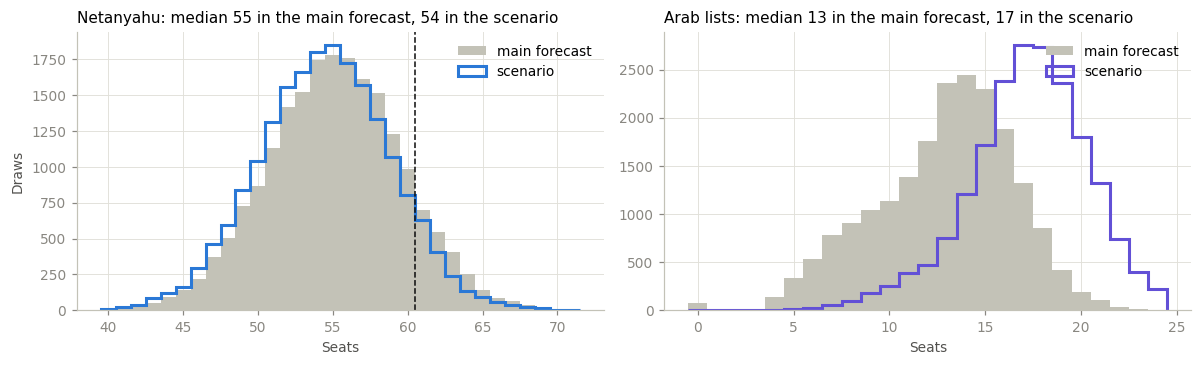

In [73]:
def list_table(shares, per_list):
    t = pd.DataFrame({"list": LISTS_2026["list"], "bloc": BLOC_2026, "share %": shares,
                      "mean seats": per_list["mean"], "median": per_list["median"],
                      f"{INTERVAL}% interval": [f"{lo:.0f}–{hi:.0f}" for lo, hi in zip(per_list["low"], per_list["high"])],
                      "P(pass)": per_list["P(pass)"]}, index=per_list.index)
    t["bloc"] = pd.Categorical(t["bloc"], BLOC_ORDER)
    return (t.sort_values(["bloc", "share %"], ascending=[True, False])
             .style.format({"share %": "{:.1f}", "mean seats": "{:.1f}", "median": "{:.0f}", "P(pass)": "{:.0%}"})
             .hide(axis="index"))


display(list_table(blended_2026, per_list_2026).set_caption("Main forecast (7.4)"))
display(list_table(scenario_2026, scenario_lists).set_caption("Scenario"))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for ax, (bloc, bins) in zip(axes, [("Netanyahu", np.arange(39.5, 72.5)), ("Arab lists", np.arange(-0.5, 25.5))]):
    ax.hist(totals_2026[bloc], bins=bins, color="#c3c2b7", label="main forecast")
    ax.hist(scenario_totals[bloc], bins=bins, histtype="step", linewidth=2,
            color=FAMILY_COLORS["Likud" if bloc == "Netanyahu" else "Arab lists"], label="scenario")
    ax.set(xlabel="Seats", title=f"{bloc}: median {totals_2026[bloc].median():.0f} in the main forecast, "
                                 f"{scenario_totals[bloc].median():.0f} in the scenario")
    ax.legend(loc="upper right")
axes[0].axvline(60.5, color="#0b0b0b", linewidth=1, linestyle="--")
axes[0].set_ylabel("Draws")
fig.tight_layout()
plt.show()

#### Reading the result

- **The Arab lists reach 13.9% of the vote and 17 seats** (95% interval 10–23), against 11% and 13 in the main
  forecast. Arab turnout of 65.5% is two points above the 2020 record and thirteen above 2022, and the extra votes
  come out of every other list in proportion.
- **The Haredi lists reach 14.2% and 18 seats** (Shas 10, UTJ 8), against 12.4% and 15. Turnout at the Haredi boxes
  of 75% is their 2013–2022 average, a point and a half above 2022, on an electorate 14% larger than 2022's; the
  gain is mostly growth. Other Jewish turnout at 71% is two points below 2022's.
- **The Netanyahu bloc comes out at 54 seats** (46–63) with an 8% chance of 61, against 55 and 11% in the main
  forecast: the Haredi lists gain three seats and Likud and the Right lose about three to the rescaling. The
  opposition falls to 48 (40–57); with the Arab lists it reaches 66 (57–74).
- **The growth-trend electorate is close to the published 2026 roll**: 2.9% above it in the Arab sector and 0.6%
  above it elsewhere. Using the published roll instead would take about half a seat from the Arab lists.

#### Fewer voters abroad

The roll carries about 810,000 citizens who live abroad (CBS, October 2026: 7.3 million on the roll, 6.5 million of
them in Israel), and only envoys and diplomats can vote from there. Every turnout in this notebook, past or hand-set,
is a share of that roll. The lever `voters_abroad` asks what changes if fewer are abroad than the CBS counts, or if
some return to vote: anyone not abroad after all votes at the rate of the voters present, so each group's turnout of
the roll rises by its share of the returning voters. The CBS publishes no split by group, so `abroad_split` is
hand-set: 90% other Jewish voters, 5% Arab, 5% Haredi.

In [74]:
def scenario_summary(s):
    """One setting of the scenario: its turnouts of the roll, central shares and simulated medians."""
    central, f = scenario_matrix(s).iloc[0], abroad_factors(s)
    _, seats = scenario_draws(s)
    _, _, totals = summarize(seats, BLOC_2026)
    return {"voters abroad (thousand)": s["voters_abroad"],
            "Arab turnout %": f["arab"] * np.mean(s["arab_turnout"]),
            "Haredi turnout %": f["haredi"] * np.mean(s["haredi_turnout"]),
            "other Jewish turnout %": f["other"] * np.mean(s["jewish_turnout"]),
            "Arab lists %": central[ARAB].sum(), "Haredi lists %": central[HAREDI].sum(),
            "Netanyahu": totals["Netanyahu"].median(), "P(61+)": (totals["Netanyahu"] >= 61).mean(),
            "Opposition": totals["Opposition"].median(), "Arab lists": totals["Arab lists"].median(),
            "Joint List": seats["joint_list"].median(), "Ra'am": seats["raam"].median(),
            "Opposition + Arab lists": (totals["Opposition"] + totals["Arab lists"]).median()}


abroad_table = (pd.DataFrame([scenario_summary({**SCENARIO, "voters_abroad": k}) for k in (810, 700, 600, 500)])
                  .set_index("voters abroad (thousand)"))
display(abroad_table.style.format("{:.0f}").format("{:.1f}", subset=[c for c in abroad_table.columns if "turnout" in c])
                    .format("{:.2f}", subset=["Arab lists %", "Haredi lists %"]).format("{:.1%}", subset=["P(61+)"]))

roll_total = sum(GROUP_2026[f"roll_{k}"] for k in GROUP_KEYS.values())
bounds = {"all of them other Jewish voters": {"Arab sector": 0, "Haredi": 0, "Other Jewish": 100},
          "split in proportion to the rolls": {g: 100 * GROUP_2026[f"roll_{k}"] / roll_total for g, k in GROUP_KEYS.items()}}
print("500 thousand abroad, " + "; ".join(f"{name}: Arab lists {scenario_matrix({**SCENARIO, 'voters_abroad': 500, 'abroad_split': split}).iloc[0][ARAB].sum():.2f}%"
                                         for name, split in bounds.items()) + f" (810 thousand: {scenario_2026[ARAB].sum():.2f}%)")

,Arab turnout %,Haredi turnout %,other Jewish turnout %,Arab lists %,Haredi lists %,Netanyahu,P(61+),Opposition,Arab lists,Joint List,Ra'am,Opposition + Arab lists
voters abroad (thousand),,,,,,,,,,,,
810,65.5,75.0,71.0,13.90,14.19,54,8.2%,48,17,11,7,66
700,65.8,75.8,72.4,13.75,14.16,55,8.5%,48,17,10,7,65
600,66.1,76.5,73.7,13.62,14.14,55,8.8%,49,17,10,7,65
500,66.4,77.3,75.0,13.48,14.13,55,9.0%,49,17,10,7,65


500 thousand abroad, all of them other Jewish voters: Arab lists 13.30%; split in proportion to the rolls: Arab lists 13.90% (810 thousand: 13.90%)


- **Fewer voters abroad barely moves the seats.** With 500,000 abroad instead of 810,000, and the difference 90%
  other Jewish voters, other Jewish turnout of the roll rises from 71% to 75%, the Arab lists fall from 13.9% to 13.5%
  of the vote and keep 17 seats (the Joint List 10 instead of 11), and the Netanyahu bloc gains a seat, to 55, with a
  9% chance of 61. The split is what matters: were every voter abroad an other Jewish voter, the Arab lists would fall
  to 13.3%; were the voters abroad spread in proportion to the rolls, every group's turnout would rise alike and no
  share would move. The number abroad sets how high a turnout is possible, not who wins.